
# COMP1013 — Project 2.2
## Multimodal Skin Lesion Classification Using Clinical Images and Patient Metadata


**Dataset:** PAD-UFES-20  
**Modalities:** Clinical photographs and structured patient metadata  
**Task:** Six class skin lesion classification  
**Assessment:** Implementation Report and Presentation


### 1. Research Problem and Objectives

Clinical photographs capture lesion appearance, while patient age,
anatomical location and reported symptoms provide additional context.
This project investigates whether combining these two modalities
improves skin lesion classification.

**Research question:**

> Does integrating clinical lesion images with patient metadata improve
> six class classification performance compared with either modality
> used independently?

The six categories are:

- ACK — Actinic Keratosis
- BCC — Basal Cell Carcinoma
- MEL — Melanoma
- NEV — Melanocytic Nevus
- SCC — Squamous Cell Carcinoma
- SEK — Seborrheic Keratosis


### 2. Experimental Design

The PAD-UFES-20 dataset contains 2,298 images. A fixed,
patient disjoint partition is used:

| Partition | Images | Patients |
|---|---:|---:|
| Training | 1,640 | 980 |
| Validation | 329 | 196 |
| Test | 329 | 197 |

The implementation compares five principal modelling approaches:

1. **Metadata only:** Logistic regression on processed clinical attributes.

2. **Image only:** Frozen EfficientNet-B0 embeddings with logistic regression.

3. **Early fusion:** Concatenation of image embeddings and clinical features.

4. **Late fusion:** Weighted combination of unimodal prediction probabilities.

5. **Intermediate fusion:** A metadata-guided neural gating mechanism.

Macro-F1 is the primary evaluation metric because the dataset is highly
imbalanced. Accuracy, balanced accuracy, class specific recall,
confusion matrices and malignant-lesion detection metrics are also reported.

Patient-grouped cross-validation supports model development.
The held-out test partition is evaluated only after model selection.

### 3. Implementation Scope

To support CPU based experimentation, EfficientNet-B0 is used as a
frozen feature extractor rather than being fine-tuned end to end.

The originally proposed training-time image augmentation was not
implemented. Intermediate fusion uses a simplified MetaBlock-inspired
gating architecture, not an exact reproduction of MetaBlock.

These changes and their limitations are discussed in the evaluation.

### 4. Research Scope and Limitations

This is an educational research prototype, not a clinically validated
diagnostic system.

Particular attention is given to class imbalance, melanoma and SCC
errors, overfitting, systematic missingness, dataset-specific shortcuts
and patient-level statistical uncertainty.

The results should not be used to make medical decisions.

**Primary dataset reference:** Pacheco et al. (2020),
*PAD-UFES-20: A skin lesion dataset composed of patient data and
clinical images collected from smartphones*.
https://doi.org/10.1016/j.dib.2020.106221


In [1]:

from pathlib import Path
import pandas as pd

#Project file locations

PROJECT_DIR =Path.cwd()

SPLIT_PATH= PROJECT_DIR / "PAD_UFES20_Original_Patient_Split_1640_329_329.csv"
IMAGE_DIR =PROJECT_DIR / "images" / "extracted"


#  Load the original patient-disjoint split
df= pd.read_csv(SPLIT_PATH)

print("Project directory:",  PROJECT_DIR.name)
print("Dataset shape:",df.shape)

print("\nSplit distribution:")
print(df["split"].value_counts())

#Check patient overlap
patient_sets = {
    split: set(df.loc[df["split"] == split, "patient_id"])
    
    for split in ["train", "validation", "test"]
}

print("\nPatient overlap:")

print("Train / Validation:",len(patient_sets["train"] & patient_sets["validation"]))
print("Train / Test:",  len(patient_sets["train"] & patient_sets["test"]))
print("Validation / Test:", len(patient_sets["validation"] & patient_sets["test"]))

#Verify image availability
image_files= list(IMAGE_DIR.rglob("*.png"))
image_names={path.name for path in image_files}

expected_names= df["img_id"].astype(str).apply(
    lambda name: name if name.lower().endswith(".png") else name + ".png"
)

print("\nExtracted images:", len(image_files))

print("Matched images:",expected_names.isin(image_names).sum())
print("Missing images:",(~expected_names.isin(image_names)).sum())



Project directory: Multimodal final assignment
Dataset shape: (2298, 27)

Split distribution:
split
train         1640
test           329
validation     329
Name: count, dtype: int64

Patient overlap:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0

Extracted images: 2298
Matched images: 2298
Missing images: 0



## Dataset Integrity, Exploratory Analysis and Preprocessing

### Dataset Integrity

PAD-UFES-20 contains 2,298 clinical lesion photographs
associated with 1,373 patients. The project uses the
original fixed patient-disjoint split:

- Training: 1,640 images, 980 patients
- Validation: 329 images, 196 patients
- Test: 329 images, 197 patients

All 2,298 expected image files were successfully matched
to their metadata records.

Patient separation was verified across all three partitions.
A further integrity audit found no patient–lesion identity
overlap across partitions, reducing the risk of leakage
from repeated photographs of the same patient.

The original split was preserved rather than regenerated,
and its SHA 256 fingerprint was recorded for reproducibility.

### Diagnostic Class Imbalance

The training distribution is highly imbalanced:


| Diagnosis | Training Images |
|---|---:|
| ACK | 522 |
| BCC | 603 |
| MEL | 37 |
| NEV | 174 |
| SCC | 136 |
| SEK | 168 |


Melanoma represents only 2.26% of training images.
Consequently,accuracy alone could conceal poor
performance on rare but clinically important classes.

Macro-F1 was selected as the primary evaluation metric,
supported by balanced accuracy and class specific recall.
Class balanced loss or class weights were used during
model training.

### Missing Clinical Metadata

Exploratory analysis identified systematic missingness
across 11 questionnaire fields. These fields were missing
simultaneously in 575 training records (35.06%).

The missingness pattern was strongly associated with
diagnostic category, indicating a potential shortcut:
models might learn how clinical information was recorded
rather than relying on generalisable lesion characteristics.

The primary feature set therefore retains six attributes:

- Age
- Lesion region
- Itching
- Pain
- Bleeding
- Elevation

Identifiers, biopsy status and heavily incomplete
questionnaire fields were excluded from primary models.

Additional metadata ablations investigate the possible
predictive benefits and risks of including `grew` and
`changed`.

### Image Quality and Preprocessing

All 1,640 training images examined were readable.
Their original sizes varied considerably, and the
training set contained 606 RGB and 1,034 RGBA images.

To standardise model inputs, images were:

1. Converted to RGB.
2. Resized to 224 × 224 pixels.
3. Converted into numerical tensors.
4. Normalised using ImageNet mean and standard deviation.

A pretrained EfficientNet-B0 encoder was used to extract
1,280-dimensional visual embeddings.

Its parameters were frozen to make the experiments
computationally feasible on a CPU.

No training time augmentation was applied; this is a
deviation from the original proposal and limits the
assessment of augmentation-based robustness.

### Clinical Feature Preprocessing

The age feature was standardised using training data.
Categorical features were one-hot encoded, retaining
`UNK` as a distinct response rather than interpreting
it as a negative clinical response.

The six clinical attributes produced 27 encoded features.

Preprocessing was fitted on training data only and then
applied consistently to validation and test records.

This prevents evaluation-set statistics from influencing
the primary model inputs.

### Remaining Data Quality Risks

Although patient separation and image availability were
verified, these checks do not establish freedom from bias.

Diagnosis-related missingness, class imbalance, original
image-format differences and possible acquisition artefacts
remain important limitations.

These issues are investigated in the subsequent ablation,
subgroup and error analyses.


Training class distribution:
            Count  Percentage (%)
diagnostic                       
ACK           522           31.83
BCC           603           36.77
MEL            37            2.26
NEV           174           10.61
SCC           136            8.29
SEK           168           10.24

Total training images: 1640
Number of classes: 6


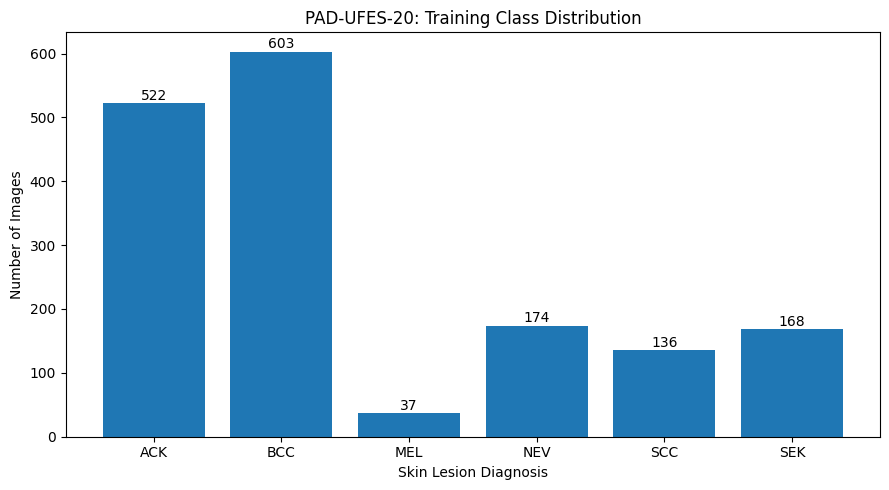

In [2]:
#SECTION 3 — EXPLORATORY DATA ANALYSIS

#3.1 Class Distribution

import matplotlib.pyplot as plt

#Use training data only

train_df =df[df["split"] == "train"].copy()

#Count images for each diagnostic class

class_counts= train_df["diagnostic"].value_counts().sort_index()
class_percentages =class_counts / len(train_df) * 100

class_summary =pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
    
})

print("Training class distribution:")
print(class_summary)

print("\nTotal training images:", len(train_df))
print("Number of classes:", train_df["diagnostic"].nunique())

#Visualise class imbalance

plt.figure(figsize=(9, 5))

bars= plt.bar(class_counts.index, class_counts.values)

plt.title("PAD-UFES-20: Training Class Distribution")

plt.xlabel("Skin Lesion Diagnosis")
plt.ylabel("Number of Images")

for bar, count in zip(bars, class_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(count),
        ha="center"
    )

plt.tight_layout()

#Save results for the final report

FIGURE_DIR = PROJECT_DIR / "project2_2_outputs" / "figures"
RESULTS_DIR = PROJECT_DIR / "project2_2_outputs" / "results"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(FIGURE_DIR / "class_distribution_train.png", dpi=300)
class_summary.to_csv(RESULTS_DIR / "class_counts_train.csv")

plt.show()


Training metadata missingness:
                     Missing (NaN)  Unknown (UNK)  Total Missing  Missing (%)
background_father              586             61            647        39.45
background_mother              588             53            641        39.09
smoke                          575              0            575        35.06
has_piped_water                575              0            575        35.06
diameter_2                     575              0            575        35.06
diameter_1                     575              0            575        35.06
drink                          575              0            575        35.06
has_sewage_system              575              0            575        35.06
fitspatrick                    575              0            575        35.06
cancer_history                 575              0            575        35.06
skin_cancer_history            575              0            575        35.06
gender                         57

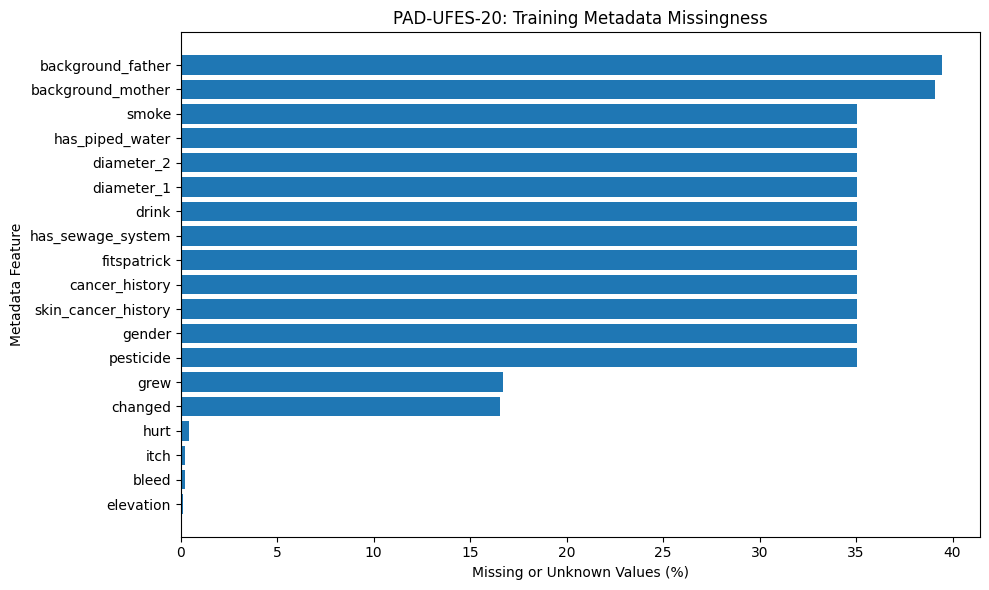

In [3]:
#SECTION 3 — EXPLORATORY DATA ANALYSIS

#3.2 Missing Metadata Assessment

#Exclude identifiers, target label and split information
exclude_cols =[
    "patient_id", "lesion_id", "img_id",
    "diagnostic", "split"
]

metadata_cols= [
    col for col in train_df.columns
    if col not in exclude_cols
]

#Count actual missing values
missing_count=train_df[metadata_cols].isna().sum()

#Count unknown categorical values recorded as "UNK" 

unknown_count= train_df[metadata_cols].apply(
    lambda col: col.astype("string").str.strip().str.upper().eq("UNK").sum()
)


#Create missing-data summary
missing_summary=pd.DataFrame({
    "Missing (NaN)": missing_count,
    "Unknown (UNK)": unknown_count
})

missing_summary["Total Missing"] = (
    missing_summary["Missing (NaN)"] +
    missing_summary["Unknown (UNK)"]
)

missing_summary["Missing (%)"] = (
    missing_summary["Total Missing"] / len(train_df) * 100
).round(2)

missing_summary=missing_summary.sort_values(
    "Missing (%)", ascending=False
)

print("Training metadata missingness:")
print(missing_summary.to_string())

print("\nColumns containing missing or unknown values:",
      (missing_summary["Total Missing"] > 0).sum())

#Plot missingness

plot_data = missing_summary[
    missing_summary["Missing (%)"] > 0
]

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index,
    plot_data["Missing (%)"]
)

plt.xlabel("Missing or Unknown Values (%)")
plt.ylabel("Metadata Feature")
plt.title("PAD-UFES-20: Training Metadata Missingness")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "metadata_missingness.png",
    dpi=300,
    bbox_inches="tight"
)

missing_summary.to_csv(
    RESULTS_DIR / "metadata_missingness_train.csv"
)

plt.show()


Identical missingness across 11 fields: True
Records with missing questionnaire data: 575

Questionnaire missingness by diagnosis:
            Total_Images  Missing_Images  Missing (%)
diagnostic                                           
ACK                  522             317        60.73
BCC                  603               0         0.00
MEL                   37               0         0.00
NEV                  174             121        69.54
SCC                  136               0         0.00
SEK                  168             137        81.55


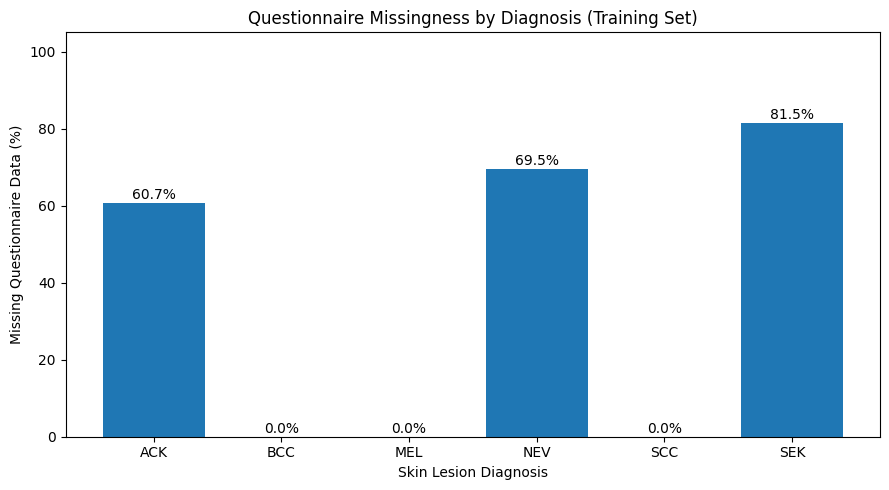

In [4]:
#SECTION 3 — EXPLORATORY DATA ANALYSIS

#3.3 Missingness by Diagnosis


#Check whether questionnaire fields have identical missingness

questionnaire_cols=[
    "smoke", "drink", "gender", "pesticide",
    "has_piped_water", "has_sewage_system",
    "fitspatrick", "diameter_1", "diameter_2",
    "cancer_history", "skin_cancer_history"
]

missing_mask=train_df["smoke"].isna()


same_pattern=all(
    train_df[col].isna().equals(missing_mask)
    for col in questionnaire_cols
)

print("Identical missingness across 11 fields:",same_pattern)
print("Records with missing questionnaire data:",missing_mask.sum())

#Analyse missingness by diagnosis

missing_by_class=train_df.assign(
    questionnaire_missing=missing_mask
).groupby("diagnostic").agg(
    Total_Images=("img_id", "size"),
    Missing_Images=("questionnaire_missing", "sum")
)

missing_by_class["Missing (%)"] = (
    missing_by_class["Missing_Images"] /
    missing_by_class["Total_Images"] * 100
).round(2)

print("\nQuestionnaire missingness by diagnosis:")
print("="*50)

print(missing_by_class.to_string())

#Visualise differences between diagnoses

plt.figure(figsize=(9, 5))

bars=plt.bar(
    missing_by_class.index,
    missing_by_class["Missing (%)"]
)

plt.title("Questionnaire Missingness by Diagnosis (Training Set)")
print("="*50)
plt.xlabel("Skin Lesion Diagnosis")
plt.ylabel("Missing Questionnaire Data (%)")
plt.ylim(0, 105)

for bar, value in zip(bars, missing_by_class["Missing (%)"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "missingness_by_diagnosis.png",
    dpi=300,
    bbox_inches="tight"
)

missing_by_class.to_csv(
    RESULTS_DIR / "missingness_by_diagnosis.csv"
)

plt.show()


Images examined: 1640
Image errors: 0

Image colour modes:
mode
RGBA    1034
RGB      606
Name: count, dtype: int64

Image dimensions:
         width   height
count  1640.00  1640.00
mean    925.78   925.80
std     526.59   526.63
min     167.00   167.00
25%     527.75   526.75
50%     783.50   783.00
75%    1205.25  1205.25
max    3474.00  3476.00

Aspect ratio:
count    1640.00
mean        1.00
std         0.01
min         0.89
25%         1.00
50%         1.00
75%         1.00
max         1.14
Name: aspect_ratio, dtype: float64


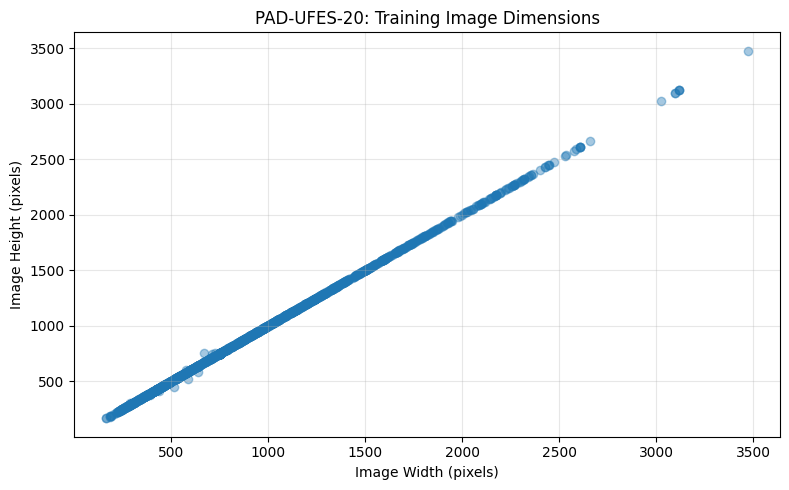

In [5]:
#SECTION 3 — EXPLORATORY DATA ANALYSIS

#3.4 Image Quality Assessment


from PIL import Image
from collections import Counter

#Match image filenames to their paths

image_lookup= {
    path.name: path for path in image_files
}

image_records=[]
image_errors=[]

# Examine training images

for img_id in train_df["img_id"]:

    filename=str(img_id)
    if not filename.lower().endswith(".png"):
        filename += ".png"

    try:
        with Image.open(image_lookup[filename]) as img:
            width, height=img.size
            mode=img.mode

            img.verify()

        image_records.append({
            "width": width,
            "height": height,
            "mode": mode,
            "aspect_ratio": width / height
        })

    except Exception as e:
        image_errors.append((filename, str(e)))

image_quality=pd.DataFrame(image_records)

print("Images examined:",len(image_records))
print("Image errors:",len(image_errors))
print("="*50)


print("\nImage colour modes:")

print(image_quality["mode"].value_counts())
print("="*50)

print("\nImage dimensions:")
print(image_quality[["width", "height"]].describe().round(2))
print("="*50)

print("\nAspect ratio:")
print(image_quality["aspect_ratio"].describe().round(2))
print("="*50)


#Visualise image dimensions
plt.figure(figsize=(8, 5))

plt.scatter(
    image_quality["width"],
    image_quality["height"],
    alpha=0.4
)

plt.title("PAD-UFES-20: Training Image Dimensions")
plt.xlabel("Image Width (pixels)")
plt.ylabel("Image Height (pixels)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "image_dimensions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Save summary statistics

image_quality.describe(include="all").to_csv(
    RESULTS_DIR / "image_quality_summary.csv"
)

if image_errors:
    print("\nImage errors:")
    print(image_errors[:10])


In [6]:
#SECTION 4 — DATA PREPROCESSING

#4.1 Image Preprocessing


import torch
from torchvision import transforms
from PIL import Image

#ImageNet normalisation parameters

IMAGE_SIZE= 224

IMAGE_MEAN= [0.485, 0.456, 0.406]
IMAGE_STD=[0.229, 0.224, 0.225]

#Deterministic image preprocessing
image_transform=transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGE_MEAN,
        std=IMAGE_STD
    )
])


#Select one training image to verify preprocessing

sample_id=str(train_df.iloc[0]["img_id"])

if not sample_id.lower().endswith(".png"):
    sample_id += ".png"

sample_path=image_lookup[sample_id]

with Image.open(sample_path) as img:
    
    print("Original image mode:", img.mode)
    print("Original image size:", img.size)

    #Convert all images to RGB
    rgb_image = img.convert("RGB")

    #Apply preprocessing
    image_tensor = image_transform(rgb_image)

print("\nAfter preprocessing:")
print("Image mode:", rgb_image.mode)
print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)
print("Minimum tensor value:", round(image_tensor.min().item(), 4))
print("Maximum tensor value:", round(image_tensor.max().item(), 4))

#Verify model input requirements
assert image_tensor.shape == (3, 224, 224)

print("\nImage preprocessing successful!")


Original image mode: RGBA
Original image size: (1325, 1325)

After preprocessing:
Image mode: RGB
Tensor shape: torch.Size([3, 224, 224])
Tensor dtype: torch.float32
Minimum tensor value: -1.493
Maximum tensor value: 1.5942

Image preprocessing successful!


In [7]:
# SECTION 4 — DATA PREPROCESSING
# 4.2 Clinical Metadata Preprocessing


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

#Conservative metadata features from the proposal

numeric_features=["age"]

categorical_features=[
    "region", "itch", "hurt", "bleed", "elevation"
]

metadata_features=numeric_features + categorical_features

#Separate training and validation data

validation_df=df[df["split"] == "validation"].copy()

X_train_metadata=train_df[metadata_features].copy()
X_val_metadata=validation_df[metadata_features].copy()

#Check for actual missing values

print("Training NaN values:", X_train_metadata.isna().sum().sum())
print("Validation NaN values:", X_val_metadata.isna().sum().sum())

#Create preprocessing pipeline
metadata_preprocessor=ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ]
)

#Fit on training data only
X_train_meta=metadata_preprocessor.fit_transform(
    X_train_metadata
)

#Apply the same preprocessing to validation data
X_val_meta=metadata_preprocessor.transform(
    X_val_metadata
)

print("\nMetadata preprocessing results:")
print("Training shape:", X_train_meta.shape)
print("Validation shape:", X_val_meta.shape)

print("\nTotal processed features:", X_train_meta.shape[1])

print("\nEncoded feature names:")

print(metadata_preprocessor.get_feature_names_out())

#Verify alignment and valid numerical output

import numpy as np

assert X_train_meta.shape[0] == len(train_df)
assert X_val_meta.shape[0] == len(validation_df)

assert np.isfinite(X_train_meta).all()
assert np.isfinite(X_val_meta).all()

print("\nMetadata preprocessing successful!" )


Training NaN values: 0
Validation NaN values: 0

Metadata preprocessing results:
Training shape: (1640, 27)
Validation shape: (329, 27)

Total processed features: 27

Encoded feature names:
['numeric__age' 'categorical__region_ABDOMEN' 'categorical__region_ARM'
 'categorical__region_BACK' 'categorical__region_CHEST'
 'categorical__region_EAR' 'categorical__region_FACE'
 'categorical__region_FOOT' 'categorical__region_FOREARM'
 'categorical__region_HAND' 'categorical__region_LIP'
 'categorical__region_NECK' 'categorical__region_NOSE'
 'categorical__region_SCALP' 'categorical__region_THIGH'
 'categorical__itch_False' 'categorical__itch_True'
 'categorical__itch_UNK' 'categorical__hurt_False'
 'categorical__hurt_True' 'categorical__hurt_UNK'
 'categorical__bleed_False' 'categorical__bleed_True'
 'categorical__bleed_UNK' 'categorical__elevation_False'
 'categorical__elevation_True' 'categorical__elevation_UNK']

Metadata preprocessing successful!



## Model Architecture and Multimodal Fusion Methods

### Modelling Strategy

Five principal modelling approaches were implemented to
investigate the contribution of visual and clinical information.

All approaches use the same patient disjoint data partitions.
Macro-F1 is the primary model selection metric because of
the imbalance between diagnostic classes.

The image encoder is frozen in all experiments. Therefore,
the trained image-based classifiers learn from pretrained
visual embeddings rather than fine-tuning the EfficientNet
backbone.

### 1. Metadata-Only Baseline

The metadata-only model uses six clinical attributes:

`age`, `region`, `itch`, `hurt`, `bleed`, `elevation`

These are transformed into 27 numerical features using
training fitted standardisation and one-hot encoding.

Multiclass logistic regression is used with balanced class
weights to reduce the influence of unequal class frequencies.

An initial classifier uses the default regularisation
parameter C=1. A separate regularised model selects C=0.01
using four-fold stratified patient-grouped cross validation.

Both configurations are retained for comparison.

### 2. Image-Only Baseline

Each lesion photograph is processed using a pretrained
EfficientNet B0 network with ImageNet weights.

The original classification layer is replaced by an identity
layer, producing a 1,280 dimensional image embedding.

A logistic regression classifier learns six-class predictions
from these frozen embeddings.

The image features are standardised inside the training
pipeline, and balanced class weights are used.

Four-fold patient-grouped cross-validation selects C=0.01
from the candidate values 0.001, 0.01, 0.1 and 1.0.

The regularised image-only model provides the principal
unimodal reference for assessing multimodal fusion.

### 3. Early Fusion — Feature-Level Integration

Early fusion combines the 1,280-dimensional visual
representation with six original clinical attributes before
classification.

The combined raw input contains 1,286 columns. Image
features and age are standardised, while categorical clinical
attributes are one-hot encoded within the model pipeline.

A class-balanced multiclass logistic regression classifier
is trained on the resulting joint representation.

Four-fold stratified patient grouped cross validation selects
C=0.01.

Early fusion enables the classifier to jointly use image-derived
features and clinical metadata within a single prediction model.

However, because the classifier uses linear logistic regression
on concatenated features, it primarily learns additive feature
contributions rather than explicit nonlinear cross-modal interactions.

The intermediate gatedfusion model is designed to capture
metadata-dependent modulation of visual representations.

A potential limitation is the large visual feature space,
which may dominate the lower-dimensional clinical modality
and increase overfitting risk.

### 4. Late Fusion — Decision-Level Integration

Late fusion combines the prediction probabilities of the
separately trained tuned image and tuned metadata models.

Patient-grouped out-of-fold predictions on the training
partition are used to search for fusion weights.

The selected combination is:

- Image model probability: 35%
- Metadata model probability: 65%

The final class is selected from the highest weighted
combined probability.

Late fusion preserves independent modality-specific models,
making their outputs easier to examine separately.

However, the fusion weights are selected using training
out-of-fold predictions, without nested cross-validation.
The weight-search score should therefore not be treated
as an unbiased performance estimate.

### 5. Intermediate Fusion — Metadata-Guided Gating

A simplified MetaBlock-inspired neural network is used
to investigate intermediate representation fusion.

The architecture contains:

- Image projection: 1,280 to 128 features, followed by ReLU.
- Metadata projection: 27 to 32 features, followed by ReLU.
- Metadata-guided gate: 32 to 128 features, followed by sigmoid.
- Joint representation: 160 features.
- Classifier: 160 to 64 to 6 outputs, with ReLU and dropout.

The learned metadata gates modulate the projected image
features before concatenation with the clinical representation.

Training uses class-weighted cross-entropy, the Adam
optimiser, learning rate 0.001, weight decay 0.001 and
batch size 64.

One internal patient-grouped validation fold was used for
early stopping. The selected training duration was four
epochs, after which the final network was trained on the
full training partition.

This is a simplified metadata-conditioned gating method,
not an exact reproduction of the published MetaBlock model.

### Model Selection and Evaluation Protocol

Training data and patient-grouped cross-validation were used
to fit models and select regularisation parameters.

The separate validation partition supported model comparison
and selection of the primary late-fusion model.

The held-out test partition was evaluated only after
configurations were locked.

All models were subsequently compared using accuracy,
balanced accuracy, macro-F1, per class recall, malignant
detection metrics and patient-level uncertainty estimates.

The limitations of validation reuse, minority class
imbalance and training overfitting are discussed in the
following evaluation sections.


In [8]:
#SECTION 5 — UNIMODAL BASELINE MODELS

#5.1 Metadata-Only Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)
import joblib

#Target labels
y_train=train_df["diagnostic"].values
y_val=validation_df["diagnostic"].values

#Metadata-only classifier
metadata_model=LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    random_state=42
)

#Train using processed metadata
metadata_model.fit(X_train_meta, y_train)

#Generate predictions
y_train_pred_meta=metadata_model.predict(X_train_meta)
y_val_pred_meta=metadata_model.predict(X_val_meta)

#Evaluate training and validation performance
def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(y_true, y_pred, average="macro")
    }

train_metrics=evaluate_model(y_train, y_train_pred_meta)
val_metrics=evaluate_model(y_val, y_val_pred_meta)

results_meta=pd.DataFrame(
    [train_metrics, val_metrics],
    index=["Training", "Validation"]
)

print("METADATA-ONLY LOGISTIC REGRESSION")


print("\nPerformance comparison:")
print(results_meta.round(4))

print("\nTraining - Validation Macro-F1 Difference:",
      round(train_metrics["Macro-F1"] - val_metrics["Macro-F1"], 4))

print("="*50)


print("\nValidation Classification Report:")
print(classification_report(
    y_val,
    y_val_pred_meta,
    zero_division=0
))

# Save evaluation results
results_meta.to_csv(
    RESULTS_DIR / "metadata_baseline_metrics.csv"
)

# Save validation predictions for later comparisons
pd.DataFrame({
    "img_id": validation_df["img_id"].values,
    "patient_id": validation_df["patient_id"].values,
    "Actual": y_val,
    "Predicted": y_val_pred_meta
}).to_csv(
    RESULTS_DIR / "metadata_validation_predictions.csv",
    index=False
)

# Save preprocessing and trained classifier
MODEL_DIR = PROJECT_DIR / "project2_2_outputs" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump({
    "preprocessor": metadata_preprocessor,
    "classifier": metadata_model
}, MODEL_DIR / "metadata_baseline.joblib")
print("="*50)


print("\nMetadata baseline completed and saved.")


METADATA-ONLY LOGISTIC REGRESSION

Performance comparison:
            Accuracy  Balanced Accuracy  Macro-F1
Training      0.6085             0.6461    0.5482
Validation    0.5745             0.6442    0.5252

Training - Validation Macro-F1 Difference: 0.023

Validation Classification Report:
              precision    recall  f1-score   support

         ACK       0.88      0.55      0.67       104
         BCC       0.80      0.55      0.65       121
         MEL       0.24      1.00      0.38         8
         NEV       0.67      0.74      0.70        35
         SCC       0.29      0.54      0.38        28
         SEK       0.29      0.48      0.36        33

    accuracy                           0.57       329
   macro avg       0.53      0.64      0.53       329
weighted avg       0.70      0.57      0.61       329


Metadata baseline completed and saved.


In [9]:
#SECTION 5 — UNIMODAL BASELINE MODELS

#5.2 EfficientNet-B0 Image Feature Extractor

import torch
import torchvision
from torch import nn
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

#Reproducibility
torch.manual_seed(42)

#Select available hardware

if torch.cuda.is_available():
    device=torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device=torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Selected device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

#Load pretrained ImageNet weights
weights=EfficientNet_B0_Weights.IMAGENET1K_V1

image_model=efficientnet_b0(weights=weights)

#Freeze pretrained parameters
for parameter in image_model.parameters():
    parameter.requires_grad = False

#Replace classification layer with identity
#Output will be 1280-dimensional image features

image_model.classifier = nn.Identity()

image_model = image_model.to(device)
image_model.eval()

#Verify feature dimensions

with torch.no_grad():
    sample_batch = image_tensor.unsqueeze(0).to(device)
    sample_features = image_model(sample_batch)

print("\nFeature extraction setup:")
print("Input shape:", sample_batch.shape)
print("Feature shape:", sample_features.shape)
print("Trainable parameters:",
      sum(p.numel() for p in image_model.parameters()
          if p.requires_grad))

assert sample_features.shape == (1, 1280)

print("\nEfficientNet-B0 setup successful!")


PyTorch version: 2.8.0+cpu
Torchvision version: 0.23.0+cpu
Selected device: cpu

Feature extraction setup:
Input shape: torch.Size([1, 3, 224, 224])
Feature shape: torch.Size([1, 1280])
Trainable parameters: 0

EfficientNet-B0 setup successful!


In [10]:
#SECTION 5 — UNIMODAL BASELINE MODELS

#5.3 EfficientNet-B0 Feature Extraction


import time
import numpy as np
from torch.utils.data import Dataset, DataLoader

#Dataset for loading and preprocessing images

class SkinLesionImageDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        img_id = str(self.dataframe.iloc[index]["img_id"])

        if not img_id.lower().endswith(".png"):
            img_id += ".png"

        image_path = image_lookup[img_id]

        with Image.open(image_path) as img:
            image= image_transform(img.convert("RGB"))

        return image


#Extract frozen CNN embeddings

def extract_image_features(dataframe, split_name):

    dataset=SkinLesionImageDataset(dataframe)

    loader=DataLoader(
        dataset,
        batch_size=16,
        shuffle=False,
        num_workers=0
    )

    features= []
    start_time= time.perf_counter()

    image_model.eval()

    with torch.inference_mode():

        for batch_number, images in enumerate(loader):
            

            images = images.to(device)

            batch_features = image_model(images)

            features.append(
                batch_features.cpu().numpy()
            )

            if (batch_number + 1) % 10 == 0:
                print(
                    f"{split_name}: "
                    f"{min((batch_number + 1) * 16, len(dataset))}"
                    f"/{len(dataset)} images processed"
                )

    features= np.concatenate(features, axis=0)

    elapsed= time.perf_counter() - start_time

    print(f"\n{split_name} completed.")
    print("Feature shape:", features.shape)
    print("Extraction time (seconds):", round(elapsed, 2))

    return features, elapsed


#Extract training features
X_train_img, train_extraction_time = extract_image_features(
    train_df,
    "Training"
)

#Extract validation features
X_val_img, val_extraction_time = extract_image_features(
    validation_df,
    "Validation"
)

#Verify feature dimensions and values
assert X_train_img.shape == (1640, 1280)
assert X_val_img.shape == (329, 1280)

assert np.isfinite(X_train_img).all()
assert np.isfinite(X_val_img).all()

#Save extracted features and their alignment information

CACHE_DIR = PROJECT_DIR / "project2_2_outputs" / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    CACHE_DIR / "efficientnet_b0_features.npz",
    X_train=X_train_img,
    X_val=X_val_img,
    train_ids=train_df["img_id"].astype(str).values,
    val_ids=validation_df["img_id"].astype(str).values,
    y_train=y_train,
    y_val=y_val
)

print("\nAll image features extracted and saved successfully !")
print("Training:",X_train_img.shape)
print("Validation:", X_val_img.shape)


Training: 160/1640 images processed
Training: 320/1640 images processed
Training: 480/1640 images processed
Training: 640/1640 images processed
Training: 800/1640 images processed
Training: 960/1640 images processed
Training: 1120/1640 images processed
Training: 1280/1640 images processed
Training: 1440/1640 images processed
Training: 1600/1640 images processed

Training completed.
Feature shape: (1640, 1280)
Extraction time (seconds): 327.94
Validation: 160/329 images processed
Validation: 320/329 images processed

Validation completed.
Feature shape: (329, 1280)
Extraction time (seconds): 68.44

All image features extracted and saved successfully !
Training: (1640, 1280)
Validation: (329, 1280)


In [11]:
#SECTION 5 — UNIMODAL BASELINE MODELS

#5.4 Image-Only Logistic Regression


import time
import numpy as np
import pandas as pd
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report


#1. Verify image and metadata sample alignment


assert len(X_train_img)==len(y_train)
assert len(X_val_img)==len(y_val)

#Load the locally created feature cache
with np.load(
    CACHE_DIR / "efficientnet_b0_features.npz",
    allow_pickle=True
) as cache:

    assert np.array_equal(
        cache["train_ids"].astype(str),
        train_df["img_id"].astype(str).values
    )

    assert np.array_equal(
        cache["val_ids"].astype(str),
        validation_df["img_id"].astype(str).values
    )

    assert np.array_equal(cache["y_train"], y_train)
    assert np.array_equal(cache["y_val"], y_val)

print("Image features and labels aligned successfully.")


#2. Create image-only classification pipeline


image_baseline=Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])


#3. Train the classifier


start_time=time.perf_counter()

image_baseline.fit(X_train_img, y_train)

training_time=time.perf_counter() - start_time


#4. Generate predictions


y_train_pred_img=image_baseline.predict(X_train_img)
y_val_pred_img=image_baseline.predict(X_val_img)


#5. Evaluate training and validation performance


train_metrics_img=evaluate_model(
    y_train, y_train_pred_img
)

val_metrics_img=evaluate_model(
    y_val, y_val_pred_img
)

results_img =pd.DataFrame(
    [train_metrics_img, val_metrics_img],
    index=["Training", "Validation"]
)


print("\nIMAGE-ONLY LOGISTIC REGRESSION")


print("\nPerformance comparison:")
print(results_img.round(4))

print("\nTraining - Validation Macro-F1 Difference:",
      round(
          train_metrics_img["Macro-F1"] -
          val_metrics_img["Macro-F1"], 4
      ))

print("\nClassifier training time (seconds):",
      round(training_time, 2))
print("="*50)


print("\nValidation Classification Report:")
print(classification_report(
    y_val,
    y_val_pred_img,
    zero_division=0
))

#6. Compare unimodal baselines


baseline_comparison=pd.DataFrame({
    "Metadata-only": val_metrics,
    "Image-only": val_metrics_img
}).T
print("="*50)

print("\nUNIMODAL BASELINE COMPARISON")


print(baseline_comparison.round(4))


#7. Save evaluation results


results_img.to_csv(
    RESULTS_DIR / "image_baseline_metrics.csv"
)

baseline_comparison.to_csv(
    RESULTS_DIR / "unimodal_baseline_comparison.csv"
)

#8. Save validation predictions and probabilities


image_probabilities= image_baseline.predict_proba(X_val_img)

class_names =image_baseline.classes_

image_predictions=pd.DataFrame({
    "img_id": validation_df["img_id"].values,
    "patient_id": validation_df["patient_id"].values,
    "Actual": y_val,
    "Predicted": y_val_pred_img
})

for i, class_name in enumerate(class_names):
    image_predictions[f"prob_{class_name}"] = (
        image_probabilities[:, i]
    )

image_predictions.to_csv(
    RESULTS_DIR / "image_validation_predictions.csv",
    index=False
)

#9. Save trained classifier


joblib.dump(
    image_baseline,
    MODEL_DIR / "image_baseline.joblib"
)

print("\nImage-only baseline completed and saved.")


Image features and labels aligned successfully.

IMAGE-ONLY LOGISTIC REGRESSION

Performance comparison:
            Accuracy  Balanced Accuracy  Macro-F1
Training      0.9939             0.9972    0.9949
Validation    0.5289             0.4172    0.4216

Training - Validation Macro-F1 Difference: 0.5733

Classifier training time (seconds): 1.61

Validation Classification Report:
              precision    recall  f1-score   support

         ACK       0.60      0.72      0.65       104
         BCC       0.63      0.55      0.59       121
         MEL       0.50      0.38      0.43         8
         NEV       0.51      0.51      0.51        35
         SCC       0.04      0.04      0.04        28
         SEK       0.31      0.30      0.31        33

    accuracy                           0.53       329
   macro avg       0.43      0.42      0.42       329
weighted avg       0.52      0.53      0.52       329


UNIMODAL BASELINE COMPARISON
               Accuracy  Balanced Accuracy  

In [12]:
#SECTION 5 — UNIMODAL BASELINE MODELS

#5.5 Image Model Regularisation and Cross-Validation

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

#Patient IDs for grouped cross-validation
groups_train=train_df["patient_id"].values

#Four fold patient-grouped cross-validation
cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

#Classification pipeline
image_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])

# Regularisation strengths
param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1.0]
}

# Search for the best regularisation strength
grid_search = GridSearchCV(
    estimator=image_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

grid_search.fit(
    X_train_img,
    y_train,
    groups=groups_train
)

#Cross validation results
cv_results=pd.DataFrame({
    "C": grid_search.cv_results_["param_classifier__C"],
    "Train Macro-F1": grid_search.cv_results_["mean_train_score"],
    "CV Macro-F1": grid_search.cv_results_["mean_test_score"],
    "CV Std": grid_search.cv_results_["std_test_score"]
})

print("IMAGE MODEL REGULARISATION RESULTS")
print(cv_results.round(4).to_string(index=False))

print("\nBest C:", grid_search.best_params_["classifier__C"])
print("Best CV Macro-F1:", round(grid_search.best_score_, 4))

#Best classifier refitted on full training data
image_tuned=grid_search.best_estimator_

y_train_pred_tuned=image_tuned.predict(X_train_img)
y_val_pred_tuned=image_tuned.predict(X_val_img)

train_metrics_tuned= evaluate_model(
    y_train, y_train_pred_tuned
)

val_metrics_tuned =evaluate_model(
    y_val, y_val_pred_tuned
)

tuned_results=pd.DataFrame(
    [train_metrics_tuned, val_metrics_tuned],
    index=["Training", "Validation"]
)
print("="*50)

print("\nTUNED IMAGE MODEL PERFORMANCE")
print(tuned_results.round(4))

print("\nOriginal validation Macro-F1:",
      round(val_metrics_img["Macro-F1"], 4))

print("Tuned validation Macro-F1:",
      round(val_metrics_tuned["Macro-F1"], 4))
print("="*50)

print("\nTuned Validation Classification Report:")
print(classification_report(
    y_val,
    y_val_pred_tuned,
    zero_division=0
))

#Save results and model
cv_results.to_csv(
    RESULTS_DIR / "image_regularisation_cv.csv",
    index=False
)

tuned_results.to_csv(
    RESULTS_DIR / "image_tuned_metrics.csv"
)

joblib.dump(
    image_tuned,
    MODEL_DIR / "image_tuned.joblib"
)
print("="*50)


print("\nImage model regularisation completed!")


IMAGE MODEL REGULARISATION RESULTS
     C  Train Macro-F1  CV Macro-F1  CV Std
 0.001          0.8144       0.5238  0.0506
  0.01          0.9735       0.5523  0.0425
   0.1          0.9947       0.5335  0.0354
   1.0          0.9949       0.5223  0.0369

Best C: 0.01
Best CV Macro-F1: 0.5523

TUNED IMAGE MODEL PERFORMANCE
            Accuracy  Balanced Accuracy  Macro-F1
Training      0.9512             0.9758    0.9656
Validation    0.5805             0.5249    0.5166

Original validation Macro-F1: 0.4216
Tuned validation Macro-F1: 0.5166

Tuned Validation Classification Report:
              precision    recall  f1-score   support

         ACK       0.62      0.71      0.66       104
         BCC       0.70      0.59      0.64       121
         MEL       0.62      0.62      0.62         8
         NEV       0.54      0.63      0.58        35
         SCC       0.16      0.14      0.15        28
         SEK       0.43      0.45      0.44        33

    accuracy                    

In [13]:
#SECTION 5 — UNIMODAL BASELINE MODELS

#5.6 Metadata Model Regularisation and Cross-Validation


from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


#1. Create metadata preprocessing pipeline


metadata_transformer=ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ]
)

metadata_pipeline=Pipeline([
    ("preprocessor", metadata_transformer),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])


#2. Configure patient-grouped cross-validation


cv_meta=StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

param_grid_meta= {
    "classifier__C": [0.001, 0.01, 0.1, 1.0]
}

grid_search_meta=GridSearchCV(
    estimator=metadata_pipeline,
    param_grid=param_grid_meta,
    scoring="f1_macro",
    cv=cv_meta,
    return_train_score=True,
    n_jobs=1
)


#3. Train using raw metadata


grid_search_meta.fit(
    X_train_metadata,
    y_train,
    groups=train_df["patient_id"].values
)


#4. Examine cross-validation results


cv_results_meta=pd.DataFrame({
    "C": grid_search_meta.cv_results_["param_classifier__C"],
    "Train Macro-F1": grid_search_meta.cv_results_["mean_train_score"],
    "CV Macro-F1": grid_search_meta.cv_results_["mean_test_score"],
    "CV Std": grid_search_meta.cv_results_["std_test_score"]
})

print("METADATA MODEL REGULARISATION RESULTS")

print(cv_results_meta.round(4).to_string(index=False))

print("\nBest C:", grid_search_meta.best_params_["classifier__C"])
print("Best CV Macro-F1:", round(grid_search_meta.best_score_, 4))


#5. Evaluate selected metadata model


metadata_tuned=grid_search_meta.best_estimator_

y_train_pred_meta_tuned=metadata_tuned.predict(
    X_train_metadata
)

y_val_pred_meta_tuned=metadata_tuned.predict(
    X_val_metadata
)

train_metrics_meta_tuned=evaluate_model(
    y_train, y_train_pred_meta_tuned
)

val_metrics_meta_tuned=evaluate_model(
    y_val, y_val_pred_meta_tuned
)

tuned_meta_results= pd.DataFrame(
    [train_metrics_meta_tuned, val_metrics_meta_tuned],
    index=["Training", "Validation"]
)
print("="*50)


print("\nTUNED METADATA MODEL PERFORMANCE")
print(tuned_meta_results.round(4))
print("="*50)


print("\nValidation Classification Report:")
print(classification_report(
    y_val,
    y_val_pred_meta_tuned,
    zero_division=0
))

#6. Compare tuned unimodal models

tuned_comparison=pd.DataFrame({
    "Metadata-only": val_metrics_meta_tuned,
    "Image-only": val_metrics_tuned
}).T
print("="*50)


print("\nTUNED UNIMODAL MODEL COMPARISON")
print(tuned_comparison.round(4))

# 7. Save results and model

cv_results_meta.to_csv(
    RESULTS_DIR / "metadata_regularisation_cv.csv",
    index=False
)

tuned_meta_results.to_csv(
    RESULTS_DIR / "metadata_tuned_metrics.csv"
)

tuned_comparison.to_csv(
    RESULTS_DIR / "tuned_unimodal_comparison.csv"
)

#Save validation predictions for later fusion analysis
metadata_probabilities_tuned = metadata_tuned.predict_proba(
    X_val_metadata
)

metadata_predictions_tuned = pd.DataFrame({
    "img_id": validation_df["img_id"].values,
    "patient_id": validation_df["patient_id"].values,
    "Actual": y_val,
    "Predicted": y_val_pred_meta_tuned
})

for i, class_name in enumerate(metadata_tuned.classes_):
    metadata_predictions_tuned[f"prob_{class_name}"] = (
        metadata_probabilities_tuned[:, i]
    )

metadata_predictions_tuned.to_csv(
    RESULTS_DIR / "metadata_tuned_validation_predictions.csv",
    index=False
)

joblib.dump(
    metadata_tuned,
    MODEL_DIR / "metadata_tuned.joblib"
)

print("\nMetadata model regularisation completed!")


METADATA MODEL REGULARISATION RESULTS
     C  Train Macro-F1  CV Macro-F1  CV Std
 0.001          0.4810       0.4667  0.0274
  0.01          0.5249       0.5009  0.0224
   0.1          0.5381       0.4973  0.0250
   1.0          0.5667       0.4799  0.0175

Best C: 0.01
Best CV Macro-F1: 0.5009

TUNED METADATA MODEL PERFORMANCE
            Accuracy  Balanced Accuracy  Macro-F1
Training      0.6000             0.6082    0.5255
Validation    0.5289             0.4743    0.4335

Validation Classification Report:
              precision    recall  f1-score   support

         ACK       0.88      0.55      0.67       104
         BCC       0.78      0.58      0.66       121
         MEL       0.08      0.38      0.14         8
         NEV       0.57      0.71      0.63        35
         SCC       0.22      0.36      0.27        28
         SEK       0.18      0.27      0.22        33

    accuracy                           0.53       329
   macro avg       0.45      0.47      0.43       

In [14]:
#SECTION 6 — MULTIMODAL FUSION

#6.1 Early Fusion: Feature Concatenation

import numpy as np
import pandas as pd
import time
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import classification_report


#1. Combine image embeddings and raw metadata


image_feature_cols=[
    f"image_{i:04d}"
    for i in range(X_train_img.shape[1])
]

train_image_features=pd.DataFrame(
    X_train_img,
    columns=image_feature_cols
)

val_image_features=pd.DataFrame(
    X_val_img,
    columns=image_feature_cols
)

X_train_early=pd.concat([
    train_image_features,
    X_train_metadata.reset_index(drop=True)
], axis=1)

X_val_early=pd.concat([
    val_image_features,
    X_val_metadata.reset_index(drop=True)
], axis=1)

print("EARLY FUSION INPUTS")
print("Training shape:", X_train_early.shape)
print("Validation shape:", X_val_early.shape)

assert len(X_train_early) == len(y_train)
assert len(X_val_early) == len(y_val)

#2. Create modality-specific preprocessing


early_preprocessor=ColumnTransformer(
    transformers=[
        ("image", StandardScaler(), image_feature_cols),

        ("numeric", StandardScaler(), numeric_features),

        ("categorical", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ],
    sparse_threshold=0
)

#3. Create early fusion classifier


early_pipeline = Pipeline([
    ("preprocessor", early_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])


#4. Patient-grouped cross-validation


cv_early=StratifiedGroupKFold(
    n_splits=4,
    
    shuffle=True,
    random_state=42
)

param_grid_early={
    "classifier__C": [0.001, 0.01, 0.1, 1.0]
}

early_grid=GridSearchCV(
    estimator=early_pipeline,
    param_grid=param_grid_early,
    scoring="f1_macro",
    cv=cv_early,
    return_train_score=True,
    n_jobs=1
)

#5. Train and tune early fusion model


start_time = time.perf_counter()

early_grid.fit(
    X_train_early,
    y_train,
    groups=train_df["patient_id"].values
)

early_training_time = time.perf_counter() - start_time

#6. Display cross-validation results


early_cv_results=pd.DataFrame({
    "C": early_grid.cv_results_["param_classifier__C"],
    "Train Macro-F1": early_grid.cv_results_["mean_train_score"],
    "CV Macro-F1": early_grid.cv_results_["mean_test_score"],
    "CV Std": early_grid.cv_results_["std_test_score"]
})
print("="*50)


print("\nEARLY FUSION CROSS-VALIDATION")
print(early_cv_results.round(4).to_string(index=False))

print("\nBest C:", early_grid.best_params_["classifier__C"])
print("Best CV Macro-F1:", round(early_grid.best_score_, 4))


#7. Evaluate training and validation performance


early_model=early_grid.best_estimator_

y_train_pred_early= early_model.predict(X_train_early)
y_val_pred_early =early_model.predict(X_val_early)

train_metrics_early=evaluate_model(
    y_train, y_train_pred_early
)

val_metrics_early=evaluate_model(
    y_val, y_val_pred_early
)

early_results =pd.DataFrame(
    [train_metrics_early, val_metrics_early],
    index=["Training", "Validation"]
)
print("="*50)


print("\nEARLY FUSION PERFORMANCE")


print(early_results.round(4))

print("\nTraining - Validation Macro-F1 Difference:",
      round(
          train_metrics_early["Macro-F1"] -
          val_metrics_early["Macro-F1"], 4
      ))

print("\nTotal tuning and training time (seconds):",
      round(early_training_time, 2))
print("="*50)


print("\nValidation Classification Report:")
print(classification_report(
    y_val,
    y_val_pred_early,
    zero_division=0
))


#8. Save results and trained model


early_cv_results.to_csv(
    RESULTS_DIR / "early_fusion_cv.csv",
    index=False
)

early_results.to_csv(
    RESULTS_DIR / "early_fusion_metrics.csv"
)

early_predictions=pd.DataFrame({
    "img_id": validation_df["img_id"].values,
    "patient_id": validation_df["patient_id"].values,
    "Actual": y_val,
    "Predicted": y_val_pred_early
})

early_probabilities=early_model.predict_proba(X_val_early)

for i, class_name in enumerate(early_model.classes_):
    early_predictions[f"prob_{class_name}"] = (
        early_probabilities[:, i]
    )

early_predictions.to_csv(
    RESULTS_DIR / "early_fusion_validation_predictions.csv",
    index=False
)

joblib.dump(
    early_model,
    MODEL_DIR / "early_fusion.joblib"
)

print("\nEarly fusion completed and saved successfully!")


EARLY FUSION INPUTS
Training shape: (1640, 1286)
Validation shape: (329, 1286)

EARLY FUSION CROSS-VALIDATION
     C  Train Macro-F1  CV Macro-F1  CV Std
 0.001          0.8328       0.5390  0.0445
  0.01          0.9778       0.5758  0.0418
   0.1          0.9961       0.5675  0.0220
   1.0          0.9979       0.5569  0.0318

Best C: 0.01
Best CV Macro-F1: 0.5758

EARLY FUSION PERFORMANCE
            Accuracy  Balanced Accuracy  Macro-F1
Training      0.9591             0.9798    0.9702
Validation    0.6292             0.5894    0.5766

Training - Validation Macro-F1 Difference: 0.3936

Total tuning and training time (seconds): 29.76

Validation Classification Report:
              precision    recall  f1-score   support

         ACK       0.67      0.74      0.70       104
         BCC       0.71      0.64      0.67       121
         MEL       0.67      0.75      0.71         8
         NEV       0.60      0.69      0.64        35
         SCC       0.21      0.18      0.19      

In [15]:
#SECTION 6 — MULTIMODAL FUSION

#6.2 Late Fusion: Weighted Probability Averaging


import numpy as np
import pandas as pd
import time
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, classification_report


#1. Set up patient-grouped cross-validation


cv_late= StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

groups_train= train_df["patient_id"].values
class_names= image_tuned.classes_

assert np.array_equal(
    class_names,
    metadata_tuned.classes_
)

#Store out-of-fold probabilities
oof_image= np.zeros((len(y_train), len(class_names)))
oof_metadata= np.zeros((len(y_train), len(class_names)))

start_time= time.perf_counter()


#2. Generate out-of-fold predictions


for fold, (train_idx, val_idx) in enumerate(
    cv_late.split(X_train_img, y_train, groups_train),
    start=1
):

    #Ensure no patient appears in both fold partitions
    assert not (
        set(groups_train[train_idx]) &
        set(groups_train[val_idx])
    )

    #Train image classifier within this fold
    fold_image_model = clone(image_tuned)

    fold_image_model.fit(
        X_train_img[train_idx],
        y_train[train_idx]
    )

    #Train metadata classifier within this fold\
    
    fold_metadata_model = clone(metadata_tuned)

    fold_metadata_model.fit(
        X_train_metadata.iloc[train_idx],
        
        y_train[train_idx]
    )

    assert np.array_equal(
        fold_image_model.classes_, class_names
    )
    assert np.array_equal(
        fold_metadata_model.classes_, class_names
    )

    #Predict probabilities on held-out fold
    
    oof_image[val_idx] = fold_image_model.predict_proba(
        X_train_img[val_idx]
    )

    oof_metadata[val_idx] = fold_metadata_model.predict_proba(
        X_train_metadata.iloc[val_idx]
    )

    print(f"Fold {fold} completed: {len(val_idx)} images")

oof_time = time.perf_counter() - start_time


# 3. Select fusion weight using OOF predictions


weight_results= []

for image_weight in np.linspace(0, 1, 21):

    metadata_weight= 1 - image_weight

    fused_probabilities= (
        image_weight * oof_image +
        metadata_weight * oof_metadata
    )

    fused_predictions= class_names[
        np.argmax(fused_probabilities, axis=1)
    ]

    score= f1_score(
        y_train,
        fused_predictions,
        average="macro"
    )

    weight_results.append({
        "Image Weight": image_weight,
        "Metadata Weight": metadata_weight,
        "OOF Macro-F1": score
    })

weight_results= pd.DataFrame(weight_results)

best_row= weight_results.loc[
    weight_results["OOF Macro-F1"].idxmax()
]

best_image_weight= float(best_row["Image Weight"])
best_metadata_weight= float(best_row["Metadata Weight"])
print("="*50)

print("\nLATE FUSION WEIGHT SELECTION")
print(weight_results.round(4).to_string(index=False))

print("\nBest image weight:", round(best_image_weight, 2))
print("Best metadata weight:", round(best_metadata_weight, 2))
print("Best OOF Macro-F1:", round(best_row["OOF Macro-F1"], 4))


#4. Apply selected weights to validation data


#Use models already fitted on the full training set
val_image_probs= image_tuned.predict_proba(X_val_img)

val_metadata_probs= metadata_tuned.predict_proba(
    X_val_metadata
)

late_probabilities= (
    best_image_weight * val_image_probs +
    best_metadata_weight * val_metadata_probs
)

y_val_pred_late= class_names[
    np.argmax(late_probabilities, axis=1)
]


#5. Evaluate late fusion


val_metrics_late=evaluate_model(
    y_val, y_val_pred_late
)
print("="*50)


print("\nLATE FUSION VALIDATION PERFORMANCE")
print(pd.Series(val_metrics_late).round(4))
print("="*50)

print("\nValidation Classification Report:")
print(classification_report(
    y_val,
    y_val_pred_late,
    zero_division=0
))

print("\nOOF training time (seconds):", round(oof_time, 2))

#6. Compare models


fusion_comparison=pd.DataFrame({
    "Original Metadata": val_metrics,
    "Tuned Metadata": val_metrics_meta_tuned,
    "Tuned Image": val_metrics_tuned,
    "Early Fusion": val_metrics_early,
    "Late Fusion": val_metrics_late
}).T
print("="*50)


print("\nMODEL COMPARISON")

print(fusion_comparison.round(4))


#7. Save results


weight_results.to_csv(
    RESULTS_DIR / "late_fusion_weight_search.csv",
    index=False
)

fusion_comparison.to_csv(
    RESULTS_DIR / "fusion_model_comparison.csv"
)

late_predictions = pd.DataFrame({
    "img_id": validation_df["img_id"].values,
    "patient_id": validation_df["patient_id"].values,
    "Actual": y_val,
    "Predicted": y_val_pred_late
})

for i, class_name in enumerate(class_names):
    late_predictions[f"prob_{class_name}"] = (
        late_probabilities[:, i]
    )

late_predictions.to_csv(
    RESULTS_DIR / "late_fusion_validation_predictions.csv",
    index=False
)

#Save late fusion configuration
joblib.dump({
    "image_model": image_tuned,
    "metadata_model": metadata_tuned,
    "image_weight": best_image_weight,
    "metadata_weight": best_metadata_weight,
    "classes": class_names
}, MODEL_DIR / "late_fusion.joblib")

print("\nLate fusion completed and saved successfully!")


Fold 1 completed: 390 images
Fold 2 completed: 409 images
Fold 3 completed: 425 images
Fold 4 completed: 416 images

LATE FUSION WEIGHT SELECTION
 Image Weight  Metadata Weight  OOF Macro-F1
         0.00             1.00        0.5037
         0.05             0.95        0.5196
         0.10             0.90        0.5271
         0.15             0.85        0.5415
         0.20             0.80        0.5687
         0.25             0.75        0.5835
         0.30             0.70        0.5962
         0.35             0.65        0.6060
         0.40             0.60        0.5999
         0.45             0.55        0.5985
         0.50             0.50        0.5969
         0.55             0.45        0.5876
         0.60             0.40        0.5764
         0.65             0.35        0.5754
         0.70             0.30        0.5717
         0.75             0.25        0.5686
         0.80             0.20        0.5653
         0.85             0.15        0.5578

In [16]:
#SECTION 6 — MULTIMODAL FUSION

#6.3 Intermediate Fusion: Metadata-Guided Gating


import torch
from torch import nn
import numpy as np

torch.manual_seed(42)

#1. Define metadata-guided fusion network


class MetadataGatedFusion(nn.Module):

    def __init__(self, image_dim, metadata_dim, num_classes):
        super().__init__()

        #Project image features into a smaller representation
        self.image_projection = nn.Sequential(
            nn.Linear(image_dim, 128),
            nn.ReLU()
        )

        #Project clinical metadata features
        self.metadata_projection = nn.Sequential(
            nn.Linear(metadata_dim, 32),
            nn.ReLU()
        )

        #Learn image-feature gates from metadata
        self.metadata_gate = nn.Sequential(
            nn.Linear(32, 128),
            nn.Sigmoid()
        )

        #Joint classifier
        self.classifier = nn.Sequential(
            nn.Linear(128 + 32, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, image_features, metadata_features):

        #Extract modality-specific representations
        image_repr = self.image_projection(image_features)
        metadata_repr = self.metadata_projection(metadata_features)

        #Modulate visual features using clinical metadata
        gates = self.metadata_gate(metadata_repr)
        gated_image = image_repr * (2.0 * gates)

        #Combine representations
        fused_features = torch.cat(
            [gated_image, metadata_repr],
            dim=1
        )

        #Produce classification logits
        return self.classifier(fused_features)


#2. Initialise network


num_classes = len(np.unique(y_train))

gated_model = MetadataGatedFusion(
    image_dim=X_train_img.shape[1],
    metadata_dim=X_train_meta.shape[1],
    num_classes=num_classes
).to(device)


#3. Verify the forward pass


sample_image = torch.tensor(
    X_train_img[:4],
    dtype=torch.float32,
    device=device
)

sample_metadata = torch.tensor(
    X_train_meta[:4],
    dtype=torch.float32,
    device=device
)

gated_model.eval()

with torch.no_grad():
    sample_logits = gated_model(
        sample_image,
        sample_metadata
    )

print("INTERMEDIATE FUSION ARCHITECTURE")

print("Image input:", sample_image.shape)
print("Metadata input:", sample_metadata.shape)
print("Output logits:", sample_logits.shape)

print("\nTrainable parameters:",
      sum(p.numel() for p in gated_model.parameters()
          if p.requires_grad))

assert sample_logits.shape == (4, num_classes)
assert torch.isfinite(sample_logits).all()

print("\nMetadata-guided fusion architecture verified!")


INTERMEDIATE FUSION ARCHITECTURE
Image input: torch.Size([4, 1280])
Metadata input: torch.Size([4, 27])
Output logits: torch.Size([4, 6])

Trainable parameters: 179782

Metadata-guided fusion architecture verified!


Internal training samples: 1331
Internal validation samples: 309
Patient overlap: 0
Epoch 01 | Train F1: 0.5204 | Validation F1: 0.3604
Epoch 05 | Train F1: 0.9418 | Validation F1: 0.4793
Epoch 10 | Train F1: 0.9971 | Validation F1: 0.4751

Early stopping triggered.

INTERMEDIATE FUSION TRAINING SUMMARY
Best epoch: 4
Best internal validation macro-F1: 0.5175
Training time (seconds): 6.05


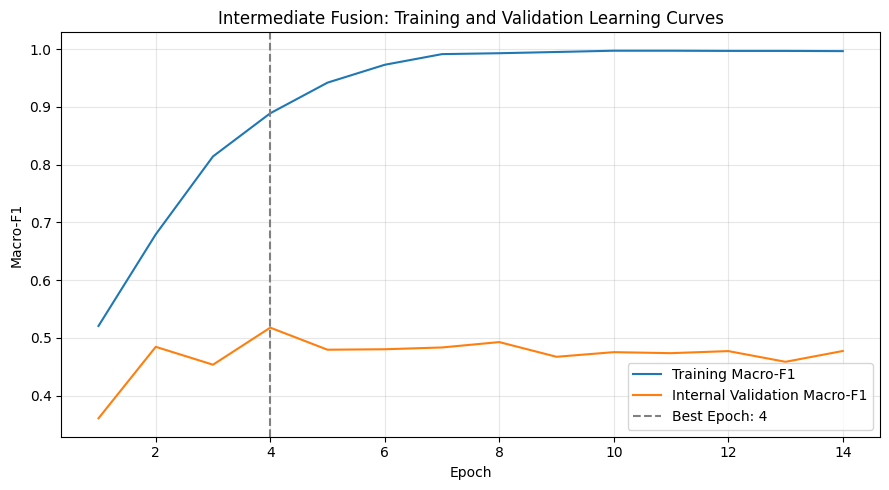


Intermediate fusion internal training completed!


In [17]:
#SECTION 6 — MULTIMODAL FUSION

#6.4 Intermediate Fusion: Training and Early Stopping


import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score

torch.manual_seed(42)
np.random.seed(42)


#1. Create patient-grouped internal split


inner_cv= StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_train_idx, inner_val_idx = next(
    inner_cv.split(
        X_train_img,
        y_train,
        groups_train
    )
)

assert not (
    set(groups_train[inner_train_idx]) &
    set(groups_train[inner_val_idx])
)

print("Internal training samples:", len(inner_train_idx))
print("Internal validation samples:", len(inner_val_idx))
print("Patient overlap: 0")


#2. Fit preprocessing on internal training data only

inner_image_scaler =StandardScaler()

inner_X_train_img= inner_image_scaler.fit_transform(
    X_train_img[inner_train_idx]
).astype(np.float32)

inner_X_val_img= inner_image_scaler.transform(
    X_train_img[inner_val_idx]
).astype(np.float32)

inner_meta_processor= ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_features)
])

inner_X_train_meta= inner_meta_processor.fit_transform(
    X_train_metadata.iloc[inner_train_idx]
).astype(np.float32)

inner_X_val_meta= inner_meta_processor.transform(
    X_train_metadata.iloc[inner_val_idx]
).astype(np.float32)

# Encode class labels
gated_classes= np.sort(np.unique(y_train))

label_to_index= {
    label: i for i, label in enumerate(gated_classes)
}

inner_y_train= np.array([
    label_to_index[label]
    for label in y_train[inner_train_idx]
])

inner_y_val= np.array([
    label_to_index[label]
    for label in y_train[inner_val_idx]
])

assert len(np.unique(inner_y_train)) == len(gated_classes)


#3. Convert arrays into PyTorch tensors


train_images_tensor= torch.tensor(inner_X_train_img)
train_metadata_tensor= torch.tensor(inner_X_train_meta)
train_labels_tensor= torch.tensor(inner_y_train, dtype=torch.long)

val_images_tensor= torch.tensor(inner_X_val_img)
val_metadata_tensor= torch.tensor(inner_X_val_meta)

train_dataset= TensorDataset(
    train_images_tensor,
    train_metadata_tensor,
    train_labels_tensor
)

train_loader= DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)


#4. Initialise network and training configuration


inner_model= MetadataGatedFusion(
    image_dim=inner_X_train_img.shape[1],
    metadata_dim=inner_X_train_meta.shape[1],
    num_classes=len(gated_classes)
).to(device)

class_weights= compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(gated_classes)),
    y=inner_y_train
)

criterion= nn.CrossEntropyLoss(
    weight=torch.tensor(
        class_weights,
        dtype=torch.float32,
        device=device
    )
)

optimizer= torch.optim.Adam(
    inner_model.parameters(),
    lr=0.001,
    weight_decay=0.001
)

MAX_EPOCHS= 60
PATIENCE= 10

best_val_f1= -1.0
best_epoch= 0
best_state= None
patience_counter= 0

training_history= []


#5. Train with early stopping


start_time= time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):

    inner_model.train()
    running_loss= 0.0

    for images, metadata, labels in train_loader:

        images= images.to(device)
        metadata= metadata.to(device)
        labels= labels.to(device)

        optimizer.zero_grad()

        outputs= inner_model(images, metadata)
        loss= criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(labels)

    #Evaluate without dropout
    inner_model.eval()

    with torch.inference_mode():

        train_predictions= inner_model(
            train_images_tensor.to(device),
            train_metadata_tensor.to(device)
        ).argmax(dim=1).cpu().numpy()

        val_predictions= inner_model(
            val_images_tensor.to(device),
            val_metadata_tensor.to(device)
        ).argmax(dim=1).cpu().numpy()

    train_f1= f1_score(
        inner_y_train,
        train_predictions,
        average="macro",
        labels=np.arange(len(gated_classes)),
        zero_division=0
    )

    val_f1= f1_score(
        inner_y_val,
        val_predictions,
        average="macro",
        labels=np.arange(len(gated_classes)),
        zero_division=0
    )

    training_history.append({
        "Epoch": epoch,
        "Training Loss": running_loss / len(train_dataset),
        "Training Macro-F1": train_f1,
        "Internal Validation Macro-F1": val_f1
    })

    if val_f1 > best_val_f1 + 0.0001:
        best_val_f1 = val_f1
        best_epoch = epoch
        best_state = copy.deepcopy(inner_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d} | "
            f"Train F1: {train_f1:.4f} | "
            f"Validation F1: {val_f1:.4f}"
        )

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

training_time_gated= time.perf_counter() - start_time


inner_model.load_state_dict(best_state)
print("="*50)


print("\nINTERMEDIATE FUSION TRAINING SUMMARY")

print("Best epoch:", best_epoch)
print("Best internal validation macro-F1:", round(best_val_f1, 4))
print("Training time (seconds):", round(training_time_gated, 2))


#6. Save and visualise learning curves


history_df= pd.DataFrame(training_history)

history_df.to_csv(
    RESULTS_DIR / "intermediate_fusion_learning_history.csv",
    index=False
)

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Training Macro-F1"],
    label="Training Macro-F1"
)

plt.plot(
    history_df["Epoch"],
    history_df["Internal Validation Macro-F1"],
    label="Internal Validation Macro-F1"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    color="gray",
    label=f"Best Epoch: {best_epoch}"
)

plt.title("Intermediate Fusion: Training and Validation Learning Curves")
plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "intermediate_fusion_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nIntermediate fusion internal training completed!")


In [18]:
#SECTION 6 — MULTIMODAL FUSION

#6.5 Intermediate Fusion: Final Training and Evaluation


import time
import numpy as np
import pandas as pd
import joblib
import torch

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report

#1. Set reproducibility and selected training duration


torch.manual_seed(42)
np.random.seed(42)

FINAL_EPOCHS= best_epoch

print("Selected training epochs:", FINAL_EPOCHS)


#2. Prepare image embeddings


#Fit image scaling on full training data only

final_image_scaler= StandardScaler()

X_train_img_scaled= final_image_scaler.fit_transform(
    X_train_img
).astype(np.float32)

X_val_img_scaled= final_image_scaler.transform(
    X_val_img
).astype(np.float32)

#Metadata was already fitted on training data in Step 7
X_train_meta_final = X_train_meta.astype(np.float32)
X_val_meta_final = X_val_meta.astype(np.float32)

assert X_train_meta_final.shape[1] == 27
assert X_val_meta_final.shape[1] == 27

# 3. Encode target labels


final_classes = np.sort(np.unique(y_train))

class_to_index = {
    label: i for i, label in enumerate(final_classes)
}

y_train_encoded = np.array([
    class_to_index[label] for label in y_train
])


# 4. Create training dataset


full_train_dataset= TensorDataset(
    torch.tensor(X_train_img_scaled),
    torch.tensor(X_train_meta_final),
    torch.tensor(y_train_encoded, dtype=torch.long)
)

full_train_loader = DataLoader(
    full_train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)


# 5. Initialise the final gated fusion model


gated_final = MetadataGatedFusion(
    image_dim=X_train_img_scaled.shape[1],
    metadata_dim=X_train_meta_final.shape[1],
    num_classes=len(final_classes)
).to(device)

# Class balanced loss
final_class_weights= compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(final_classes)),
    y=y_train_encoded
)

final_criterion= nn.CrossEntropyLoss(
    weight=torch.tensor(
        final_class_weights,
        dtype=torch.float32,
        device=device
    )
)

final_optimizer= torch.optim.Adam(
    gated_final.parameters(),
    lr=0.001,
    weight_decay=0.001
)


#6. Train on all 1,640 training samples


start_time = time.perf_counter()

for epoch in range(1, FINAL_EPOCHS + 1):

    gated_final.train()
    running_loss = 0.0

    for images, metadata, labels in full_train_loader:

        images= images.to(device)
        metadata= metadata.to(device)
        labels= labels.to(device)

        final_optimizer.zero_grad()

        outputs= gated_final(images, metadata)
        loss= final_criterion(outputs, labels)

        loss.backward()
        final_optimizer.step()

        running_loss += loss.item() * len(labels)

    epoch_loss= running_loss / len(full_train_dataset)

    print(
        f"Epoch {epoch}/{FINAL_EPOCHS} "
        f"| Training loss: {epoch_loss:.4f}"
    )

final_training_time= time.perf_counter() - start_time


#7. Generate predictions and probabilities


def gated_predict(model, image_data, metadata_data):

    model.eval()

    image_tensor= torch.tensor(
        image_data, dtype=torch.float32
    ).to(device)

    metadata_tensor= torch.tensor(
        metadata_data, dtype=torch.float32
    ).to(device)

    with torch.inference_mode():

        logits= model(image_tensor, metadata_tensor)

        probabilities= torch.softmax(
            logits, dim=1
        ).cpu().numpy()

    predictions= final_classes[
        np.argmax(probabilities, axis=1)
    ]

    return predictions, probabilities


y_train_pred_gated, train_probs_gated = gated_predict(
    gated_final,
    X_train_img_scaled,
    X_train_meta_final
)

y_val_pred_gated, val_probs_gated = gated_predict(
    gated_final,
    X_val_img_scaled,
    X_val_meta_final
)


#8. Evaluate training and validation performance


train_metrics_gated= evaluate_model(
    y_train, y_train_pred_gated
)

val_metrics_gated= evaluate_model(
    y_val, y_val_pred_gated
)

gated_results= pd.DataFrame(
    [train_metrics_gated, val_metrics_gated],
    index=["Training", "Validation"]
)

print("\nINTERMEDIATE GATED FUSION RESULTS")

print(gated_results.round(4))

print("\nTraining - Validation Macro-F1 Difference:",
      round(
          train_metrics_gated["Macro-F1"] -
          val_metrics_gated["Macro-F1"], 4
      ))

print("\nTraining time (seconds):",
      round(final_training_time, 2))

print("\nValidation Classification Report:")
print(classification_report(
    y_val,
    y_val_pred_gated,
    zero_division=0
))


#9. Compare all current models


fusion_comparison.loc[
    "Intermediate Gated"
] = pd.Series(val_metrics_gated)

print("\nALL MODEL VALIDATION COMPARISON")

print(
    fusion_comparison.sort_values(
        "Macro-F1", ascending=False
    ).round(4)
)


#10. Save model, preprocessing and evaluation results


gated_results.to_csv(
    RESULTS_DIR / "intermediate_fusion_metrics.csv"
)

fusion_comparison.to_csv(
    RESULTS_DIR / "all_fusion_model_comparison.csv"
)

gated_predictions= pd.DataFrame({
    "img_id": validation_df["img_id"].values,
    "patient_id": validation_df["patient_id"].values,
    "Actual": y_val,
    "Predicted": y_val_pred_gated
})

for i, class_name in enumerate(final_classes):
    gated_predictions[f"prob_{class_name}"] = (
        val_probs_gated[:, i]
    )

gated_predictions.to_csv(
    RESULTS_DIR / "intermediate_fusion_validation_predictions.csv",
    index=False
)

torch.save({
    "model_state_dict": gated_final.state_dict(),
    "image_dim": X_train_img_scaled.shape[1],
    "metadata_dim": X_train_meta_final.shape[1],
    "num_classes": len(final_classes),
    "classes": final_classes.tolist(),
    "epochs": FINAL_EPOCHS
}, MODEL_DIR / "intermediate_gated_fusion.pt")

joblib.dump({
    "image_scaler": final_image_scaler,
    "metadata_preprocessor": metadata_preprocessor
}, MODEL_DIR / "intermediate_gated_preprocessing.joblib")

print("\nIntermediate fusion completed and saved successfully!")


Selected training epochs: 4
Epoch 1/4 | Training loss: 1.6063
Epoch 2/4 | Training loss: 1.0418
Epoch 3/4 | Training loss: 0.6897
Epoch 4/4 | Training loss: 0.4657

INTERMEDIATE GATED FUSION RESULTS
            Accuracy  Balanced Accuracy  Macro-F1
Training      0.8890             0.9357    0.9048
Validation    0.5988             0.5817    0.5670

Training - Validation Macro-F1 Difference: 0.3378

Training time (seconds): 1.92

Validation Classification Report:
              precision    recall  f1-score   support

         ACK       0.66      0.68      0.67       104
         BCC       0.76      0.56      0.64       121
         MEL       0.71      0.62      0.67         8
         NEV       0.56      0.66      0.61        35
         SCC       0.26      0.36      0.30        28
         SEK       0.44      0.61      0.51        33

    accuracy                           0.60       329
   macro avg       0.57      0.58      0.57       329
weighted avg       0.63      0.60      0.61   

In [19]:
#SECTION 7 — COMPREHENSIVE MODEL EVALUATION

#7.1 Patient-Level Bootstrap Confidence Intervals


import numpy as np
import pandas as pd
from sklearn.metrics import f1_score


# 1. Collect validation predictions from all models


model_predictions = {
    "Original Metadata": y_val_pred_meta,
    "Tuned Metadata": y_val_pred_meta_tuned,
    "Tuned Image": y_val_pred_tuned,
    "Early Fusion": y_val_pred_early,
    "Late Fusion": y_val_pred_late,
    "Intermediate Gated": y_val_pred_gated
}

classes= np.sort(np.unique(y_train))

patient_ids = validation_df["patient_id"].to_numpy()
unique_patients = np.unique(patient_ids)

# Check predictions are aligned with validation labels
for name, predictions in model_predictions.items():
    assert len(predictions) == len(y_val), name

print("Validation images:", len(y_val))
print("Unique validation patients:", len(unique_patients))
print("Models compared:", len(model_predictions))


# 2. Create patient-level bootstrap samples


patient_indices = {
    patient: np.where(patient_ids == patient)[0]
    for patient in unique_patients
}

N_BOOTSTRAP = 5000
rng = np.random.default_rng(42)

bootstrap_scores = {
    name: []
    for name in model_predictions
}


# 3. Calculate bootstrap macro-F1


for iteration in range(N_BOOTSTRAP):

    sampled_patients = rng.choice(
        unique_patients,
        size=len(unique_patients),
        replace=True
    )

    sampled_indices = np.concatenate([
        patient_indices[patient]
        for patient in sampled_patients
    ])

    sampled_y = y_val[sampled_indices]

    for name, predictions in model_predictions.items():

        score = f1_score(
            sampled_y,
            predictions[sampled_indices],
            labels=classes,
            average="macro",
            zero_division=0
        )

        bootstrap_scores[name].append(score)

# 4. Summarise confidence intervals


ci_results = []

for name, scores in bootstrap_scores.items():

    scores= np.array(scores)

    lower, upper = np.percentile(
        scores, [2.5, 97.5]
    )

    observed_f1= f1_score(
        y_val,
        model_predictions[name],
        labels=classes,
        average="macro",
        zero_division=0
    )

    ci_results.append({
        "Model": name,
        "Macro-F1": observed_f1,
        "CI Lower": lower,
        "CI Upper": upper
    })

ci_results= pd.DataFrame(ci_results)

print("\nPATIENT-LEVEL BOOTSTRAP RESULTS")
print(ci_results.round(4).to_string(index=False))


# 5. Compare late fusion against other models


comparisons= [
    "Original Metadata",
    "Tuned Image",
    "Early Fusion",
    "Intermediate Gated"
]

difference_results= []

late_scores= np.array(bootstrap_scores["Late Fusion"])

for name in comparisons:

    differences = late_scores - np.array(
        bootstrap_scores[name]
    )

    lower, upper = np.percentile(
        differences, [2.5, 97.5]
    )

    observed_difference = (
        ci_results.loc[
            ci_results["Model"] == "Late Fusion",
            "Macro-F1"
        ].iloc[0]
        -
        ci_results.loc[
            ci_results["Model"] == name,
            "Macro-F1"
        ].iloc[0]
    )

    difference_results.append({
        "Comparison": "Late Fusion - " + name,
        "Difference": observed_difference,
        "CI Lower": lower,
        "CI Upper": upper
    })

difference_results= pd.DataFrame(difference_results)

print("\nPAIRED BOOTSTRAP DIFFERENCES")
print(difference_results.round(4).to_string(index=False))


# 6. Save results for the report


ci_results.to_csv(
    RESULTS_DIR / "patient_bootstrap_model_ci.csv",
    index=False
)

difference_results.to_csv(
    RESULTS_DIR / "patient_bootstrap_differences.csv",
    index=False
)

print("\nPatient-level bootstrap analysis completed!")


Validation images: 329
Unique validation patients: 196
Models compared: 6

PATIENT-LEVEL BOOTSTRAP RESULTS
             Model  Macro-F1  CI Lower  CI Upper
 Original Metadata    0.5252    0.4526    0.5920
    Tuned Metadata    0.4335    0.3688    0.4937
       Tuned Image    0.5166    0.4260    0.5780
      Early Fusion    0.5766    0.4753    0.6359
       Late Fusion    0.5794    0.5003    0.6432
Intermediate Gated    0.5670    0.4721    0.6319

PAIRED BOOTSTRAP DIFFERENCES
                      Comparison  Difference  CI Lower  CI Upper
 Late Fusion - Original Metadata      0.0542   -0.0134    0.1161
       Late Fusion - Tuned Image      0.0629    0.0067    0.1282
      Late Fusion - Early Fusion      0.0029   -0.0564    0.0743
Late Fusion - Intermediate Gated      0.0124   -0.0717    0.0923

Patient-level bootstrap analysis completed!


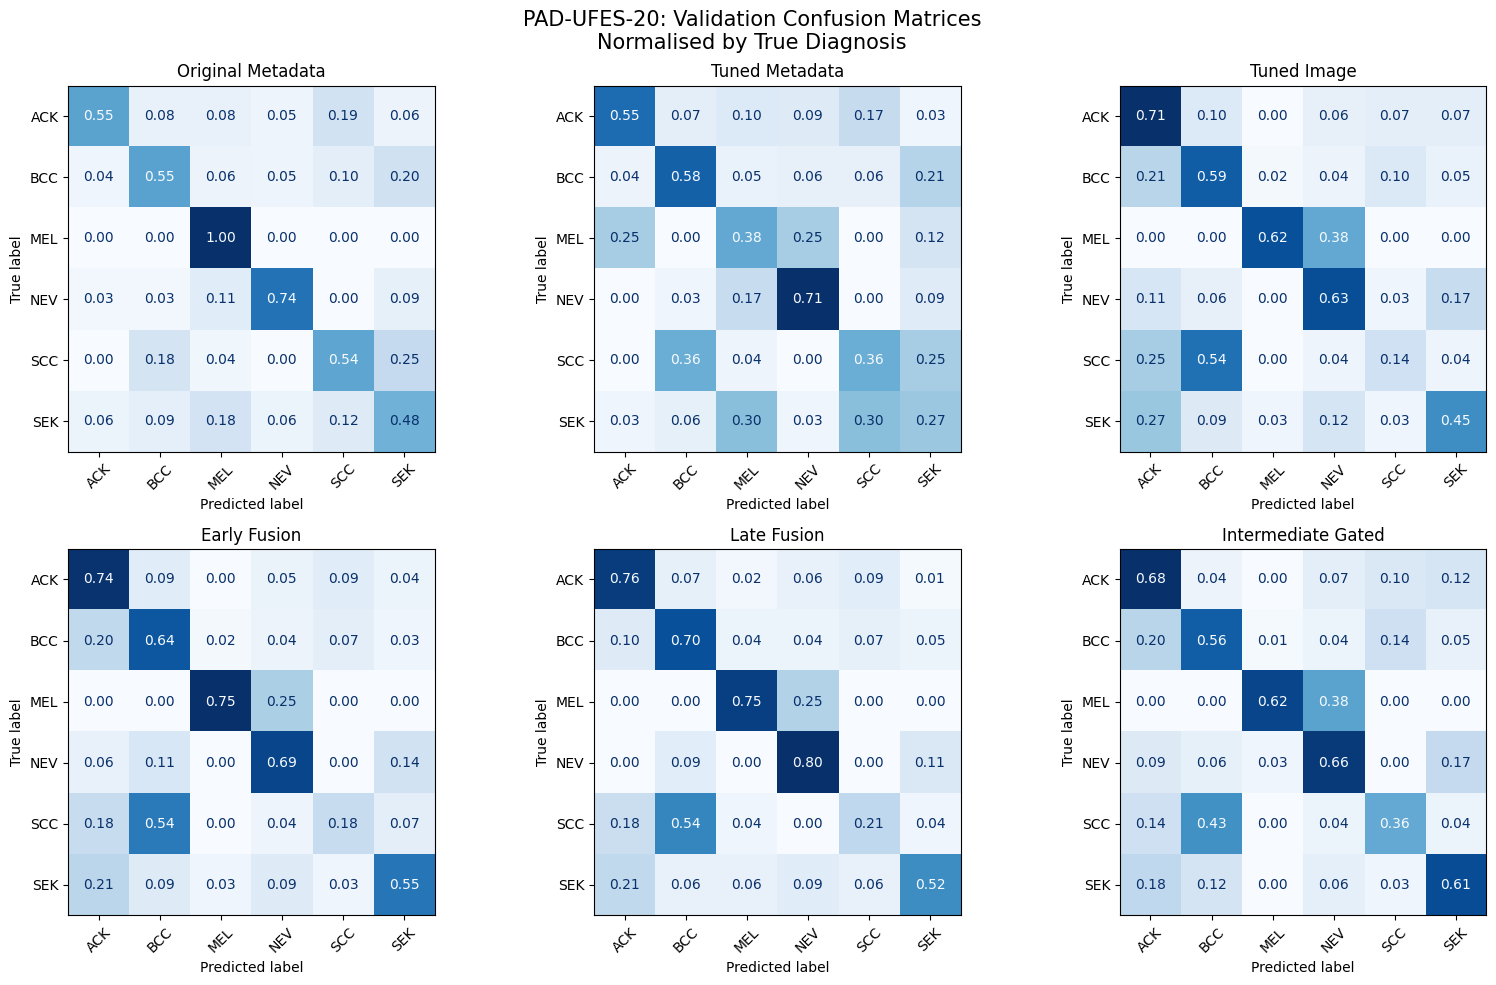

MELANOMA AND SCC RECALL COMPARISON
Diagnosis             MEL     SCC
Model                            
Early Fusion        0.750  0.1786
Intermediate Gated  0.625  0.3571
Late Fusion         0.750  0.2143
Original Metadata   1.000  0.5357
Tuned Image         0.625  0.1429
Tuned Metadata      0.375  0.3571

Confusion matrices and class metrics saved!


In [20]:
# SECTION 7 — COMPREHENSIVE MODEL EVALUATION

# 7.2 Confusion Matrices and Class-Specific Recall


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support
)


# 1. Generate normalised confusion matrices


fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

for ax, (model_name, predictions) in zip(
    axes.flat,
    model_predictions.items()
):

    cm= confusion_matrix(
        y_val,
        predictions,
        labels=classes,
        normalize="true"
    )

    display= ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format=".2f",
        colorbar=False
    )

    ax.set_title(model_name)
    ax.tick_params(axis="x", rotation=45)

fig.suptitle(
    "PAD-UFES-20: Validation Confusion Matrices\n"
    "Normalised by True Diagnosis",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "all_models_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#2. Calculate class-specific performance


class_results= []

for model_name, predictions in model_predictions.items():

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_val,
            predictions,
            labels=classes,
            zero_division=0
        )
    )

    for i, diagnosis in enumerate(classes):

        class_results.append({
            "Model": model_name,
            "Diagnosis": diagnosis,
            "Precision": precision[i],
            "Recall": recall[i],
            "F1": f1[i],
            "Support": support[i]
        })

class_results= pd.DataFrame(class_results)

# 3. Compare recall for high-risk diagnoses


high_risk_recall = class_results[
    class_results["Diagnosis"].isin(["MEL", "SCC"])
].pivot(
    index="Model",
    columns="Diagnosis",
    values="Recall"
)

print("MELANOMA AND SCC RECALL COMPARISON")
print(high_risk_recall.round(4))


# 4. Save evaluation results


class_results.to_csv(
    RESULTS_DIR / "all_models_per_class_metrics.csv",
    index=False
)

high_risk_recall.to_csv(
    RESULTS_DIR / "melanoma_scc_recall_comparison.csv"
)

print("\nConfusion matrices and class metrics saved!")


In [21]:
# SECTION 7 — COMPREHENSIVE MODEL EVALUATION

# 7.3 Failure-Case Analysis


import numpy as np
import pandas as pd

# 1. Collect validation predictions


failure_analysis = pd.DataFrame({
    "Actual": y_val,
    "Early Fusion": y_val_pred_early,
    "Late Fusion": y_val_pred_late,
    "Intermediate Gated": y_val_pred_gated
})

# Identify incorrect predictions
for model_name in [
    "Early Fusion",
    "Late Fusion",
    "Intermediate Gated"
]:
    failure_analysis[model_name + " Error"] = (
        failure_analysis[model_name] != failure_analysis["Actual"]
    )


# 2. Identify errors shared by all three fusion models


error_columns = [
    "Early Fusion Error",
    "Late Fusion Error",
    "Intermediate Gated Error"
]

failure_analysis["All Fusion Models Wrong"] = (
    failure_analysis[error_columns].all(axis=1)
)

print("FUSION MODEL FAILURE ANALYSIS")

for model_name in [
    "Early Fusion",
    "Late Fusion",
    "Intermediate Gated"
]:
    print(
        model_name,
        "errors:",
        failure_analysis[model_name + " Error"].sum()
    )

print("\nCases incorrectly classified by all three fusion models:",
      failure_analysis["All Fusion Models Wrong"].sum())

# 3. Analyse shared errors by diagnosis


shared_failures= failure_analysis.groupby(
    "Actual"
)["All Fusion Models Wrong"].agg(
    ["sum", "count"]
)

shared_failures["Failure Rate (%)"] = (
    shared_failures["sum"] /
    shared_failures["count"] * 100
).round(2)
print("="*50)


print("\nSHARED ERRORS BY DIAGNOSIS")
print(shared_failures.to_string())


# 4. Investigate important late-fusion confusions


late_errors= failure_analysis[
    failure_analysis["Late Fusion Error"]
].copy()

confusion_pairs= (
    late_errors.groupby(["Actual", "Late Fusion"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)
print("="*50)


print("\nMOST FREQUENT LATE-FUSION ERRORS")
print(confusion_pairs.head(10).to_string(index=False))

# 5. Identify high-confidence incorrect predictions


failure_analysis["Late Confidence"] = (
    late_probabilities.max(axis=1)
)

confident_errors= failure_analysis[
    failure_analysis["Late Fusion Error"]
].sort_values(
    "Late Confidence",
    ascending=False
)
print("="*50)

print("\nHIGH-CONFIDENCE LATE-FUSION ERRORS")

print(
    confident_errors[
        ["Actual", "Late Fusion", "Late Confidence"]
    ].head(10).round(4).to_string(index=False)
)

# 6. Save aggregate results


shared_failures.to_csv(
    RESULTS_DIR / "shared_fusion_failures.csv"
)

confusion_pairs.to_csv(
    RESULTS_DIR / "late_fusion_error_pairs.csv",
    index=False
)
print("="*50)


# No patient identifiers or raw images are exported here.

print("\nFailure-case analysis completed!")


FUSION MODEL FAILURE ANALYSIS
Early Fusion errors: 122
Late Fusion errors: 108
Intermediate Gated errors: 132

Cases incorrectly classified by all three fusion models: 83

SHARED ERRORS BY DIAGNOSIS
        sum  count  Failure Rate (%)
Actual                              
ACK      16    104             15.38
BCC      33    121             27.27
MEL       1      8             12.50
NEV       7     35             20.00
SCC      17     28             60.71
SEK       9     33             27.27

MOST FREQUENT LATE-FUSION ERRORS
Actual Late Fusion  Count
   SCC         BCC     15
   BCC         ACK     12
   ACK         SCC      9
   BCC         SCC      8
   ACK         BCC      7
   SEK         ACK      7
   ACK         NEV      6
   BCC         SEK      6
   SCC         ACK      5
   BCC         MEL      5

HIGH-CONFIDENCE LATE-FUSION ERRORS
Actual Late Fusion  Late Confidence
   SCC         BCC           0.6388
   SCC         BCC           0.5728
   BCC         SEK           0.5427
   AC

SCC predicted as BCC: 2
MEL predicted as NEV: 2


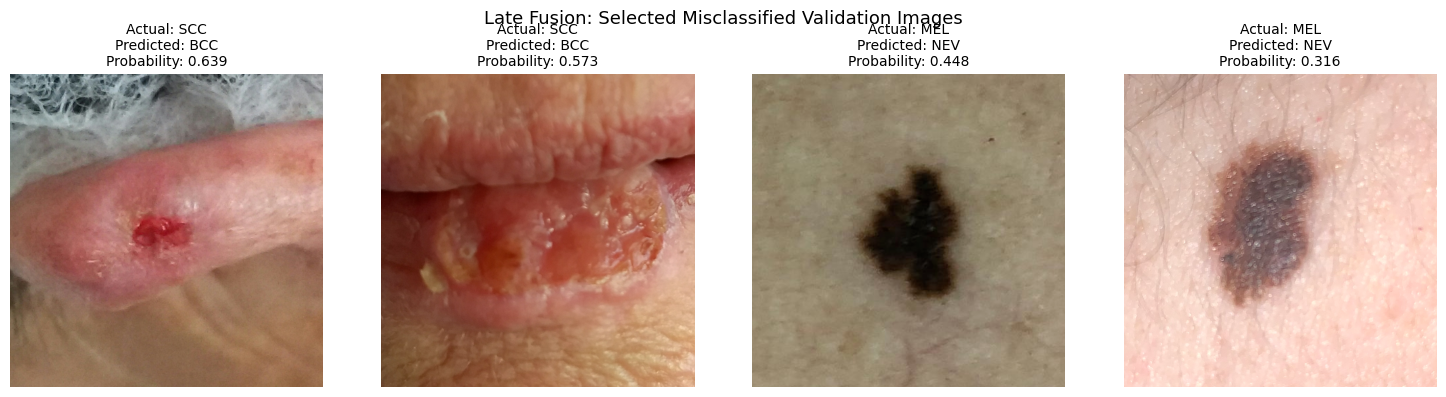


Visual failure-case inspection completed.
Clinical images are displayed locally,  no images exported.


In [22]:

# SECTION 7 — COMPREHENSIVE MODEL EVALUATION
# 7.4 Visual Inspection of Failure Cases

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Select important late-fusion errors

def select_failure_cases(actual, predicted, n=2):

    indices= np.where(
        (np.asarray(y_val) == actual) &
        (np.asarray(y_val_pred_late) == predicted)
    )[0]

    # Select cases with highest predicted probability
    indices = sorted(
        indices,
        key=lambda i: late_probabilities[i].max(),
        reverse=True
    )

    return indices[:n]


scc_errors= select_failure_cases("SCC", "BCC", 2)
mel_errors= select_failure_cases("MEL", "NEV", 2)

selected_indices= scc_errors + mel_errors

print("SCC predicted as BCC:", len(scc_errors))
print("MEL predicted as NEV:", len(mel_errors))

# 2. Visualise selected clinical images locally


fig, axes= plt.subplots(
    1, len(selected_indices),
    figsize=(15, 4)
)

axes= np.atleast_1d(axes)

for ax, index in zip(axes, selected_indices):

    img_id= str(validation_df.iloc[index]["img_id"])

    if not img_id.lower().endswith(".png"):
        img_id += ".png"

    image_path= image_lookup[img_id]

    with Image.open(image_path) as img:
        image= img.convert("RGB").copy()

    ax.imshow(image)
    ax.axis("off")

    actual = y_val[index]
    predicted = y_val_pred_late[index]
    confidence = late_probabilities[index].max()

    ax.set_title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Probability: {confidence:.3f}",
        fontsize=10
    )

plt.suptitle(
    "Late Fusion: Selected Misclassified Validation Images",
    fontsize=13
)

plt.tight_layout()
plt.show()

print("\nVisual failure-case inspection completed.")
print("Clinical images are displayed locally,  no images exported.")


In [23]:
# SECTION 8 — ABLATION STUDIES

# 8.1 Clinical Metadata Feature Ablation


import numpy as np
import pandas as pd
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    recall_score
)

# 1. Define metadata feature configurations


feature_sets = {
    "Basic (2)": [
        "age", "region"
    ],
    "Conservative (6)": [
        "age", "region", "itch",
        "hurt", "bleed", "elevation"
    ],
    "Expanded (8)": [
        "age", "region", "itch",
        "hurt", "bleed", "elevation",
        "grew", "changed"
    ]
}

# Same patient-grouped folds for every configuration

cv_ablation = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

groups= train_df["patient_id"].values
folds= list(cv_ablation.split(
    train_df, y_train, groups
))

ablation_results = []
ablation_fold_results = []


# 2. Evaluate each feature configuration


for name, features in feature_sets.items():

    numeric_cols = ["age"]
    categorical_cols = [
        col for col in features if col != "age"
    ]

    preprocessor = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_cols),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_cols)
    ])

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            C=0.01,
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    fold_scores = []

    # Patient-grouped cross-validation
    
    for fold_number, (tr_idx, va_idx) in enumerate(folds, 1):

        assert not (
            set(groups[tr_idx]) & set(groups[va_idx])
        )

        pipeline.fit(
            train_df.iloc[tr_idx][features],
            y_train[tr_idx]
        )

        predictions = pipeline.predict(
            train_df.iloc[va_idx][features]
        )

        score = f1_score(
            y_train[va_idx],
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )

        fold_scores.append(score)

        ablation_fold_results.append({
            "Configuration": name,
            "Fold": fold_number,
            "Macro-F1": score
        })

    # Refit using the full training partition
    
    pipeline.fit(train_df[features], y_train)

    val_predictions = pipeline.predict(
        validation_df[features]
    )

    val_f1 = f1_score(
        y_val,
        val_predictions,
        labels=classes,
        average="macro",
        zero_division=0
    )

    val_balanced = balanced_accuracy_score(
        y_val, val_predictions
    )

    mel_recall = recall_score(
        y_val == "MEL",
        val_predictions == "MEL"
    )

    scc_recall = recall_score(
        y_val == "SCC",
        val_predictions == "SCC"
    )

    ablation_results.append({
        "Configuration": name,
        "CV Macro-F1": np.mean(fold_scores),
        "CV Std": np.std(fold_scores),
        "Validation Macro-F1": val_f1,
        "Balanced Accuracy": val_balanced,
        "MEL Recall": mel_recall,
        "SCC Recall": scc_recall
    })

    print(f"{name} completed.")

    # Save model for reproducibility
    filename = name.split()[0].lower()

    joblib.dump(
        pipeline,
        MODEL_DIR / f"metadata_ablation_{filename}.joblib"
    )

# 3. Compare configurations


ablation_df = pd.DataFrame(ablation_results)

print("\nMETADATA ABLATION RESULTS")

print(ablation_df.round(4).to_string(index=False))

# 4. Save results


ablation_df.to_csv(
    RESULTS_DIR / "metadata_ablation_results.csv",
    index=False
)

pd.DataFrame(ablation_fold_results).to_csv(
    RESULTS_DIR / "metadata_ablation_fold_results.csv",
    index=False
)

print("\nMetadata ablation completed successfully!")


Basic (2) completed.
Conservative (6) completed.
Expanded (8) completed.

METADATA ABLATION RESULTS
   Configuration  CV Macro-F1  CV Std  Validation Macro-F1  Balanced Accuracy  MEL Recall  SCC Recall
       Basic (2)       0.2982  0.0179               0.3286             0.4688       0.625      0.5000
Conservative (6)       0.5009  0.0224               0.4335             0.4743       0.375      0.3571
    Expanded (8)       0.5425  0.0156               0.5152             0.5831       0.625      0.3929

Metadata ablation completed successfully!


In [24]:

# ============================================================
# SECTION 8 — ABLATION STUDIES
# 8.2 Expanded Metadata Missingness by Diagnosis
# ============================================================

import pandas as pd

expanded_features = ["grew", "changed"]

unknown_results = []

# Examine unknown responses within each diagnostic class
for feature in expanded_features:

    for diagnosis, group in train_df.groupby("diagnostic"):

        unknown_count = (
            group[feature]
            .astype("string")
            .str.strip()
            .str.upper()
            .eq("UNK")
            .sum()
        )

        unknown_results.append({
            "Feature": feature,
            "Diagnosis": diagnosis,
            "Total Images": len(group),
            "Unknown Count": unknown_count,
            "Unknown (%)": round(
                unknown_count / len(group) * 100, 2
            )
        })

unknown_df = pd.DataFrame(unknown_results)

print("EXPANDED METADATA UNKNOWN VALUES BY DIAGNOSIS")
print(unknown_df.to_string(index=False))

# Compare percentages across diagnoses
unknown_pivot = unknown_df.pivot(
    index="Diagnosis",
    columns="Feature",
    values="Unknown (%)"
)

print("\nUNKNOWN PERCENTAGE COMPARISON")
print(unknown_pivot.to_string())

# Save for the ethics and ablation sections
unknown_df.to_csv(
    RESULTS_DIR / "expanded_metadata_unknown_analysis.csv",
    index=False
)

print("\nExpanded metadata missingness analysis completed!")


EXPANDED METADATA UNKNOWN VALUES BY DIAGNOSIS
Feature Diagnosis  Total Images  Unknown Count  Unknown (%)
   grew       ACK           522              3         0.57
   grew       BCC           603            181        30.02
   grew       MEL            37              7        18.92
   grew       NEV           174             25        14.37
   grew       SCC           136             51        37.50
   grew       SEK           168              7         4.17
changed       ACK           522              1         0.19
changed       BCC           603            181        30.02
changed       MEL            37              6        16.22
changed       NEV           174             25        14.37
changed       SCC           136             51        37.50
changed       SEK           168              7         4.17

UNKNOWN PERCENTAGE COMPARISON
Feature    changed   grew
Diagnosis                
ACK           0.19   0.57
BCC          30.02  30.02
MEL          16.22  18.92
NEV          

In [25]:
# SECTION 8 — ABLATION STUDIES
# 8.2 Expanded Metadata Missingness by Diagnosis


import pandas as pd

expanded_features = ["grew", "changed"]

unknown_results= []

# Examine unknown responses within each diagnostic class
for feature in expanded_features:

    for diagnosis, group in train_df.groupby("diagnostic"):

        unknown_count = (
            group[feature]
            .astype("string")
            .str.strip()
            .str.upper()
            .eq("UNK")
            .sum()
        )

        unknown_results.append({
            "Feature": feature,
            "Diagnosis": diagnosis,
            "Total Images": len(group),
            "Unknown Count": unknown_count,
            "Unknown (%)": round(
                unknown_count / len(group) * 100, 2
            )
        })

unknown_df = pd.DataFrame(unknown_results)
print("="*50)


print("EXPANDED METADATA UNKNOWN VALUES BY DIAGNOSIS")
print(unknown_df.to_string(index=False))

# Compare percentages across diagnoses
unknown_pivot= unknown_df.pivot(
    index="Diagnosis",
    columns="Feature",
    values="Unknown (%)"
)
print("="*50)

print("\nUNKNOWN PERCENTAGE COMPARISON")
print(unknown_pivot.to_string())

# Save for the ethics and ablation sections

unknown_df.to_csv(
    RESULTS_DIR / "expanded_metadata_unknown_analysis.csv",
    index=False
)
print("="*50)

print("\nExpanded metadata missingness analysis completed!")


EXPANDED METADATA UNKNOWN VALUES BY DIAGNOSIS
Feature Diagnosis  Total Images  Unknown Count  Unknown (%)
   grew       ACK           522              3         0.57
   grew       BCC           603            181        30.02
   grew       MEL            37              7        18.92
   grew       NEV           174             25        14.37
   grew       SCC           136             51        37.50
   grew       SEK           168              7         4.17
changed       ACK           522              1         0.19
changed       BCC           603            181        30.02
changed       MEL            37              6        16.22
changed       NEV           174             25        14.37
changed       SCC           136             51        37.50
changed       SEK           168              7         4.17

UNKNOWN PERCENTAGE COMPARISON
Feature    changed   grew
Diagnosis                
ACK           0.19   0.57
BCC          30.02  30.02
MEL          16.22  18.92
NEV          

In [26]:
# SECTION 8 — ABLATION STUDIES
# 8.3 Missingness Shortcut Ablation


import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, balanced_accuracy_score


# 1. Create missingness indicator features


conservative_features = [
    "age", "region", "itch",
    "hurt", "bleed", "elevation"
]

X_train_shortcut = train_df[conservative_features].copy()
X_val_shortcut = validation_df[conservative_features].copy()

for feature in ["grew", "changed"]:

    new_column = feature + "_unknown"

    X_train_shortcut[new_column] = (
        train_df[feature].astype("string")
        .str.strip().str.upper().eq("UNK")
        .astype(int)
    )

    X_val_shortcut[new_column] = (
        validation_df[feature].astype("string")
        .str.strip().str.upper().eq("UNK")
        .astype(int)
    )

indicator_features = ["grew_unknown", "changed_unknown"]

# 2. Create training-only preprocessing pipeline


shortcut_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), ["age"]),

    ("categorical", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_features),

    ("missingness", "passthrough", indicator_features)
])

shortcut_model = Pipeline([
    ("preprocessor", shortcut_preprocessor),
    ("classifier", LogisticRegression(
        C=0.01,
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])

# 3. Patient-grouped cross-validation


cv_shortcut = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

shortcut_scores = []

for train_idx, val_idx in cv_shortcut.split(
    X_train_shortcut,
    y_train,
    train_df["patient_id"].values
):

    shortcut_model.fit(
        X_train_shortcut.iloc[train_idx],
        y_train[train_idx]
    )

    predictions = shortcut_model.predict(
        X_train_shortcut.iloc[val_idx]
    )

    shortcut_scores.append(
        f1_score(
            y_train[val_idx],
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )
    )

# 4. Fit on full training set and evaluate validation


shortcut_model.fit(X_train_shortcut, y_train)

y_val_pred_shortcut = shortcut_model.predict(
    X_val_shortcut
)

shortcut_cv_f1 = np.mean(shortcut_scores)

shortcut_val_f1 = f1_score(
    y_val,
    y_val_pred_shortcut,
    labels=classes,
    average="macro",
    zero_division=0
)

# 5. Compare against previous metadata ablations


shortcut_result = pd.DataFrame([{
    "Configuration": "Conservative + UNK indicators",
    "CV Macro-F1": shortcut_cv_f1,
    "CV Std": np.std(shortcut_scores),
    "Validation Macro-F1": shortcut_val_f1,
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, y_val_pred_shortcut
    )
}])

comparison = pd.concat([
    ablation_df[[
        "Configuration",
        "CV Macro-F1",
        "CV Std",
        "Validation Macro-F1",
        "Balanced Accuracy"
    ]],
    shortcut_result
], ignore_index=True)

print("METADATA MISSINGNESS ABLATION")
print(comparison.round(4).to_string(index=False))

comparison.to_csv(
    RESULTS_DIR / "metadata_missingness_ablation.csv",
    index=False
)

print("\nMissingness shortcut ablation completed!")


METADATA MISSINGNESS ABLATION
                Configuration  CV Macro-F1  CV Std  Validation Macro-F1  Balanced Accuracy
                    Basic (2)       0.2982  0.0179               0.3286             0.4688
             Conservative (6)       0.5009  0.0224               0.4335             0.4743
                 Expanded (8)       0.5425  0.0156               0.5152             0.5831
Conservative + UNK indicators       0.5049  0.0209               0.4721             0.5329

Missingness shortcut ablation completed!


Malignant validation images: 157
Other validation images: 172

MALIGNANT LESION DETECTION PERFORMANCE
             Model  Sensitivity  Specificity  False Negatives  False Positives  True Positives  True Negatives
 Original Metadata       0.7325       0.6860               42               54             115             118
    Tuned Metadata       0.6815       0.6279               50               64             107             108
       Tuned Image       0.6943       0.8547               48               25             109             147
      Early Fusion       0.7261       0.8430               43               27             114             145
       Late Fusion       0.8025       0.8430               31               27             126             145
Intermediate Gated       0.7197       0.8721               44               22             113             150


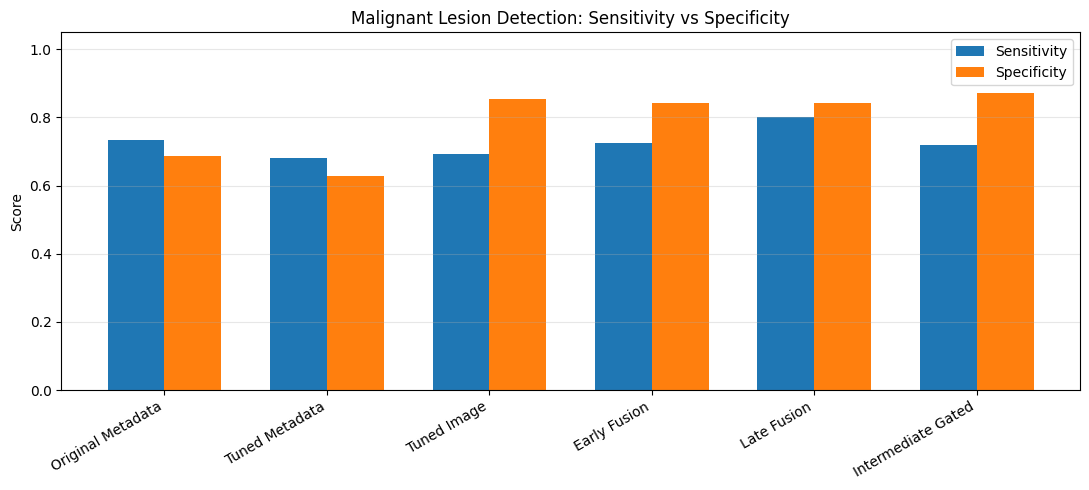


Malignant lesion evaluation completed!


In [27]:
# SUPPLEMENTARY EVALUATION — MALIGNANT LESION ANALYSIS
# Malignant Lesion Sensitivity and Specificity

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1. Define malignant diagnostic classes


malignant_classes = ["BCC", "MEL", "SCC"]

# ACK is premalignant and grouped with "Other" here.
y_val_binary= np.isin(y_val, malignant_classes)

print("Malignant validation images:", y_val_binary.sum())
print("Other validation images:", (~y_val_binary).sum())

# 2. Calculate binary evaluation metrics


malignant_results= []

for model_name, predictions in model_predictions.items():

    pred_binary= np.isin(predictions, malignant_classes)

    tn, fp, fn, tp= confusion_matrix(
        y_val_binary,
        pred_binary,
        labels=[False, True]
    ).ravel()

    sensitivity= tp / (tp + fn)
    specificity = tn / (tn + fp)

    malignant_results.append({
        "Model": model_name,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "False Negatives": fn,
        "False Positives": fp,
        "True Positives": tp,
        "True Negatives": tn
    })

malignant_df= pd.DataFrame(malignant_results)

# 3. Display comparison
print("="*50)


print("\nMALIGNANT LESION DETECTION PERFORMANCE")

print(malignant_df.round(4).to_string(index=False))


# 4. Visualise sensitivity and specificity


x= np.arange(len(malignant_df))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(
    x - width / 2,
    malignant_df["Sensitivity"],
    width,
    label="Sensitivity"
)

plt.bar(
    x + width / 2,
    malignant_df["Specificity"],
    width,
    label="Specificity"
)

plt.xticks(
    x,
    malignant_df["Model"],
    rotation=30,
    ha="right"
)

plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.title("Malignant Lesion Detection: Sensitivity vs Specificity")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "malignant_sensitivity_specificity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Save evaluation results


malignant_df.to_csv(
    RESULTS_DIR / "malignant_detection_metrics.csv",
    index=False
)

print("\nMalignant lesion evaluation completed!")


MALIGNANT PREDICTION PROBABILITY EVALUATION
             Model  ROC-AUC  Average Precision  Brier Score
 Original Metadata   0.8121             0.8169       0.1815
    Tuned Metadata   0.7892             0.7992       0.1973
       Tuned Image   0.8473             0.8330       0.1621
      Early Fusion   0.8745             0.8628       0.1451
       Late Fusion   0.8865             0.8758       0.1635
Intermediate Gated   0.8564             0.8509       0.1554

Malignant class prevalence: 0.4772


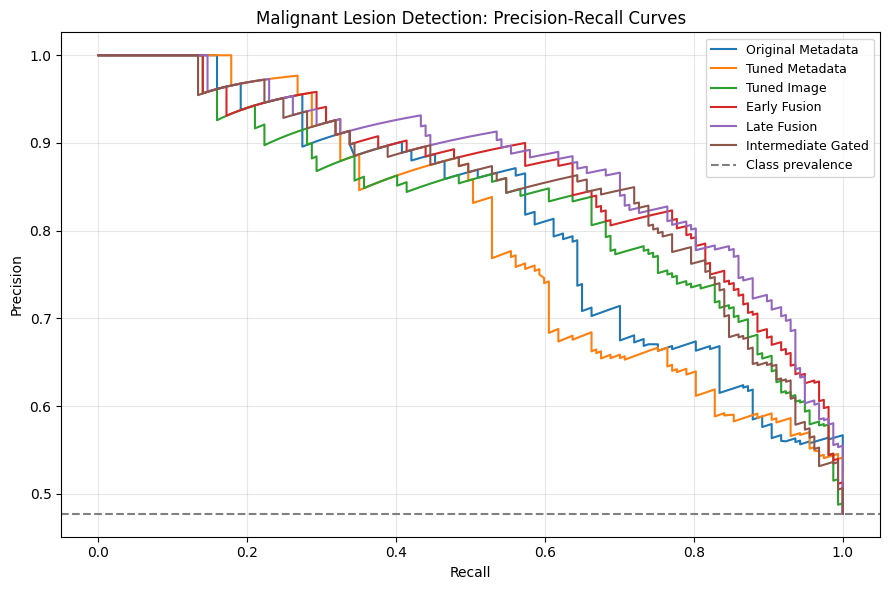


Probability evaluation completed!


In [28]:
# SUPPLEMENTARY EVALUATION — MALIGNANT LESION ANALYSIS
# Malignant Prediction Probability Evaluation


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_recall_curve
)

# 1. Define malignant labels


malignant_classes = ["BCC", "MEL", "SCC"]

y_binary = np.isin(
    y_val, malignant_classes
).astype(int)

# 2. Collect probabilities from all trained models


probability_models = {
    "Original Metadata": (
        metadata_model.predict_proba(X_val_meta),
        metadata_model.classes_
    ),
    "Tuned Metadata": (
        metadata_tuned.predict_proba(X_val_metadata),
        metadata_tuned.classes_
    ),
    "Tuned Image": (
        image_tuned.predict_proba(X_val_img),
        image_tuned.classes_
    ),
    "Early Fusion": (
        early_model.predict_proba(X_val_early),
        early_model.classes_
    ),
    "Late Fusion": (
        late_probabilities,
        image_tuned.classes_
    ),
    "Intermediate Gated": (
        val_probs_gated,
        final_classes
    )
}

# 3. Evaluate malignant prediction probabilities


probability_results = []
pr_curves = {}

for name, (probabilities, model_classes) in probability_models.items():

    model_classes= np.asarray(model_classes)

    malignant_indices= [
        i for i, label in enumerate(model_classes)
        if label in malignant_classes
    ]

    # Sum probabilities of all malignant diagnoses
    malignant_probability= probabilities[
        :, malignant_indices
    ].sum(axis=1)

    assert len(malignant_probability) == len(y_binary)
    assert np.isfinite(malignant_probability).all()
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-5)

    roc_auc= roc_auc_score(
        y_binary, malignant_probability
    )

    avg_precision= average_precision_score(
        y_binary, malignant_probability
    )

    brier= brier_score_loss(
        y_binary, malignant_probability
    )

    probability_results.append({
        "Model": name,
        "ROC-AUC": roc_auc,
        "Average Precision": avg_precision,
        "Brier Score": brier
    })

    precision, recall, _ = precision_recall_curve(
        y_binary, malignant_probability
    )

    pr_curves[name] = (recall, precision)


# 4. Display evaluation table


probability_df = pd.DataFrame(probability_results)

print("MALIGNANT PREDICTION PROBABILITY EVALUATION")


print(
    probability_df.round(4).to_string(index=False)
)

print("\nMalignant class prevalence:",
      round(y_binary.mean(), 4))
print("="*50)

# 5. Plot precision-recall curves


plt.figure(figsize=(9, 6))

for name, (recall, precision) in pr_curves.items():

    plt.plot(
        recall,
        precision,
        label=name
    )

plt.axhline(
    y_binary.mean(),
    linestyle="--",
    color="gray",
    label="Class prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Malignant Lesion Detection: Precision-Recall Curves")
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "malignant_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Save results


probability_df.to_csv(
    RESULTS_DIR / "malignant_probability_metrics.csv",
    index=False
)

print("\nProbability evaluation completed!")


In [29]:
# SUPPLEMENTARY ETHICS AND BIAS ASSESSMENT
# Subgroup Performance by Age and Lesion Region


import numpy as np
import pandas as pd


# 1. Define subgroup categories


# Use training median to define age groups
age_cutoff = train_df["age"].median()

subgroup_df = validation_df[
    ["age", "region", "diagnostic"]
].reset_index(drop=True).copy()

subgroup_df["Age Group"] = np.where(
    subgroup_df["age"] < age_cutoff,
    f"Below {age_cutoff:g}",
    f"{age_cutoff:g} or above"
)

print("Training median age:", age_cutoff)

# 2. Select models for subgroup comparison


subgroup_models= {
    "Original Metadata": y_val_pred_meta,
    "Early Fusion": y_val_pred_early,
    "Late Fusion": y_val_pred_late,
    "Intermediate Gated": y_val_pred_gated
}

malignant_labels= ["BCC", "MEL", "SCC"]

actual_malignant = np.isin(
    y_val, malignant_labels
)


# 3. Evaluate subgroup performance


subgroup_results= []

for subgroup_type in ["Age Group", "region"]:

    for subgroup_name, group in subgroup_df.groupby(
        subgroup_type
    ):

        indices= group.index.to_numpy()

        true_binary= actual_malignant[indices]

        malignant_n= int(true_binary.sum())
        other_n= int((~true_binary).sum())

        # Only report groups with sufficient observations
        if (
            len(indices) < 20
            or malignant_n < 10
            or other_n < 10
        ):
            continue

        for model_name, predictions in subgroup_models.items():

            predicted_binary = np.isin(
                np.asarray(predictions)[indices],
                malignant_labels
            )

            tp = np.sum(true_binary & predicted_binary)
            fn = np.sum(true_binary & ~predicted_binary)
            tn = np.sum(~true_binary & ~predicted_binary)
            fp = np.sum(~true_binary & predicted_binary)

            subgroup_results.append({
                "Subgroup Type": subgroup_type,
                "Subgroup": subgroup_name,
                "Model": model_name,
                "Total Images": len(indices),
                "Malignant Cases": malignant_n,
                "Other Cases": other_n,
                "Sensitivity": tp / (tp + fn),
                "Specificity": tn / (tn + fp),
                "False Negatives": int(fn),
                "False Positives": int(fp)
            })

subgroup_results= pd.DataFrame(subgroup_results)

# 4. Display age group results
print("="*80)


print("\nAGE GROUP PERFORMANCE\n")

age_results = subgroup_results[
    subgroup_results["Subgroup Type"] == "Age Group"
]

print(age_results.round(4).to_string(index=False))

# 5. Display lesion-region results
print("="*80)


print("\nLESION REGION PERFORMANCE\n")

region_results = subgroup_results[
    subgroup_results["Subgroup Type"] == "region"
]

print(region_results.round(4).to_string(index=False))

# 6. Save results

subgroup_results.to_csv(
    RESULTS_DIR / "subgroup_bias_analysis.csv",
    index=False
)
print("="*80)


print("\nSubgroup robustness analysis completed!")


Training median age: 62.0

AGE GROUP PERFORMANCE

Subgroup Type    Subgroup              Model  Total Images  Malignant Cases  Other Cases  Sensitivity  Specificity  False Negatives  False Positives
    Age Group 62 or above  Original Metadata           153               82           71       0.7195       0.5775               23               30
    Age Group 62 or above       Early Fusion           153               82           71       0.8049       0.8028               16               14
    Age Group 62 or above        Late Fusion           153               82           71       0.8537       0.8028               12               14
    Age Group 62 or above Intermediate Gated           153               82           71       0.8415       0.7887               13               15
    Age Group    Below 62  Original Metadata           176               75          101       0.7467       0.7624               19               24
    Age Group    Below 62       Early Fusion           1

In [30]:
# SUPPLEMENTARY EVALUATION — COMPUTATIONAL EFFICIENCY
# Training and Inference Time Comparison


import time
import numpy as np
import pandas as pd

# 1. Define prediction functions


def predict_original_metadata():
    processed = metadata_preprocessor.transform(X_val_metadata)
    return metadata_model.predict(processed)


def predict_tuned_metadata():
    return metadata_tuned.predict(X_val_metadata)


def predict_tuned_image():
    return image_tuned.predict(X_val_img)


def predict_early_fusion():
    return early_model.predict(X_val_early)


def predict_late_fusion():

    image_probs = image_tuned.predict_proba(X_val_img)

    metadata_probs = metadata_tuned.predict_proba(
        X_val_metadata
    )

    fused_probs = (
        best_image_weight * image_probs +
        best_metadata_weight * metadata_probs
    )

    return image_tuned.classes_[
        np.argmax(fused_probs, axis=1)
    ]


def predict_intermediate_fusion():

    scaled_images = final_image_scaler.transform(
        X_val_img
    ).astype(np.float32)

    processed_metadata = metadata_preprocessor.transform(
        X_val_metadata
    ).astype(np.float32)

    predictions, _ = gated_predict(
        gated_final,
        scaled_images,
        processed_metadata
    )

    return predictions


# 2. Collect models and previous predictions

prediction_functions = {
    "Original Metadata": predict_original_metadata,
    "Tuned Metadata": predict_tuned_metadata,
    "Tuned Image": predict_tuned_image,
    "Early Fusion": predict_early_fusion,
    "Late Fusion": predict_late_fusion,
    "Intermediate Gated": predict_intermediate_fusion
}

previous_predictions = {
    "Original Metadata": y_val_pred_meta,
    "Tuned Metadata": y_val_pred_meta_tuned,
    "Tuned Image": y_val_pred_tuned,
    "Early Fusion": y_val_pred_early,
    "Late Fusion": y_val_pred_late,
    "Intermediate Gated": y_val_pred_gated
}

# 3. Measure inference time


N_REPEATS = 10
efficiency_results = []

for model_name, predict_function in prediction_functions.items():

    # Warm-up and verify unchanged predictions
    predictions = predict_function()

    assert np.array_equal(
        predictions,
        previous_predictions[model_name]
    ), f"Prediction mismatch: {model_name}"

    timings = []

    for repeat in range(N_REPEATS):

        start_time = time.perf_counter()

        predictions = predict_function()

        elapsed = time.perf_counter() - start_time

        timings.append(elapsed)

    mean_time = np.mean(timings)
    std_time = np.std(timings)

    efficiency_results.append({
        "Model": model_name,
        "Mean Time (ms)": mean_time * 1000,
        "Std Time (ms)": std_time * 1000,
        "Time per Image (ms)": mean_time * 1000 / len(y_val),
        "Images": len(y_val)
    })

    print(model_name, "completed.")

# 4. Compare inference efficiency


efficiency_df = pd.DataFrame(efficiency_results)
print("="*50)


print("\nMODEL INFERENCE EFFICIENCY\n")

print(
    efficiency_df.round(4).to_string(index=False)
)
print("="*50)

print("\nImportant:")
print("Timings use cached EfficientNet image embeddings.")
print("Raw image feature extraction is NOT included.")
print("Device:", device)

# 5. Save results


efficiency_df.to_csv(
    RESULTS_DIR / "model_inference_efficiency.csv",
    index=False
)

print("\nComputational efficiency analysis completed!")


Original Metadata completed.
Tuned Metadata completed.
Tuned Image completed.
Early Fusion completed.
Late Fusion completed.
Intermediate Gated completed.

MODEL INFERENCE EFFICIENCY

             Model  Mean Time (ms)  Std Time (ms)  Time per Image (ms)  Images
 Original Metadata         13.4400         1.7519               0.0409     329
    Tuned Metadata         13.5419         1.5059               0.0412     329
       Tuned Image         22.6919         2.4821               0.0690     329
      Early Fusion         70.8178        11.9674               0.2153     329
       Late Fusion         39.0043         4.0477               0.1186     329
Intermediate Gated         42.8782         1.5668               0.1303     329

Important:
Timings use cached EfficientNet image embeddings.
Raw image feature extraction is NOT included.
Device: cpu

Computational efficiency analysis completed!


In [31]:
# SECTION 10 — FINAL MODEL SELECTION
# 10.1 Pre-Test Model Selection and Reproducibility

import json
import pandas as pd
from datetime import datetime

# 1. Consolidate existing validation results


final_summary= fusion_comparison.copy()

final_summary["Malignant Sensitivity"] = (
    final_summary.index.map(
        malignant_df.set_index("Model")["Sensitivity"]
    )
)

final_summary["Average Precision"] = (
    final_summary.index.map(
        probability_df.set_index("Model")["Average Precision"]
    )
)

final_summary["Brier Score"] = (
    final_summary.index.map(
        probability_df.set_index("Model")["Brier Score"]
    )
)

final_summary["Inference (ms/image)"] = (
    final_summary.index.map(
        efficiency_df.set_index("Model")["Time per Image (ms)"]
    )
)

print("PRE-TEST MODEL COMPARISON")

print(
    final_summary.sort_values(
        "Macro-F1", ascending=False
    ).round(4).to_string()
)


# 2. Verify selected model artifacts exist


model_files= [
    "metadata_baseline.joblib",
    "metadata_tuned.joblib",
    "image_tuned.joblib",
    "early_fusion.joblib",
    "late_fusion.joblib",
    "intermediate_gated_fusion.pt",
    "intermediate_gated_preprocessing.joblib"
]

for filename in model_files:
    assert (MODEL_DIR / filename).exists(), filename

print("\nAll required model artifacts found.")
print("="*50)



# 3. Record selected configurations


selection_manifest= {
    "project": "COMP1013 Project 2.2",
    "dataset": "PAD-UFES-20",
    "split_file": SPLIT_PATH.name,
    "random_seed": 42,
    "primary_metric": "Macro-F1",
    "primary_model": "Late Fusion",
    "image_regularisation_C": float(
        image_tuned.named_steps["classifier"].C
    ),
    "metadata_regularisation_C": float(
        metadata_tuned.named_steps["classifier"].C
    ),
    "early_fusion_C": float(
        early_model.named_steps["classifier"].C
    ),
    "late_image_weight": float(best_image_weight),
    "late_metadata_weight": float(best_metadata_weight),
    "intermediate_epochs": int(FINAL_EPOCHS),
    "validation_macro_f1": float(
        val_metrics_late["Macro-F1"]
    ),
    "test_evaluated": False,
    "limitations": [
        "Validation set examined across multiple experiments",
        "Limited melanoma cases",
        "Substantial image-model overfitting",
        "Exploratory model comparisons"
    ]
}

manifest_path= (
    RESULTS_DIR / "pretest_model_selection.json"
)

with open(manifest_path, "w", encoding="utf-8") as file:
    json.dump(selection_manifest, file, indent=4)


# 4. Save consolidated comparison


final_summary.to_csv(
    RESULTS_DIR / "final_validation_comparison.csv"
)

print("\nPRIMARY MODEL: Late Fusion")
print("Image weight:", best_image_weight)
print("Metadata weight:", best_metadata_weight)
print("Validation Macro-F1:",
      round(val_metrics_late["Macro-F1"], 4))

print("\nModel selection recorded successfully.")
print("Held-out test set has NOT been evaluated.")


PRE-TEST MODEL COMPARISON
                    Accuracy  Balanced Accuracy  Macro-F1  Malignant Sensitivity  Average Precision  Brier Score  Inference (ms/image)
Late Fusion           0.6717             0.6236    0.5794                 0.8025             0.8758       0.1635                0.1186
Early Fusion          0.6292             0.5894    0.5766                 0.7261             0.8628       0.1451                0.2153
Intermediate Gated    0.5988             0.5817    0.5670                 0.7197             0.8509       0.1554                0.1303
Original Metadata     0.5745             0.6442    0.5252                 0.7325             0.8169       0.1815                0.0409
Tuned Image           0.5805             0.5249    0.5166                 0.6943             0.8330       0.1621                0.0690
Tuned Metadata        0.5289             0.4743    0.4335                 0.6815             0.7992       0.1973                0.0412

All required model artifacts

In [32]:
# SECTION 10 — FINAL MODEL SELECTION
# 10.2 Corrected Pre-Test Integrity Audit


import numpy as np
import pandas as pd
import json
import joblib


# 1. Save tuned image predictions separately


tuned_image_predictions = pd.DataFrame({
    "img_id": validation_df["img_id"].values,
    "patient_id": validation_df["patient_id"].values,
    "Actual": y_val,
    "Predicted": y_val_pred_tuned
})

tuned_image_probs = image_tuned.predict_proba(X_val_img)

for i, class_name in enumerate(image_tuned.classes_):
    tuned_image_predictions[f"prob_{class_name}"] = (
        tuned_image_probs[:, i]
    )

tuned_image_predictions.to_csv(
    RESULTS_DIR / "image_tuned_validation_predictions.csv",
    index=False
)

print("Tuned image predictions saved separately.")


# 2. Define correct prediction files


prediction_files = {
    "Original Metadata": "metadata_validation_predictions.csv",
    "Tuned Metadata": "metadata_tuned_validation_predictions.csv",
    "Original Image": "image_validation_predictions.csv",
    "Tuned Image": "image_tuned_validation_predictions.csv",
    "Early Fusion": "early_fusion_validation_predictions.csv",
    "Late Fusion": "late_fusion_validation_predictions.csv",
    "Intermediate Gated": "intermediate_fusion_validation_predictions.csv"
}

expected_predictions = {
    "Original Metadata": y_val_pred_meta,
    "Tuned Metadata": y_val_pred_meta_tuned,
    "Original Image": y_val_pred_img,
    "Tuned Image": y_val_pred_tuned,
    "Early Fusion": y_val_pred_early,
    "Late Fusion": y_val_pred_late,
    "Intermediate Gated": y_val_pred_gated
}


# 3. Verify validation prediction alignment


print("\nVALIDATION PREDICTION INTEGRITY")

for model_name, filename in prediction_files.items():

    saved = pd.read_csv(RESULTS_DIR / filename)

    assert len(saved) == len(validation_df)

    assert np.array_equal(
        saved["img_id"].astype(str).values,
        validation_df["img_id"].astype(str).values
    ), f"Image ID mismatch: {model_name}"

    assert np.array_equal(
        saved["patient_id"].astype(str).values,
        validation_df["patient_id"].astype(str).values
    ), f"Patient ID mismatch: {model_name}"

    assert np.array_equal(
        saved["Actual"].values,
        y_val
    ), f"Actual label mismatch: {model_name}"

    assert np.array_equal(
        saved["Predicted"].values,
        expected_predictions[model_name]
    ), f"Prediction mismatch: {model_name}"

    print(f"{model_name}: PASSED ({len(saved)} images)")


# 4. Verify late-fusion configuration


saved_late = joblib.load(
    MODEL_DIR / "late_fusion.joblib"
)

assert np.isclose(
    saved_late["image_weight"],
    best_image_weight
)

assert np.isclose(
    saved_late["metadata_weight"],
    best_metadata_weight
)

assert np.isclose(
    best_image_weight + best_metadata_weight, 1.0
)

assert np.array_equal(
    saved_late["classes"],
    image_tuned.classes_
)
print("="*50)


print("\nLate-fusion configuration: PASSED")


# 5. Verify patient separation


assert len(
    patient_sets["train"] & patient_sets["validation"]
) == 0

assert len(
    patient_sets["train"] & patient_sets["test"]
) == 0

assert len(
    patient_sets["validation"] & patient_sets["test"]
) == 0

print("Patient-disjoint partitions: PASSED")


# 6. Verify pre-test model selection


with open(
    RESULTS_DIR / "pretest_model_selection.json",
    "r",
    encoding="utf-8"
) as file:
    manifest = json.load(file)

assert manifest["primary_model"] == "Late Fusion"
assert manifest["test_evaluated"] is False

print("Pre-test model selection: PASSED")
print("="*50)


print("\nALL PRE-TEST INTEGRITY CHECKS PASSED!")
print("The held-out test set has NOT been evaluated.")


Tuned image predictions saved separately.

VALIDATION PREDICTION INTEGRITY
Original Metadata: PASSED (329 images)
Tuned Metadata: PASSED (329 images)
Original Image: PASSED (329 images)
Tuned Image: PASSED (329 images)
Early Fusion: PASSED (329 images)
Late Fusion: PASSED (329 images)
Intermediate Gated: PASSED (329 images)

Late-fusion configuration: PASSED
Patient-disjoint partitions: PASSED
Pre-test model selection: PASSED

ALL PRE-TEST INTEGRITY CHECKS PASSED!
The held-out test set has NOT been evaluated.


In [33]:
# SECTION 10 — FINAL HELD-OUT TEST EVALUATION
# 10.3 Prepare Test Features and Verify Alignment


import numpy as np
import pandas as pd
import time


# 1. Load original held-out test partition


test_df = df[df["split"] == "test"].copy()

print("HELD-OUT TEST PREPARATION")

print("Test images:", len(test_df))
print("Unique test patients:", test_df["patient_id"].nunique())

assert len(test_df) == 329

# Verify patient separation
assert not (
    set(test_df["patient_id"]) &
    set(train_df["patient_id"])
)

assert not (
    set(test_df["patient_id"]) &
    set(validation_df["patient_id"])
)

print("Patient separation: PASSED")


# 2. Extract test image embeddings


# Use the original frozen EfficientNet-B0 model
# and deterministic image preprocessing.

X_test_img, test_extraction_time = extract_image_features(
    test_df,
    "Held-out Test"
)

assert X_test_img.shape == (329, 1280)
assert np.isfinite(X_test_img).all()
print("="*50)

print("\nTest image features: PASSED")


# 3. Prepare test metadata


# Use the same six conservative clinical features
X_test_metadata = test_df[metadata_features].copy()

# Use the existing TRAINING-fitted preprocessor
X_test_meta = metadata_preprocessor.transform(
    X_test_metadata
)

assert X_test_meta.shape[0] == len(test_df)
assert X_test_meta.shape[1] == X_train_meta.shape[1]
assert np.isfinite(X_test_meta).all()

print("Test metadata preprocessing: PASSED")
print("Processed metadata shape:", X_test_meta.shape)


# 4. Prepare early fusion input


test_image_features = pd.DataFrame(
    X_test_img,
    columns=image_feature_cols
)

X_test_early = pd.concat([
    test_image_features,
    X_test_metadata.reset_index(drop=True)
], axis=1)

assert X_test_early.shape == (329, 1286)

assert list(X_test_early.columns) == list(
    X_train_early.columns
)

print("Early fusion feature alignment: PASSED")


# 5. Save test embeddings for reproducibility


np.savez_compressed(
    CACHE_DIR / "efficientnet_b0_test_features.npz",
    X_test=X_test_img,
    test_ids=test_df["img_id"].astype(str).to_numpy(
        dtype=str
    )
)


# 6. Final preparation summary
print("="*50)


print("\nTEST PREPARATION SUMMARY")

print("Test images:", len(test_df))
print("Image features:", X_test_img.shape)
print("Metadata features:", X_test_meta.shape)
print("Early fusion input:", X_test_early.shape)

print("Extraction time (seconds):",
      round(test_extraction_time, 2))
print("="*50)

print("\nAll test features prepared successfully!")
print("No test performance metrics have been calculated.")


HELD-OUT TEST PREPARATION
Test images: 329
Unique test patients: 197
Patient separation: PASSED
Held-out Test: 160/329 images processed
Held-out Test: 320/329 images processed

Held-out Test completed.
Feature shape: (329, 1280)
Extraction time (seconds): 75.46

Test image features: PASSED
Test metadata preprocessing: PASSED
Processed metadata shape: (329, 27)
Early fusion feature alignment: PASSED

TEST PREPARATION SUMMARY
Test images: 329
Image features: (329, 1280)
Metadata features: (329, 27)
Early fusion input: (329, 1286)
Extraction time (seconds): 75.46

All test features prepared successfully!
No test performance metrics have been calculated.


In [34]:
# SECTION 10 — FINAL HELD-OUT TEST EVALUATION
# 10.4 Evaluate All Locked Models ONCE


import numpy as np
import pandas as pd
import json
from datetime import datetime, timezone

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# 1. Verify class alignment and test data


y_test = test_df["diagnostic"].to_numpy()
test_classes = np.asarray(classes)

assert len(y_test) == 329
assert X_test_img.shape == (329, 1280)
assert X_test_meta.shape == (329, 27)
assert X_test_early.shape == (329, 1286)

assert np.array_equal(
    test_classes, metadata_model.classes_
)

assert np.array_equal(
    test_classes, metadata_tuned.classes_
)

assert np.array_equal(
    test_classes, image_tuned.classes_
)

assert np.array_equal(
    test_classes, early_model.classes_
)

assert np.array_equal(
    test_classes, np.asarray(final_classes)
)

print("FINAL HELD-OUT TEST EVALUATION\n")

print("Test images:", len(y_test))
print("Test patients:", test_df["patient_id"].nunique())
print("Classes:", list(test_classes))
print("Class alignment: PASSED")


# 2. Generate predictions from existing models


# Original metadata baseline
original_meta_probs = metadata_model.predict_proba(
    X_test_meta
)

# Tuned metadata baseline
tuned_meta_probs = metadata_tuned.predict_proba(
    X_test_metadata
)

# Tuned image baseline
tuned_image_probs = image_tuned.predict_proba(
    X_test_img
)

# Early fusion
early_probs = early_model.predict_proba(
    X_test_early
)

# Late fusion: weights already selected and locked
late_probs = (
    best_image_weight * tuned_image_probs +
    best_metadata_weight * tuned_meta_probs
)

# Intermediate gated fusion: existing trained model
test_gated_images = final_image_scaler.transform(
    X_test_img
).astype(np.float32)

test_gated_metadata = metadata_preprocessor.transform(
    X_test_metadata
).astype(np.float32)

gated_predictions, gated_probs = gated_predict(
    gated_final,
    test_gated_images,
    test_gated_metadata
)


# 3. Store all model outputs


test_probabilities = {
    "Original Metadata": original_meta_probs,
    "Tuned Metadata": tuned_meta_probs,
    "Tuned Image": tuned_image_probs,
    "Early Fusion": early_probs,
    "Late Fusion": late_probs,
    "Intermediate Gated": gated_probs
}

test_predictions = {}

for model_name, probs in test_probabilities.items():

    probs = np.asarray(probs)

    assert probs.shape == (
        len(y_test), len(test_classes)
    ), f"Probability shape mismatch: {model_name}"

    assert np.isfinite(probs).all(), model_name

    assert np.allclose(
        probs.sum(axis=1), 1.0, atol=1e-5
    ), f"Invalid probabilities: {model_name}"

    test_predictions[model_name] = test_classes[
        np.argmax(probs, axis=1)
    ]

assert np.array_equal(
    test_predictions["Intermediate Gated"],
    np.asarray(gated_predictions)
), "Gated prediction order mismatch"

print("All six model predictions generated successfully.")


# 4. Define malignant detection task


malignant_classes = ["BCC", "MEL", "SCC"]

actual_malignant = np.isin(
    y_test, malignant_classes
)

malignant_indices = [
    i for i, label in enumerate(test_classes)
    if label in malignant_classes
]


# 5. Calculate final held-out test metrics


test_results = []

for model_name, predictions in test_predictions.items():

    probs = test_probabilities[model_name]

    predicted_malignant = np.isin(
        predictions, malignant_classes
    )

    malignant_probability = probs[
        :, malignant_indices
    ].sum(axis=1)

    tn, fp, fn, tp = confusion_matrix(
        actual_malignant,
        predicted_malignant,
        labels=[False, True]
    ).ravel()

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test, predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Macro-F1": f1_score(
            y_test, predictions,
            labels=test_classes,
            average="macro",
            zero_division=0
        ),
        "MEL Recall": recall_score(
            y_test == "MEL",
            predictions == "MEL",
            zero_division=0
        ),
        "SCC Recall": recall_score(
            y_test == "SCC",
            predictions == "SCC",
            zero_division=0
        ),
        "Malignant Sensitivity": tp / (tp + fn),
        "Malignant Specificity": tn / (tn + fp),
        "Malignant False Negatives": int(fn),
        "Malignant False Positives": int(fp),
        "ROC-AUC": roc_auc_score(
            actual_malignant,
            malignant_probability
        ),
        "Average Precision": average_precision_score(
            actual_malignant,
            malignant_probability
        ),
        "Brier Score": brier_score_loss(
            actual_malignant,
            malignant_probability
        )
    })

test_results_df = pd.DataFrame(test_results)


# 6. Display final test comparison

print("="*50)

print("\nFINAL HELD-OUT TEST PERFORMANCE")


display_columns = [
    "Model",
    "Accuracy",
    "Balanced Accuracy",
    "Macro-F1",
    "MEL Recall",
    "SCC Recall",
    "Malignant Sensitivity",
    "Malignant Specificity"
]

print(
    test_results_df[display_columns]
    .round(4)
    .to_string(index=False)
)
print("="*50)

print("\nTEST PROBABILITY METRICS\n")

print(
    test_results_df[
        ["Model", "ROC-AUC",
         "Average Precision", "Brier Score"]
    ]
    .round(4)
    .to_string(index=False)
)
print("="*50)

print("\nTEST CLASS DISTRIBUTION\n")

print(
    pd.Series(y_test)
    .value_counts()
    .reindex(test_classes, fill_value=0)
    .to_string()
)

# 7. Save results and individual predictions


test_results_df.to_csv(
    RESULTS_DIR / "final_heldout_test_metrics.csv",
    index=False
)

test_prediction_df = pd.DataFrame({
    "img_id": test_df["img_id"].astype(str).values,
    "patient_id": test_df["patient_id"].astype(str).values,
    "Actual": y_test
})

for model_name, predictions in test_predictions.items():

    safe_name = (
        model_name.lower().replace(" ", "_")
    )

    test_prediction_df[
        f"pred_{safe_name}"
    ] = predictions

    probs = test_probabilities[model_name]

    test_prediction_df[
        f"malignant_prob_{safe_name}"
    ] = probs[:, malignant_indices].sum(axis=1)

test_prediction_df.to_csv(
    RESULTS_DIR / "final_heldout_test_predictions.csv",
    index=False
)

# 8. Record completion without changing pre-test manifest


test_manifest = {
    "evaluation": "Final held-out test",
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "test_images": len(y_test),
    "test_patients": int(
        test_df["patient_id"].nunique()
    ),
    "preselected_primary_model": "Late Fusion",
    "late_image_weight": float(best_image_weight),
    "late_metadata_weight": float(best_metadata_weight),
    "models_evaluated": list(
        test_predictions.keys()
    ),
    "test_evaluated": True,
    "configuration_changed_after_testing": False
}

with open(
    RESULTS_DIR / "final_test_evaluation_manifest.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(test_manifest, file, indent=4)
print("="*50)


print("\nFINAL TEST EVALUATION COMPLETED!")
print("All results saved successfully.")
print("No models were retrained or retuned.")
print("Primary model remains: Late Fusion.")


FINAL HELD-OUT TEST EVALUATION

Test images: 329
Test patients: 197
Classes: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']
Class alignment: PASSED
All six model predictions generated successfully.

FINAL HELD-OUT TEST PERFORMANCE
             Model  Accuracy  Balanced Accuracy  Macro-F1  MEL Recall  SCC Recall  Malignant Sensitivity  Malignant Specificity
 Original Metadata    0.5046             0.4554    0.4215      0.2857      0.4286                 0.7051                 0.6301
    Tuned Metadata    0.5015             0.4994    0.4244      0.5714      0.3929                 0.6731                 0.6763
       Tuned Image    0.6170             0.5188    0.5298      0.2857      0.2857                 0.7244                 0.8266
      Early Fusion    0.6474             0.5432    0.5542      0.2857      0.2857                 0.7692                 0.8439
       Late Fusion    0.6565             0.5325    0.5273      0.1429      0.2857                 0.7244                 0.8555
Inter

TEST MELANOMA AND SCC PERFORMANCE

             Model Diagnosis  Support  Precision  Recall     F1
 Original Metadata       MEL        7     0.0444  0.2857 0.0769
 Original Metadata       SCC       28     0.3077  0.4286 0.3582
    Tuned Metadata       MEL        7     0.0930  0.5714 0.1600
    Tuned Metadata       SCC       28     0.2750  0.3929 0.3235
       Tuned Image       MEL        7     0.6667  0.2857 0.4000
       Tuned Image       SCC       28     0.2424  0.2857 0.2623
      Early Fusion       MEL        7     0.6667  0.2857 0.4000
      Early Fusion       SCC       28     0.2500  0.2857 0.2667
       Late Fusion       MEL        7     0.2500  0.1429 0.1818
       Late Fusion       SCC       28     0.3478  0.2857 0.3137
Intermediate Gated       MEL        7     0.6667  0.2857 0.4000
Intermediate Gated       SCC       28     0.1667  0.2500 0.2000

LATE FUSION — FULL TEST CLASSIFICATION REPORT

              precision    recall  f1-score   support

         ACK     0.6957    0.7

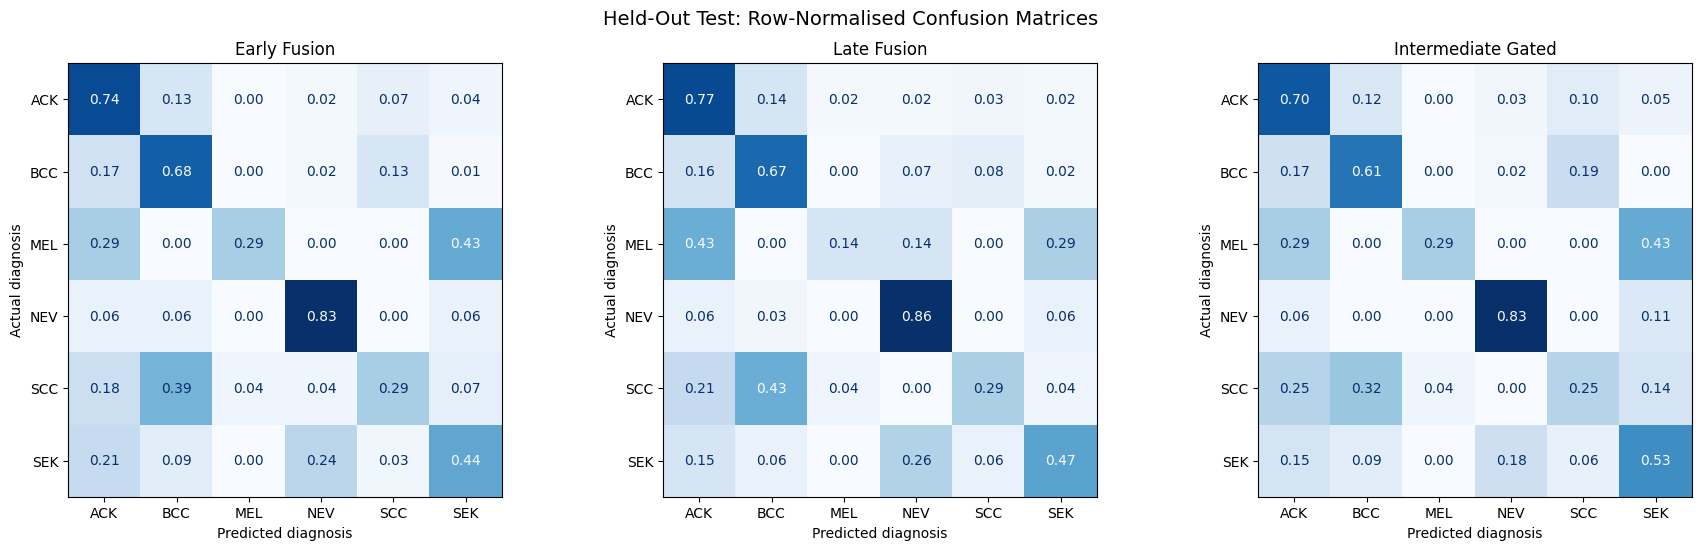


LATE FUSION — MOST COMMON TEST ERRORS

Actual Predicted  Count
   BCC       ACK     19
   ACK       BCC     15
   SCC       BCC     12
   BCC       SCC     10
   SEK       NEV      9
   BCC       NEV      8
   SCC       ACK      6
   SEK       ACK      5
   ACK       SCC      3
   BCC       SEK      3

Final test confusion and per-class analysis completed!
No models were modified.


In [35]:

# SECTION 10 — FINAL HELD-OUT TEST EVALUATION
# 10.5 Confusion Matrices and Per-Class Error Analysis


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Calculate per-class performance for all models


per_class_records = []

for model_name, predictions in test_predictions.items():

    report = classification_report(
        y_test,
        predictions,
        labels=test_classes,
        target_names=test_classes,
        output_dict=True,
        zero_division=0
    )

    for diagnosis in test_classes:

        per_class_records.append({
            "Model": model_name,
            "Diagnosis": diagnosis,
            "Support": int(report[diagnosis]["support"]),
            "Precision": report[diagnosis]["precision"],
            "Recall": report[diagnosis]["recall"],
            "F1": report[diagnosis]["f1-score"]
        })

test_per_class_df = pd.DataFrame(per_class_records)

test_per_class_df.to_csv(
    RESULTS_DIR / "final_test_per_class_metrics.csv",
    index=False
)


# 2. Display key melanoma and SCC comparisons


print("TEST MELANOMA AND SCC PERFORMANCE\n")

critical_classes = test_per_class_df[
    test_per_class_df["Diagnosis"].isin(["MEL", "SCC"])
]

print(
    critical_classes.round(4).to_string(index=False)
)


# 3. Full report for preselected primary model
print("="*50)


print("\nLATE FUSION — FULL TEST CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test,
        test_predictions["Late Fusion"],
        labels=test_classes,
        target_names=test_classes,
        digits=4,
        zero_division=0
    )
)


# 4. Plot normalized confusion matrices


fusion_models = [
    "Early Fusion",
    "Late Fusion",
    "Intermediate Gated"
]

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5.5)
)

for ax, model_name in zip(axes, fusion_models):

    cm = confusion_matrix(
        y_test,
        test_predictions[model_name],
        labels=test_classes,
        normalize="true"
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=test_classes
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format=".2f",
        colorbar=False
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted diagnosis")
    ax.set_ylabel("Actual diagnosis")

fig.suptitle(
    "Held-Out Test: Row-Normalised Confusion Matrices",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "final_test_fusion_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Identify primary model's largest confusions


late_cm= confusion_matrix(
    y_test,
    test_predictions["Late Fusion"],
    labels=test_classes
)

confusion_errors= []

for i, actual_class in enumerate(test_classes):

    for j, predicted_class in enumerate(test_classes):

        if i != j and late_cm[i, j] > 0:

            confusion_errors.append({
                "Actual": actual_class,
                "Predicted": predicted_class,
                "Count": int(late_cm[i, j])
            })

confusion_errors_df= pd.DataFrame(
    confusion_errors
).sort_values(
    "Count",
    ascending=False
)
print("="*50)

print("\nLATE FUSION — MOST COMMON TEST ERRORS\n")

print(
    confusion_errors_df.head(10).to_string(index=False)
)

confusion_errors_df.to_csv(
    RESULTS_DIR / "final_test_late_fusion_errors.csv",
    index=False
)
print("="*50)


print("\nFinal test confusion and per-class analysis completed!")
print("No models were modified.")


In [36]:
# SECTION 10 — FINAL HELD-OUT TEST EVALUATION
# 10.6 Patient-Level Bootstrap Confidence Intervals


import numpy as np
import pandas as pd
from sklearn.metrics import f1_score


# 1. Prepare patient-level groups


patient_ids = (
    test_df["patient_id"]
    .astype(str)
    .to_numpy()
)

unique_patients= np.unique(patient_ids)

patient_indices = [
    np.flatnonzero(patient_ids == patient)
    for patient in unique_patients
]

assert len(unique_patients) == 197
assert sum(len(indices) for indices in patient_indices) == 329

model_names= list(test_predictions.keys())

malignant_labels= ["BCC", "MEL", "SCC"]

print("PATIENT-LEVEL TEST BOOTSTRAP\n")

print("Test patients:", len(unique_patients))
print("Test images:", len(y_test))
print("Models:", len(model_names))

# 2. Configure reproducible bootstrap


N_BOOTSTRAP= 4000
rng = np.random.default_rng(42)

bootstrap_f1= {
    name: np.empty(N_BOOTSTRAP)
    for name in model_names
}

bootstrap_sensitivity= {
    name: np.empty(N_BOOTSTRAP)
    for name in model_names
}

samples_without_mel = 0


# 3. Resample patients with replacement


for b in range(N_BOOTSTRAP):

    sampled_patients= rng.integers(
        0,
        len(patient_indices),
        size=len(patient_indices)
    )

    sampled_indices= np.concatenate([
        patient_indices[i]
        for i in sampled_patients
    ])

    actual = y_test[sampled_indices]

    actual_malignant_boot= np.isin(
        actual, malignant_labels
    )

    assert actual_malignant_boot.any()

    if not np.any(actual == "MEL"):
        samples_without_mel += 1

    for model_name in model_names:

        predicted = np.asarray(
            test_predictions[model_name]
        )[sampled_indices]

        # Fixed six-class macro-F1
        bootstrap_f1[model_name][b] = f1_score(
            actual,
            predicted,
            labels=test_classes,
            average="macro",
            zero_division=0
        )

        # Malignant sensitivity based on predicted class
        predicted_malignant_boot = np.isin(
            predicted, malignant_labels
        )

        bootstrap_sensitivity[model_name][b] = (
            predicted_malignant_boot[
                actual_malignant_boot
            ].mean()
        )

    if (b + 1) % 1000 == 0:
        print(f"{b + 1}/{N_BOOTSTRAP} resamples completed")

# 4. Calculate 95% bootstrap confidence intervals


def bootstrap_ci(values):
    return np.percentile(values, [2.5, 97.5])

test_summary= test_results_df.set_index("Model")

bootstrap_summary= []

for model_name in model_names:

    f1_lower, f1_upper = bootstrap_ci(
        bootstrap_f1[model_name]
    )

    sens_lower, sens_upper = bootstrap_ci(
        bootstrap_sensitivity[model_name]
    )

    bootstrap_summary.append({
        "Model": model_name,
        "Test Macro-F1": test_summary.loc[
            model_name, "Macro-F1"
        ],
        "F1 CI Lower": f1_lower,
        "F1 CI Upper": f1_upper,
        "Malignant Sensitivity": test_summary.loc[
            model_name, "Malignant Sensitivity"
        ],
        "Sensitivity CI Lower": sens_lower,
        "Sensitivity CI Upper": sens_upper
    })

bootstrap_summary_df = pd.DataFrame(
    bootstrap_summary
)
print("="*50)


print("\nTEST PERFORMANCE WITH 95% CONFIDENCE INTERVALS\n")

print(
    bootstrap_summary_df
    .round(4)
    .to_string(index=False)
)

# 5. Paired comparisons between fusion approaches


fusion_pairs = [
    ("Late Fusion", "Early Fusion"),
    ("Late Fusion", "Intermediate Gated"),
    ("Early Fusion", "Intermediate Gated")
]

paired_results = []

for model_a, model_b in fusion_pairs:

    for metric, bootstrap_values, column in [
        ("Macro-F1", bootstrap_f1, "Macro-F1"),
        (
            "Malignant Sensitivity",
            bootstrap_sensitivity,
            "Malignant Sensitivity"
        )
    ]:

        differences = (
            bootstrap_values[model_a] -
            bootstrap_values[model_b]
        )

        lower, upper = bootstrap_ci(differences)

        observed_difference = (
            test_summary.loc[model_a, column] -
            test_summary.loc[model_b, column]
        )

        paired_results.append({
            "Comparison": f"{model_a} - {model_b}",
            "Metric": metric,
            "Observed Difference": observed_difference,
            "CI Lower": lower,
            "CI Upper": upper,
            "CI Excludes Zero": bool(
                lower > 0 or upper < 0
            )
        })

paired_bootstrap_df = pd.DataFrame(
    paired_results
)
print("="*50)


print("\nPAIRED FUSION COMPARISONS\n")

print(
    paired_bootstrap_df
    .round(4)
    .to_string(index=False)
)

print(
    "\nBootstrap samples without MEL:",
    samples_without_mel,
    "of",
    N_BOOTSTRAP
)

# 6. Save results


bootstrap_summary_df.to_csv(
    RESULTS_DIR / "final_test_bootstrap_ci.csv",
    index=False
)

paired_bootstrap_df.to_csv(
    RESULTS_DIR / "final_test_paired_bootstrap.csv",
    index=False
)
print("="*50)


print("\nFinal test bootstrap analysis completed!")
print("No models were changed.")


PATIENT-LEVEL TEST BOOTSTRAP

Test patients: 197
Test images: 329
Models: 6
1000/4000 resamples completed
2000/4000 resamples completed
3000/4000 resamples completed
4000/4000 resamples completed

TEST PERFORMANCE WITH 95% CONFIDENCE INTERVALS

             Model  Test Macro-F1  F1 CI Lower  F1 CI Upper  Malignant Sensitivity  Sensitivity CI Lower  Sensitivity CI Upper
 Original Metadata         0.4215       0.3596       0.4775                 0.7051                0.6111                0.7925
    Tuned Metadata         0.4244       0.3557       0.4917                 0.6731                0.5723                0.7643
       Tuned Image         0.5298       0.4326       0.6217                 0.7244                0.6350                0.8013
      Early Fusion         0.5542       0.4551       0.6449                 0.7692                0.6835                0.8415
       Late Fusion         0.5273       0.4473       0.6068                 0.7244                0.6289                

In [37]:

# SECTION 10 — FINAL HELD-OUT TEST EVALUATION
# 10.7 Fusion vs Strongest Tuned Unimodal Baseline


import numpy as np
import pandas as pd

baseline_name= "Tuned Image"

fusion_names= [
    "Early Fusion",
    "Late Fusion",
    "Intermediate Gated"
]

comparison_records= []

for fusion_name in fusion_names:

    paired_differences= (
        bootstrap_f1[fusion_name] -
        bootstrap_f1[baseline_name]
    )

    ci_lower, ci_upper= np.percentile(
        paired_differences, [2.5, 97.5]
    )

    observed_difference= (
        test_results_df.set_index("Model").loc[
            fusion_name, "Macro-F1"
        ] -
        test_results_df.set_index("Model").loc[
            baseline_name, "Macro-F1"
        ]
    )

    comparison_records.append({
        "Comparison": f"{fusion_name} - {baseline_name}",
        "Observed F1 Difference": observed_difference,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "CI Excludes Zero": bool(
            ci_lower > 0 or ci_upper < 0
        )
    })

baseline_comparison_df= pd.DataFrame(
    comparison_records
)

print("FUSION VS STRONGEST TUNED UNIMODAL BASELINE\n")

print(
    baseline_comparison_df
    .round(4)
    .to_string(index=False)
)

baseline_comparison_df.to_csv(
    RESULTS_DIR / "final_test_fusion_vs_unimodal.csv",
    index=False
)

print("\nBaseline comparison completed.")
print("Existing models and test predictions unchanged.")


FUSION VS STRONGEST TUNED UNIMODAL BASELINE

                      Comparison  Observed F1 Difference  95% CI Lower  95% CI Upper  CI Excludes Zero
      Early Fusion - Tuned Image                  0.0245        0.0044        0.0501              True
       Late Fusion - Tuned Image                 -0.0025       -0.0834        0.0593             False
Intermediate Gated - Tuned Image                  0.0115       -0.0300        0.0518             False

Baseline comparison completed.
Existing models and test predictions unchanged.


EARLY FUSION MODALITY CONTRIBUTION

Original validation macro-F1: 0.5766

MODALITY PERMUTATION RESULTS

       Experiment  Mean_Macro_F1  Std_Macro_F1  Mean_F1_Drop  Mean_Balanced_Accuracy
   Image permuted         0.1975        0.0202        0.3791                  0.1984
Metadata permuted         0.5165        0.0139        0.0600                  0.5248


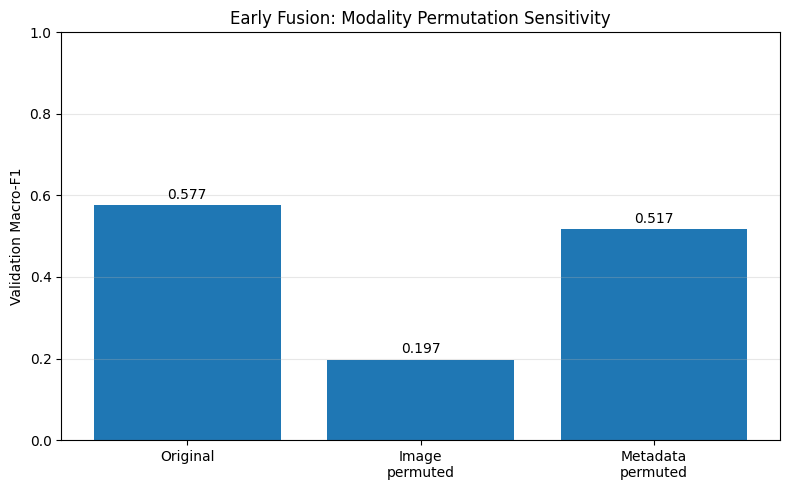


Modality contribution analysis completed!
Original model unchanged.
Held out test set not accessed.


In [38]:
# SUPPLEMENTARY ABLATION — MODALITY CONTRIBUTION
# Image and Metadata Permutation Sensitivity


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score
)

# 1. Verify original validation predictions


original_predictions = early_model.predict(X_val_early)

assert np.array_equal(
    original_predictions,
    y_val_pred_early
)

baseline_f1 = f1_score(
    y_val,
    original_predictions,
    labels=classes,
    average="macro",
    zero_division=0
)

print("EARLY FUSION MODALITY CONTRIBUTION\n")
print("Original validation macro-F1:", round(baseline_f1, 4))


# 2. Repeated permutation experiments


rng= np.random.default_rng(42)

N_PERMUTATIONS= 30
n_samples= len(y_val)

permutation_results = []

for repeat in range(N_PERMUTATIONS):

    # Experiment A: Shuffle complete image feature vectors
    
    image_indices= rng.permutation(n_samples)

    image_permuted= X_val_early.copy()

    image_permuted.loc[:, image_feature_cols] = (
        X_val_early[image_feature_cols]
        .to_numpy()[image_indices]
    )

    # Experiment B: Shuffle all clinical attributes together
    
    metadata_indices= rng.permutation(n_samples)

    metadata_permuted= X_val_early.copy()

    for feature in metadata_features:
        metadata_permuted[feature] = (
            X_val_early[feature]
            .to_numpy()[metadata_indices]
        )

    # Evaluate unchanged model on perturbed inputs
    for experiment, features in [
        ("Image permuted", image_permuted),
        ("Metadata permuted", metadata_permuted)
    ]:

        predictions = early_model.predict(features)

        macro_f1 = f1_score(
            y_val,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )

        balanced_acc = balanced_accuracy_score(
            y_val,
            predictions
        )

        permutation_results.append({
            "Repeat": repeat + 1,
            "Experiment": experiment,
            "Macro-F1": macro_f1,
            "Balanced Accuracy": balanced_acc,
            "F1 Drop": baseline_f1 - macro_f1
        })

# 3. Summarise repeated experiments


permutation_df= pd.DataFrame(permutation_results)

permutation_summary= (
    permutation_df.groupby("Experiment")
    .agg(
        Mean_Macro_F1=("Macro-F1", "mean"),
        Std_Macro_F1=("Macro-F1", "std"),
        Mean_F1_Drop=("F1 Drop", "mean"),
        Mean_Balanced_Accuracy=("Balanced Accuracy", "mean")
    )
    .reset_index()
)
print("="*50)


print("\nMODALITY PERMUTATION RESULTS\n")

print(
    permutation_summary.round(4).to_string(index=False)
)

# 4. Visualise modality sensitivity


plot_labels = [
    "Original",
    "Image\npermuted",
    "Metadata\npermuted"
]

plot_values = [
    baseline_f1,
    permutation_summary.loc[
        permutation_summary["Experiment"] == "Image permuted",
        "Mean_Macro_F1"
    ].iloc[0],
    permutation_summary.loc[
        permutation_summary["Experiment"] == "Metadata permuted",
        "Mean_Macro_F1"
    ].iloc[0]
]

plt.figure(figsize=(8, 5))

bars = plt.bar(plot_labels, plot_values)

plt.ylabel("Validation Macro-F1")
plt.title("Early Fusion: Modality Permutation Sensitivity")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, plot_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "early_fusion_modality_permutation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Save reproducible results


permutation_df.to_csv(
    RESULTS_DIR / "modality_permutation_trials.csv",
    index=False
)

permutation_summary.to_csv(
    RESULTS_DIR / "modality_permutation_summary.csv",
    index=False
)

print("\nModality contribution analysis completed!")
print("Original model unchanged.")
print("Held out test set not accessed.")


In [39]:

# REPRODUCIBILITY — DATASET INTEGRITY
# Dataset Split Provenance and Lesion Identity Audit

import hashlib
import json
import pandas as pd
from collections import Counter

# 1. Verify the canonical patient-split file


assert SPLIT_PATH.is_file(), "Original split CSV not found"

assert len(df) == 2298
assert df["img_id"].is_unique
assert df["img_id"].notna().all()
assert df["patient_id"].notna().all()
assert df["lesion_id"].notna().all()

assert set(df["split"]) == {
    "train", "validation", "test"
}

# Generate fingerprint of the existing file
sha256 = hashlib.sha256()

with open(SPLIT_PATH, "rb") as file:
    for chunk in iter(
        lambda: file.read(1024 * 1024),
        b""
    ):
        sha256.update(chunk)

split_checksum = sha256.hexdigest()

print("DATASET SPLIT PROVENANCE AUDIT\n")

print("Original split file:", SPLIT_PATH.name)
print("SHA-256:", split_checksum)

# 2. Verify split and patient counts

split_summary = (
    df.groupby("split")
    .agg(
        Images=("img_id", "size"),
        Patients=("patient_id", "nunique")
    )
    .reindex(["train", "validation", "test"])
)

assert split_summary["Images"].tolist() == [
    1640, 329, 329
]

assert split_summary["Patients"].tolist() == [
    980, 196, 197
]

patient_partition_counts = (
    df.groupby("patient_id")["split"].nunique()
)

assert (patient_partition_counts == 1).all()
print("="*50)

print("\nPATIENT-DISJOINT SPLIT SUMMARY\n")
print(split_summary.to_string())

print("\nPatient-level separation: PASSED")

# 3. Check lesion identity

# A raw lesion ID may be reused by different patients.
# Patient + lesion together is a safer identity  ke y

lesion_patient_counts = (
    df.groupby("lesion_id")["patient_id"].nunique()
)

reused_lesion_ids = int(
    (lesion_patient_counts > 1).sum()
)

lesion_split_counts = (
    df.groupby("lesion_id")["split"].nunique()
)

raw_lesions_across_splits = int(
    (lesion_split_counts > 1).sum()
)

pair_split_counts = (
    df.groupby(["patient_id", "lesion_id"])["split"]
    .nunique()
)

cross_partition_pairs = int(
    (pair_split_counts > 1).sum()
)

assert cross_partition_pairs == 0

unique_patient_lesions = (
    df[["patient_id", "lesion_id"]]
    .drop_duplicates()
    .shape[0]
)
print("="*50)


print("\nLESION IDENTITY VERIFICATION\n")

print("Unique raw lesion IDs:",
      df["lesion_id"].nunique())

print("Unique patient-lesion pairs:",
      unique_patient_lesions)

print("Raw lesion IDs reused across patients:",
      reused_lesion_ids)

print("Raw lesion IDs appearing across splits:",
      raw_lesions_across_splits)

print("Patient-lesion pairs crossing splits:",
      cross_partition_pairs)

print("\nPatient-lesion leakage: NONE DETECTED")

# 4. Verify image-file identity


all_image_paths = list(IMAGE_DIR.rglob("*.png"))

filename_counts = Counter(
    path.name for path in all_image_paths
)

duplicate_filenames = {
    name: count
    for name, count in filename_counts.items()
    if count > 1
}

expected_filenames = [
    str(image_id)
    if str(image_id).lower().endswith(".png")
    else str(image_id) + ".png"
    for image_id in df["img_id"]
]

missing_filenames = [
    name for name in expected_filenames
    if name not in filename_counts
]

assert len(duplicate_filenames) == 0
assert len(missing_filenames) == 0
assert len(all_image_paths) == 2298
print("="*50)

print("\nIMAGE IDENTITY VERIFICATION\n")

print("Discovered image files:", len(all_image_paths))
print("Duplicate filenames:", len(duplicate_filenames))
print("Missing expected images:", len(missing_filenames))

print("\nImage–metadata alignment: PASSED")

# 5. Record class distribution per partition


class_by_split = pd.crosstab(
    df["diagnostic"],
    df["split"]
).reindex(
    index=classes,
    columns=["train", "validation", "test"],
    fill_value=0
)
print("="*50)

print("\nCLASS DISTRIBUTION BY PARTITION\n")

print(class_by_split.to_string())

# 6. Save reproducibility manifest


integrity_manifest = {
    "dataset": "PAD-UFES-20",
    "canonical_split_file": SPLIT_PATH.name,
    "split_file_sha256": split_checksum,
    "total_images": int(len(df)),
    "total_patients": int(df["patient_id"].nunique()),
    "unique_raw_lesion_ids": int(
        df["lesion_id"].nunique()
    ),
    "unique_patient_lesion_pairs": int(
        unique_patient_lesions
    ),
    "patient_disjoint": True,
    "cross_partition_patient_lesion_pairs": 0,
    "all_images_matched": True,
    "split_summary": {
        split: {
            "images": int(split_summary.loc[split, "Images"]),
            "patients": int(split_summary.loc[split, "Patients"])
        }
        for split in ["train", "validation", "test"]
    },
    "class_distribution": {
        diagnosis: {
            split: int(class_by_split.loc[diagnosis, split])
            for split in ["train", "validation", "test"]
        }
        for diagnosis in classes
    }
}

with open(
    RESULTS_DIR / "dataset_integrity_manifest.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(integrity_manifest, file, indent=4)
print("="*50)


print("\nDATASET INTEGRITY AUDIT COMPLETED!")
print("Manifest saved successfully.")
print("No data partitions or models were modified.")


DATASET SPLIT PROVENANCE AUDIT

Original split file: PAD_UFES20_Original_Patient_Split_1640_329_329.csv
SHA-256: b6f17fa5efecc2507e4df7f8a0cee14dda97824c4425a0dcc0c2948173d99c32

PATIENT-DISJOINT SPLIT SUMMARY

            Images  Patients
split                       
train         1640       980
validation     329       196
test           329       197

Patient-level separation: PASSED

LESION IDENTITY VERIFICATION

Unique raw lesion IDs: 1641
Unique patient-lesion pairs: 1891
Raw lesion IDs reused across patients: 250
Raw lesion IDs appearing across splits: 125
Patient-lesion pairs crossing splits: 0

Patient-lesion leakage: NONE DETECTED

IMAGE IDENTITY VERIFICATION

Discovered image files: 2298
Duplicate filenames: 0
Missing expected images: 0

Image–metadata alignment: PASSED

CLASS DISTRIBUTION BY PARTITION

split       train  validation  test
diagnostic                         
ACK           522         104   104
BCC           603         121   121
MEL            37           8 

IMAGE-FORMAT BIAS AUDIT
Training images examined: 1640

IMAGE MODE COUNTS BY DIAGNOSIS
Image Mode  RGB  RGBA
diagnostic           
ACK         294   228
BCC         125   478
MEL          13    24
NEV          59   115
SCC          31   105
SEK          84    84

IMAGE MODE PERCENTAGES BY DIAGNOSIS
Image Mode    RGB   RGBA
diagnostic              
ACK         56.32  43.68
BCC         20.73  79.27
MEL         35.14  64.86
NEV         33.91  66.09
SCC         22.79  77.21
SEK         50.00  50.00


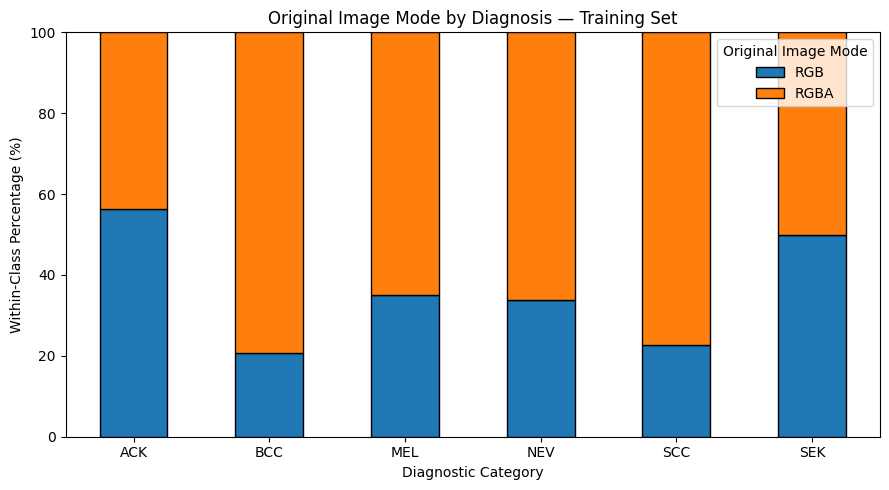


Image-format bias audit completed!
No models retrained or modified.
Held-out test set not accessed.


In [40]:
# SUPPLEMENTARY ETHICS AND BIAS ASSESSMENT
# Image-Format Bias Audit


import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# 1. Read original image modes from training images


format_records = []

for _, row in train_df.iterrows():

    img_id = str(row["img_id"])

    if not img_id.lower().endswith(".png"):
        img_id += ".png"

    image_path = image_lookup[img_id]

    with Image.open(image_path) as image:
        original_mode = image.mode

    format_records.append({
        "img_id": row["img_id"],
        "diagnostic": row["diagnostic"],
        "Image Mode": original_mode
    })

format_audit_df = pd.DataFrame(format_records)

assert len(format_audit_df) == len(train_df)
assert format_audit_df["img_id"].is_unique
assert format_audit_df["Image Mode"].notna().all()

print("IMAGE-FORMAT BIAS AUDIT")
print("=" * 65)
print("Training images examined:", len(format_audit_df))

# 2. Compare image modes across diagnoses


mode_counts = pd.crosstab(
    format_audit_df["diagnostic"],
    format_audit_df["Image Mode"]
).reindex(
    index=classes,
    columns=["RGB", "RGBA"],
    fill_value=0
)

assert mode_counts.to_numpy().sum() == len(train_df)

mode_percentages = (
    mode_counts.div(
        mode_counts.sum(axis=1),
        axis=0
    ) * 100
)

print("\nIMAGE MODE COUNTS BY DIAGNOSIS")
print("=" * 65)
print(mode_counts.to_string())

print("\nIMAGE MODE PERCENTAGES BY DIAGNOSIS")
print("=" * 65)
print(mode_percentages.round(2).to_string())

# 3. Plot class-specific image mode proportions


ax = mode_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    edgecolor="black"
)

ax.set_title(
    "Original Image Mode by Diagnosis — Training Set"
)
ax.set_xlabel("Diagnostic Category")
ax.set_ylabel("Within-Class Percentage (%)")
ax.set_ylim(0, 100)

plt.xticks(rotation=0)
plt.legend(title="Original Image Mode")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "image_mode_by_diagnosis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 4. Save reproducible results


format_audit_df.to_csv(
    RESULTS_DIR / "training_image_mode_audit.csv",
    index=False
)

mode_counts.to_csv(
    RESULTS_DIR / "image_mode_counts_by_diagnosis.csv"
)

mode_percentages.to_csv(
    RESULTS_DIR / "image_mode_percentages_by_diagnosis.csv"
)

print("\nImage-format bias audit completed!")
print("No models retrained or modified.")
print("Held-out test set not accessed.")



In [41]:
# SUPPLEMENTARY ROBUSTNESS ASSESSMENT
# Gated-Fusion Training Stability Across Random Seeds


import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, balanced_accuracy_score

# 1. Prepare the same training inputs as the original model


stability_seeds = [11, 23, 42, 67, 101]

assert int(FINAL_EPOCHS) == 4
assert np.array_equal(
    final_classes, np.sort(np.unique(y_train))
)

class_to_idx = {
    label: i for i, label in enumerate(final_classes)
}

encoded_labels = np.array(
    [class_to_idx[label] for label in y_train],
    dtype=np.int64
)

stability_dataset = TensorDataset(
    torch.as_tensor(
        X_train_img_scaled, dtype=torch.float32
    ),
    torch.as_tensor(
        X_train_meta_final, dtype=torch.float32
    ),
    torch.as_tensor(
        encoded_labels, dtype=torch.long
    )
)

# Preserve original trained-model predictions
original_gated_predictions = np.asarray(
    y_val_pred_gated
).copy()

# Preserve CPU random state
original_rng_state = torch.random.get_rng_state()

stability_results = []

print("GATED-FUSION RANDOM-SEED STABILITY")
print("=" * 70)


# 2. Train independent models with fixed hyperparameters


for seed in stability_seeds:

    torch.manual_seed(seed)

    generator = torch.Generator().manual_seed(seed)

    loader = DataLoader(
        stability_dataset,
        batch_size=64,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    # Fresh copy of the identical architecture
    stability_model = MetadataGatedFusion(
        image_dim=X_train_img_scaled.shape[1],
        metadata_dim=X_train_meta_final.shape[1],
        num_classes=len(final_classes)
    ).to(device)

    criterion = nn.CrossEntropyLoss(
        weight=torch.as_tensor(
            final_class_weights,
            dtype=torch.float32,
            device=device
        )
    )

    optimizer = torch.optim.Adam(
        stability_model.parameters(),
        lr=0.001,
        weight_decay=0.001
    )

    # Same four epochs for every seed
    for epoch in range(FINAL_EPOCHS):

        stability_model.train()

        for image_batch, meta_batch, labels in loader:

            image_batch = image_batch.to(device)
            meta_batch = meta_batch.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = stability_model(
                image_batch, meta_batch
            )

            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

    
    # 3. Assess training and validation performance
    

    train_predictions, _ = gated_predict(
        stability_model,
        X_train_img_scaled,
        X_train_meta_final
    )

    val_predictions, _ = gated_predict(
        stability_model,
        X_val_img_scaled,
        X_val_meta_final
    )

    train_f1 = f1_score(
        y_train,
        train_predictions,
        labels=final_classes,
        average="macro",
        zero_division=0
    )

    validation_f1 = f1_score(
        y_val,
        val_predictions,
        labels=final_classes,
        average="macro",
        zero_division=0
    )

    validation_balanced = balanced_accuracy_score(
        y_val, val_predictions
    )

    stability_results.append({
        "Seed": seed,
        "Epochs": FINAL_EPOCHS,
        "Train Macro-F1": train_f1,
        "Validation Macro-F1": validation_f1,
        "Validation Balanced Accuracy": validation_balanced,
        "Train-Val F1 Gap": train_f1 - validation_f1
    })

    print(
        f"Seed {seed}: "
        f"train F1={train_f1:.4f}, "
        f"validation F1={validation_f1:.4f}"
    )

# Restore CPU random state
torch.random.set_rng_state(original_rng_state)


# 4. Summarise stability


stability_df = pd.DataFrame(stability_results)

print("\nINDIVIDUAL SEED RESULTS")
print("=" * 70)
print(stability_df.round(4).to_string(index=False))

print("\nSTABILITY SUMMARY")
print("=" * 70)

print(
    "Mean validation macro-F1:",
    round(stability_df["Validation Macro-F1"].mean(), 4)
)

print(
    "Standard deviation:",
    round(stability_df["Validation Macro-F1"].std(), 4)
)

print(
    "Lowest validation macro-F1:",
    round(stability_df["Validation Macro-F1"].min(), 4)
)

print(
    "Highest validation macro-F1:",
    round(stability_df["Validation Macro-F1"].max(), 4)
)

print(
    "Mean train-validation F1 gap:",
    round(stability_df["Train-Val F1 Gap"].mean(), 4)
)

print(
    "\nOriginal locked gated model validation macro-F1:",
    round(val_metrics_gated["Macro-F1"], 4)
)


# 5. Confirm original model remains unchanged


original_recheck, _ = gated_predict(
    gated_final,
    X_val_img_scaled,
    X_val_meta_final
)

assert np.array_equal(
    original_recheck,
    original_gated_predictions
)

print("Original gated model: UNCHANGED")


# 6. Save robustness results


stability_df.to_csv(
    RESULTS_DIR / "gated_random_seed_stability.csv",
    index=False
)

print("\nRandom-seed stability experiment completed!")
print("Held-out test set not accessed.")


GATED-FUSION RANDOM-SEED STABILITY
Seed 11: train F1=0.8912, validation F1=0.5694
Seed 23: train F1=0.8846, validation F1=0.5486
Seed 42: train F1=0.9033, validation F1=0.5258
Seed 67: train F1=0.9069, validation F1=0.5296
Seed 101: train F1=0.8959, validation F1=0.5483

INDIVIDUAL SEED RESULTS
 Seed  Epochs  Train Macro-F1  Validation Macro-F1  Validation Balanced Accuracy  Train-Val F1 Gap
   11       4          0.8912               0.5694                        0.6041            0.3217
   23       4          0.8846               0.5486                        0.6126            0.3360
   42       4          0.9033               0.5258                        0.5431            0.3775
   67       4          0.9069               0.5296                        0.5439            0.3773
  101       4          0.8959               0.5483                        0.5776            0.3476

STABILITY SUMMARY
Mean validation macro-F1: 0.5444
Standard deviation: 0.0175
Lowest validation macro-F1: 0.5

In [42]:
# REPRODUCIBILITY — MODEL VERIFICATION
# Saved-Model Reload and Prediction Verification

import json
import joblib
import hashlib
import numpy as np
import pandas as pd
import torch


# 1. Reload the previously saved models


saved_metadata = joblib.load(
    MODEL_DIR / "metadata_baseline.joblib"
)

saved_image_baseline = joblib.load(
    MODEL_DIR / "image_baseline.joblib"
)

saved_metadata_tuned = joblib.load(
    MODEL_DIR / "metadata_tuned.joblib"
)

saved_image_tuned = joblib.load(
    MODEL_DIR / "image_tuned.joblib"
)

saved_early = joblib.load(
    MODEL_DIR / "early_fusion.joblib"
)

saved_late = joblib.load(
    MODEL_DIR / "late_fusion.joblib"
)

saved_gated_preprocessing = joblib.load(
    MODEL_DIR / "intermediate_gated_preprocessing.joblib"
)

saved_gated_checkpoint = torch.load(
    MODEL_DIR / "intermediate_gated_fusion.pt",
    map_location=device,
    weights_only=True
)

print("SAVED MODEL RELOAD AUDIT")
print("=" * 65)
print("All saved model files loaded successfully.")


# 2. Reconstruct the gated model from its checkpoint


reloaded_gated = MetadataGatedFusion(
    image_dim=int(saved_gated_checkpoint["image_dim"]),
    metadata_dim=int(saved_gated_checkpoint["metadata_dim"]),
    num_classes=int(saved_gated_checkpoint["num_classes"])
).to(device)

reloaded_gated.load_state_dict(
    saved_gated_checkpoint["model_state_dict"]
)

reloaded_gated.eval()

assert np.array_equal(
    np.asarray(saved_gated_checkpoint["classes"]),
    final_classes
)

assert int(saved_gated_checkpoint["epochs"]) == FINAL_EPOCHS

# Use the saved preprocessing objects, not current fitted objects
reloaded_gated_images = (
    saved_gated_preprocessing["image_scaler"]
    .transform(X_val_img)
    .astype(np.float32)
)

reloaded_gated_metadata = (
    saved_gated_preprocessing["metadata_preprocessor"]
    .transform(X_val_metadata)
    .astype(np.float32)
)


# 3. Generate independent predictions from reloaded files


reloaded_predictions = {
    "Original Metadata": (
        saved_metadata["classifier"].predict(
            saved_metadata["preprocessor"].transform(
                X_val_metadata
            )
        )
    ),
    "Tuned Metadata": (
        saved_metadata_tuned.predict(X_val_metadata)
    ),
    "Original Image": (
        saved_image_baseline.predict(X_val_img)
    ),
    "Tuned Image": (
        saved_image_tuned.predict(X_val_img)
    ),
    "Early Fusion": (
        saved_early.predict(X_val_early)
    )
}

# Reconstruct saved late-fusion probabilities
saved_image_probs = (
    saved_late["image_model"].predict_proba(X_val_img)
)

saved_metadata_probs = (
    saved_late["metadata_model"]
    .predict_proba(X_val_metadata)
)

assert np.array_equal(
    saved_late["image_model"].classes_,
    saved_late["metadata_model"].classes_
)

saved_late_probs = (
    saved_late["image_weight"] * saved_image_probs +
    saved_late["metadata_weight"] * saved_metadata_probs
)

reloaded_predictions["Late Fusion"] = (
    np.asarray(saved_late["classes"])[
        np.argmax(saved_late_probs, axis=1)
    ]
)

# Reconstruct gated predictions from saved checkpoint
reloaded_gated_preds, reloaded_gated_probs = gated_predict(
    reloaded_gated,
    reloaded_gated_images,
    reloaded_gated_metadata
)

reloaded_predictions["Intermediate Gated"] = (
    reloaded_gated_preds
)


# 4. Verify reloaded predictions against saved CSV files


saved_prediction_files = {
    "Original Metadata": "metadata_validation_predictions.csv",
    "Tuned Metadata": "metadata_tuned_validation_predictions.csv",
    "Original Image": "image_validation_predictions.csv",
    "Tuned Image": "image_tuned_validation_predictions.csv",
    "Early Fusion": "early_fusion_validation_predictions.csv",
    "Late Fusion": "late_fusion_validation_predictions.csv",
    "Intermediate Gated": "intermediate_fusion_validation_predictions.csv"
}

audit_records = []

print("\nRELOADED MODEL PREDICTION VERIFICATION")
print("=" * 65)

for model_name, filename in saved_prediction_files.items():

    saved_csv = pd.read_csv(RESULTS_DIR / filename)

    predictions = np.asarray(
        reloaded_predictions[model_name]
    )

    assert len(predictions) == len(validation_df)

    assert np.array_equal(
        saved_csv["img_id"].astype(str).values,
        validation_df["img_id"].astype(str).values
    ), f"Image alignment failed: {model_name}"

    assert np.array_equal(
        saved_csv["Actual"].values,
        y_val
    ), f"Label alignment failed: {model_name}"

    assert np.array_equal(
        predictions,
        saved_csv["Predicted"].values
    ), f"Reloaded prediction mismatch: {model_name}"

    audit_records.append({
        "Model": model_name,
        "Validation Images": len(predictions),
        "Predictions Match": True
    })

    print(f"{model_name}: PASSED ({len(predictions)} images)")


# 5. Verify saved fusion probabilities


assert np.allclose(
    saved_late_probs,
    late_probabilities,
    atol=1e-6
), "Late-fusion probabilities differ"

assert np.allclose(
    reloaded_gated_probs,
    val_probs_gated,
    atol=1e-6
), "Gated-fusion probabilities differ"

print("\nFusion probability reconstruction: PASSED")


# 6. Record model-file fingerprints


model_file_names = [
    "metadata_baseline.joblib",
    "image_baseline.joblib",
    "metadata_tuned.joblib",
    "image_tuned.joblib",
    "early_fusion.joblib",
    "late_fusion.joblib",
    "intermediate_gated_fusion.pt",
    "intermediate_gated_preprocessing.joblib"
]

model_hashes = {}

for filename in model_file_names:

    file_path = MODEL_DIR / filename

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    model_hashes[filename] = sha256.hexdigest()


# 7. Save reproducibility verification results


audit_df = pd.DataFrame(audit_records)

audit_df.to_csv(
    RESULTS_DIR / "saved_model_reload_audit.csv",
    index=False
)

reload_manifest = {
    "dataset": "PAD-UFES-20",
    "validation_images_verified": int(len(y_val)),
    "models_verified": len(reloaded_predictions),
    "all_predictions_match": True,
    "fusion_probabilities_match": True,
    "model_file_sha256": model_hashes,
    "test_set_used": False
}

with open(
    RESULTS_DIR / "saved_model_reload_manifest.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(reload_manifest, file, indent=4)

print("\nSAVED-MODEL REPRODUCIBILITY AUDIT COMPLETED!")
print("Seven validation prediction checks passed.")
print("No models retrained or modified.")
print("Held-out test set not accessed.")


SAVED MODEL RELOAD AUDIT
All saved model files loaded successfully.

RELOADED MODEL PREDICTION VERIFICATION
Original Metadata: PASSED (329 images)
Tuned Metadata: PASSED (329 images)
Original Image: PASSED (329 images)
Tuned Image: PASSED (329 images)
Early Fusion: PASSED (329 images)
Late Fusion: PASSED (329 images)
Intermediate Gated: PASSED (329 images)

Fusion probability reconstruction: PASSED

SAVED-MODEL REPRODUCIBILITY AUDIT COMPLETED!
Seven validation prediction checks passed.
No models retrained or modified.
Held-out test set not accessed.


In [43]:
# REPRODUCIBILITY — SOFTWARE ENVIRONMENT
# Software Environment and Dependency Manifest


import sys
import json
import hashlib
import platform
import importlib.metadata as metadata


# 1. Record library versions from this computer


required_packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "Pillow",
    "torch",
    "torchvision",
    "joblib"
]

package_versions = {
    package: metadata.version(package)
    for package in required_packages
}

print("PROJECT SOFTWARE ENVIRONMENT")
print("=" * 65)

print("Python:", platform.python_version())
print("Operating system:", platform.system())
print("Processor architecture:", platform.machine())
print("PyTorch device:", device)

for package, version in package_versions.items():
    print(f"{package}: {version}")


# 2. Verify original dataset partition fingerprint


split_sha256 = hashlib.sha256(
    SPLIT_PATH.read_bytes()
).hexdigest()

expected_sha256 = (
    "b6f17fa5efecc2507e4df7f8a0cee14"
    "dda97824c4425a0dcc0c2948173d99c32"
)

assert split_sha256 == expected_sha256

print("\nCanonical dataset split: VERIFIED")
print("SHA-256:", split_sha256)


# 3. Create environment manifest



environment_manifest = {
    "project": "COMP1013 Project 2.2",
    "dataset": "PAD-UFES-20",
    "python_version": platform.python_version(),
    "operating_system": platform.system(),
    "architecture": platform.machine(),
    "device": str(device),
    "random_seed": 42,
    "packages": package_versions,
    "image_processing": {
        "size": [224, 224],
        "convert_to_rgb": True,
        "normalization_mean": IMAGE_MEAN,
        "normalization_std": IMAGE_STD,
        "augmentation": False
    },
    "image_encoder": {
        "architecture": "EfficientNet-B0",
        "weights": "IMAGENET1K_V1",
        "frozen": True,
        "embedding_dimensions": 1280
    },
    "metadata_features": metadata_features,
    "metadata_encoded_dimensions": 27,
    "split_file": SPLIT_PATH.name,
    
    "split_sha256": split_sha256,
    "heldout_test_evaluated": True,
    "models_changed_after_test": False
}

manifest_file = (
    RESULTS_DIR / "environment_manifest.json"
)

with open(
    manifest_file,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        environment_manifest,
        file,
        indent=4
    )


#4. Save direct dependency requirements


# Strip platform-specific local build identifiers such as
# '+cpu' from the portable requirements specification.


# The exact installed versions remain in the JSON manifest.

requirements_lines = []

for package, version in package_versions.items():

    portable_version = version.split("+")[0]

    requirements_lines.append(
        f"{package}=={portable_version}"
    )

requirements_file = (
    PROJECT_DIR / "requirements_project2_2.txt"
)

with open(
    requirements_file,
    "w",
    encoding="utf-8"
) as file:
    file.write(
        "\n".join(requirements_lines) + "\n"
    )

# 5. Verify generated files


assert manifest_file.is_file()
assert requirements_file.is_file()

with open(
    manifest_file,
    encoding="utf-8"
) as file:
    saved_manifest = json.load(file)

assert saved_manifest["split_sha256"] == expected_sha256
assert saved_manifest["image_encoder"]["embedding_dimensions"] == 1280
assert saved_manifest["metadata_encoded_dimensions"] == 27

print("\nREPRODUCIBILITY FILES")
print("=" * 65)

print("Environment manifest:", manifest_file.name)
print("Dependencies:", requirements_file.name)

print("\nDIRECT PYTHON REQUIREMENTS")
print("=" * 65)
print(requirements_file.read_text(encoding="utf-8"))

print("Software environment documentation completed!")
print("Existing models and predictions unchanged.")


PROJECT SOFTWARE ENVIRONMENT
Python: 3.9.13
Operating system: Windows
Processor architecture: AMD64
PyTorch device: cpu
numpy: 1.26.4
pandas: 2.3.3
scikit-learn: 1.4.2
matplotlib: 3.9.4
Pillow: 11.3.0
torch: 2.8.0
torchvision: 0.23.0
joblib: 1.2.0

Canonical dataset split: VERIFIED
SHA-256: b6f17fa5efecc2507e4df7f8a0cee14dda97824c4425a0dcc0c2948173d99c32

REPRODUCIBILITY FILES
Environment manifest: environment_manifest.json
Dependencies: requirements_project2_2.txt

DIRECT PYTHON REQUIREMENTS
numpy==1.26.4
pandas==2.3.3
scikit-learn==1.4.2
matplotlib==3.9.4
Pillow==11.3.0
torch==2.8.0
torchvision==0.23.0
joblib==1.2.0

Software environment documentation completed!
Existing models and predictions unchanged.


In [44]:
# CONTROLLED MODALITY SCALING ABLATION
# Original early fusion vs dimension-balanced early fusion
# Training patient-grouped CV only — NO TEST ACCESS


import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score

# Preserve the original fitted classifier and preprocessing
original_preprocessor = early_model.named_steps["preprocessor"]

original_classifier = early_model.named_steps["classifier"]

print("CONTROLLED EARLY-FUSION SCALING EXPERIMENT")
print("=" * 70)
print("Original regularisation C:",
      original_classifier.get_params()["C"])

assert original_classifier.get_params()["C"] == 0.01
assert X_train_early.shape == (1640, 1286)
assert len(y_train) == 1640

groups = train_df["patient_id"].to_numpy()

labels = np.asarray(y_train)

cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

scaling_ratios = [0.5, 1.0, 2.0]

records = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train_early, labels, groups),
    start=1
):

    assert set(groups[train_idx]).isdisjoint(
        set(groups[val_idx])
    )

    # Fit preprocessing using this fold's training data
    processor = clone(original_preprocessor)

    X_fold_train = np.asarray(
        processor.fit_transform(
            X_train_early.iloc[train_idx]
        ),
        dtype=np.float64
    )

    X_fold_val = np.asarray(
        processor.transform(
            X_train_early.iloc[val_idx]
        ),
        dtype=np.float64
    )

    image_dim = X_train_img.shape[1]
    metadata_dim = X_fold_train.shape[1] - image_dim

    assert image_dim == 1280
    assert metadata_dim > 0

    
    
    # A. Original early-fusion method
    baseline = clone(original_classifier)

    baseline.fit(
        X_fold_train,
        labels[train_idx]
    )

    baseline_predictions = baseline.predict(X_fold_val)

    baseline_score = f1_score(
        labels[val_idx],
        baseline_predictions,
        labels=classes,
        average="macro",
        zero_division=0
    )

    records.append({
        "Fold": fold,
        "Configuration": "Original",
        "Macro-F1": baseline_score
    })
    
    

    # B. Dimension-balanced feature blocks
    
    for ratio in scaling_ratios:

        scaled_train = X_fold_train.copy()
        scaled_val = X_fold_val.copy()

        scaled_train[:, :image_dim] /= np.sqrt(image_dim)
        scaled_val[:, :image_dim] /= np.sqrt(image_dim)

        metadata_scale = ratio / np.sqrt(metadata_dim)

        scaled_train[:, image_dim:] *= metadata_scale
        scaled_val[:, image_dim:] *= metadata_scale

        model = clone(original_classifier)

        model.fit(
            scaled_train,
            labels[train_idx]
        )

        predictions = model.predict(scaled_val)

        score = f1_score(
            labels[val_idx],
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )

        records.append({
            "Fold": fold,
            "Configuration": f"Balanced ratio={ratio}",
            "Macro-F1": score
        })

    print(f"Fold {fold}: completed")

# Summarise the paired patient-fold comparisons

results = pd.DataFrame(records)

summary = (
    results.groupby("Configuration")
    .agg(
        Mean_F1=("Macro-F1", "mean"),
        Std_F1=("Macro-F1", "std")
    )
    .reset_index()
    .sort_values("Mean_F1", ascending=False)
)

print("\nSCALING EXPERIMENT RESULTS")
print("=" * 70)
print(summary.round(4).to_string(index=False))

fold_table = results.pivot(
    index="Fold",
    columns="Configuration",
    values="Macro-F1"
)

print("\nSCORES BY PATIENT-GROUPED FOLD")
print("=" * 70)
print(fold_table.round(4).to_string())

original_fold_scores = fold_table["Original"]

print("\nDIFFERENCES VS ORIGINAL")
print("=" * 70)

for configuration in fold_table.columns:
    if configuration == "Original":
        continue

    differences = (
        fold_table[configuration] - original_fold_scores
    )

    print(
        f"{configuration}: "
        f"mean difference={differences.mean():+.4f}; "
        f"improved folds={(differences > 0).sum()}/4"
    )

results.to_csv(
    RESULTS_DIR / "scaling_ablation_folds.csv",
    index=False
)

summary.to_csv(
    RESULTS_DIR / "scaling_ablation_summary.csv",
    index=False
)

print("\nOriginal models: UNCHANGED")
print("Validation set: NOT ACCESSED")
print("Test set: NOT ACCESSED")
print("Controlled scaling ablation completed.")


CONTROLLED EARLY-FUSION SCALING EXPERIMENT
Original regularisation C: 0.01
Fold 1: completed
Fold 2: completed
Fold 3: completed
Fold 4: completed

SCALING EXPERIMENT RESULTS
     Configuration  Mean_F1  Std_F1
          Original   0.5758  0.0483
Balanced ratio=1.0   0.5265  0.0398
Balanced ratio=2.0   0.5198  0.0241
Balanced ratio=0.5   0.4710  0.0286

SCORES BY PATIENT-GROUPED FOLD
Configuration  Balanced ratio=0.5  Balanced ratio=1.0  Balanced ratio=2.0  Original
Fold                                                                               
1                          0.4339              0.4766              0.4968    0.5270
2                          0.4699              0.5128              0.5319    0.5548
3                          0.4766              0.5539              0.5477    0.5813
4                          0.5034              0.5628              0.5029    0.6402

DIFFERENCES VS ORIGINAL
Balanced ratio=0.5: mean difference=-0.1049; improved folds=0/4
Balanced ratio=1.0: 


### Supplementary Ablation: Modality Feature Scaling

A supplementary experiment investigated whether balancing image
and metadata feature blocks by their dimensions improved
early-fusion classification.

Four-fold stratified patient-grouped cross-validation was
performed using training data only. The original logistic
regression regularisation parameter (C=0.01) was retained.

The original configuration achieved mean macro-F1 of 0.5758,
compared with 0.5265, 0.5198 and 0.4710 for dimensionality-
balanced metadata ratios of 1.0, 2.0 and 0.5 respectively.

Every balanced configuration performed worse than the
original across all four patient-grouped folds.

These findings suggest that the original feature scaling
was more effective under the evaluated settings.
They do not establish that alternative scaling strategies
would be ineffective with different regularisation strengths.

The original early-fusion model was preserved. No
validation or held-out test observations were accessed
during this supplementary experiment.

This investigation was conducted after the initial
held-out test evaluation and is reported as exploratory
analysis, not as independent confirmatory evidence.



## Final Evaluation and Critical Reflection

### 1. Evaluation Protocol

The project evaluates six-class skin lesion classification
using macro-F1 as the primary metric, supported by accuracy,
balanced accuracy, per-class recall and confusion matrices.

Models were developed using 1,640 training images and
329 validation images, with patient-grouped cross-validation
where applicable.

Late fusion was selected as the primary model using
validation macro-F1 before the held-out test evaluation.

The 329-image test set, representing 197 independent patients,
was evaluated only after model configurations were locked.
No models were retuned after inspecting test performance.

### 2. Validation and Test Performance

| Model | Validation Macro-F1 | Test Macro-F1 |
|---|---:|---:|
| Original Metadata | 0.5252 | 0.4215 |
| Tuned Metadata | 0.4335 | 0.4244 |
| Tuned Image | 0.5166 | 0.5298 |
| Early Fusion | 0.5766 | **0.5542** |
| Late Fusion | **0.5794** | 0.5273 |
| Intermediate Gated | 0.5670 | 0.5413 |

Late fusion achieved the highest validation macro-F1
(0.5794) and was therefore selected as the primary model.

However, early fusion achieved the highest observed
test macro-F1 (0.5542), followed by intermediate gated
fusion (0.5413).

The preselected late-fusion model achieved test macro-F1
of 0.5273, although it produced the highest test accuracy
(0.6565) and malignant-versus-other-class ROC-AUC (0.8938).

These findings demonstrate that different evaluation
metrics can favour different fusion strategies.

Importantly, the primary model was not changed after
test evaluation. Early fusion is reported as the strongest
observed test performer, not as a newly selected model.

### 3. Comparison with the Tuned Unimodal Baseline

The strongest equally tuned unimodal baseline was the
image-only classifier, with test macro-F1 of 0.5298.

Early fusion improved test macro-F1 by 0.0245.

A paired patient-level bootstrap produced a 95% interval
of [0.0044, 0.0501] for this difference.

This provides exploratory evidence of a modest improvement
from combining visual and clinical information.

However, several model comparisons were examined and
the intervals were not adjusted for multiple comparisons.
The finding should not be interpreted as definitive proof
of superiority across other patient populations.

Late fusion and gated fusion did not establish a clear
test macro-F1 improvement over the tuned image-only model.

### 4. Patient-Level Statistical Uncertainty

Patient-clustered bootstrap resampling was used because
multiple images can belong to the same patient.

The 95% bootstrap intervals for test macro-F1 were:

- Early fusion: [0.4551, 0.6449]
- Late fusion: [0.4473, 0.6068]
- Intermediate gated: [0.4468, 0.6292]
- Tuned image-only: [0.4326, 0.6217]

The paired test difference between late and early fusion
was -0.0269, with a 95% interval of [-0.1027, 0.0281].

Because this interval includes zero, the test results
do not establish a clear difference between these two
fusion approaches.

The test partition contained only seven melanoma images.
This makes melanoma-specific estimates particularly
uncertain and limits the strength of clinical conclusions.

### 5. Class-Specific and Clinical Performance

The test partition contained:

- ACK: 104 images
- BCC: 121 images
- MEL: 7 images
- NEV: 35 images
- SCC: 28 images
- SEK: 34 images

Despite competitive overall results, minority-class
detection remained a major weakness.

For late fusion:

- Melanoma recall: 0.1429 (1 of 7 detected)
- SCC recall: 0.2857 (8 of 28 detected)

For early fusion:

- Melanoma recall: 0.2857 (2 of 7 detected)
- SCC recall: 0.2857 (8 of 28 detected)

These results are insufficient for reliable clinical
diagnosis, particularly for potentially dangerous lesions.

A supplementary binary evaluation grouped BCC, MEL and
SCC as malignant target classes, while ACK, NEV and SEK
formed the comparison group.

ACK is premalignant, so this comparison group must not
be described as entirely benign.

Early fusion achieved malignant-target sensitivity
of 0.7692, compared with 0.7244 for late fusion.

Binary sensitivity does not replace six-class evaluation:
a malignant lesion can be correctly identified as malignant
while still receiving the wrong specific diagnosis.

### 6. Overfitting and Model Stability

Overfitting was particularly evident in image-only and
intermediate gated models.

The tuned image-only classifier achieved training
macro-F1 of 0.9656 but validation macro-F1 of 0.5166.

The final gated model achieved training macro-F1 of
approximately 0.9048 and validation macro-F1 of 0.5670.

Five additional gated training runs produced:

- Mean validation macro-F1: 0.5444
- Standard deviation: 0.0175
- Mean training–validation macro-F1 gap: 0.3520

These findings indicate a substantial generalisation
problem and some sensitivity to training randomness.

The limited number of training examples, high-dimensional
image embeddings and small minority classes likely
contribute to these difficulties.

### 7. Modality Contribution Analysis

A repeated permutation analysis investigated the
dependence of early fusion on each modality.

Original validation macro-F1 was 0.5766.

- Permuting image embeddings reduced mean macro-F1
  to 0.1975.
- Permuting clinical metadata reduced mean macro-F1
  to 0.5165.

Early fusion therefore appeared substantially more
sensitive to disruptions in visual information.

Clinical metadata provided an additional contribution,
but the model relied predominantly on image embeddings.

Permutation creates unnatural image–metadata pairings,
so this analysis measures predictive sensitivity rather
than causal feature importance.

### 8. Data Bias and Robustness

The training dataset contained 575 records (35.06%)
with 11 questionnaire fields missing simultaneously.

This missingness was associated with diagnosis,
creating a risk of documentation-related shortcut learning.

Additional metadata ablations showed that expanded
features could improve validation performance, but
potential shortcut information made those gains difficult
to interpret as robust clinical improvements.

Original image formats also varied by diagnosis:

- ACK: 43.68% RGBA
- BCC: 79.27% RGBA
- SCC: 77.21% RGBA

Although all images were converted to RGB before model
input, this does not guarantee the removal of every
image-processing or acquisition-related artefact.

These observations indicate potential dataset bias.
They do not prove that the trained models used such
artefacts to make predictions.

### 9. Computational and Methodological Limitations

The frozen EfficientNet-B0 encoder made CPU-based
experimentation practical by allowing image embeddings
to be extracted once and reused.

However, this approach prevented task-specific
fine-tuning of the visual backbone.

Training-time image augmentation was also not applied,
limiting assessment of robustness to image variation.

Runtime measurements for classification on cached
embeddings exclude the separate image-extraction cost.
They should therefore not be presented as full
end-to-end inference times.

Other limitations include the small melanoma sample,
class imbalance, potential metadata shortcuts, limited
demographic representation and lack of external
clinical validation.

### 10. Overall Interpretation

The experiments suggest that multimodal information
can improve six-class classification performance,
particularly through early feature-level fusion.

However, the benefits were modest and not consistent
across all fusion strategies.

Late fusion performed best during validation-based
selection, while early fusion performed best on the
held-out test set.

Substantial overfitting, unstable minority-class estimates
and poor melanoma and SCC recall prevent any claim
of clinical readiness.

The primary contribution is a reproducible, patient-aware
comparison of unimodal and multimodal techniques,
including uncertainty, failure analysis and dataset-bias
investigations.



## Ethics, Responsible AI and Reproducibility

### 1. Ethical Considerations

This project uses the publicly available PAD-UFES-20
skin lesion dataset for an educational research task.

The dataset publication reports ethical approval and
informed consent. However, the availability of a
research dataset does not establish that the resulting
models are safe for clinical use.

The implementation does not provide medical advice
or a validated diagnostic tool.

### 2. Dataset Bias and Fairness

Several limitations may affect model fairness and
generalisation.

**Class imbalance:** Only 52 of the 2,298 photographs
represent melanoma. The test partition contains just
seven melanoma images, making class-specific results
highly uncertain.

**Clinical documentation bias:** Eleven questionnaire
fields were simultaneously missing in 575 training
records. Missingness was strongly associated with
diagnosis and biopsy status.

**Image acquisition bias:** Original RGB/RGBA image
formats were unevenly distributed across diagnoses,
suggesting a possible image-processing shortcut.

**Demographic representation:** The dataset does not
support a reliable assessment of fairness across all
skin tones. The Fitzpatrick-related field is missing
for a substantial fraction of training records.

Exploratory age and anatomical-region subgroup
analyses showed differences in model sensitivity,
but small subgroup counts and possible confounding
prevent strong fairness conclusions.

Excluding potentially problematic metadata reduces
some risks but cannot guarantee unbiased predictions.

### 3. Clinical Safety and Limitations

The models showed inadequate performance on important
minority classes.

In the held-out test set, the preselected late-fusion
classifier correctly identified only one of seven
melanoma images as melanoma.

Such errors could be harmful in a clinical setting.

Before any real-world consideration, future work
would require:

- Larger and more representative datasets.
- External validation on independent populations.
- Assessment across skin tones and clinical settings.
- Improved melanoma and SCC sensitivity.
- Probability calibration and clinical risk analysis.
- Appropriate clinician oversight and regulatory review.

No clinical deployment is recommended based on
the current results.

### 4. Reproducibility

Experiments were implemented using Python, PyTorch,
Torchvision and Scikit-learn.

The project preserves the original patient-disjoint
dataset split and records its SHA-256 fingerprint:

`b6f17fa5efecc2507e4df7f8a0cee14dda97824c4425a0dcc0c2948173d99c32`

The experimental environment is documented in:

- `requirements_project2_2.txt`
- `environment_manifest.json`

Additional reproducibility files record patient-split
integrity, model configurations, results and saved-model
file checksums.

Seven saved model configurations were successfully
reloaded and independently reproduced their original
predictions on all 329 validation images.

Both late-fusion and gated-fusion prediction
probabilities were also reproduced.

This verifies model persistence in the existing
environment. It does not constitute a full independent
reproduction on a newly configured computer.

Random seeds were controlled where applicable,
although exact numerical reproducibility may vary
across hardware, library builds and computational
backends.

The original clinical images and patient-level data
should not be included directly in a public GitHub
repository. Dataset access and licensing information
should instead be documented in the README.

### 5. Final Conclusion

This project compared metadata-only, image-only,
early-fusion, late-fusion and metadata-guided gated
classification approaches on PAD-UFES-20.

The primary late-fusion model was selected using
validation performance before the held-out test
evaluation.

Early fusion subsequently achieved the highest
observed test macro-F1 of 0.5542, compared with
0.5298 for the tuned image-only baseline.

A paired patient-level bootstrap indicated a modest
early-fusion improvement of 0.0245, with a 95%
interval of [0.0044, 0.0501].

This finding is exploratory because several model
comparisons were examined.

The experiments show that clinical metadata can
provide complementary information to visual
embeddings, but the benefit depends on the fusion
strategy and evaluation metric.

Class imbalance, substantial overfitting,
dataset-related shortcuts and poor minority-class
recall remain significant limitations.

The principal contribution is a transparent,
patient-aware and reproducible comparison of
multimodal learning approaches, rather than a
clinically deployable prediction system.

### References

Pacheco et al. (2020). PAD-UFES-20: A skin lesion
dataset composed of patient data and clinical
images collected from smartphones. Data in Brief.
https://doi.org/10.1016/j.dib.2020.106221

Pacheco, A. G. C., & Krohling, R. A. (2021).
An attention-based mechanism to combine images
and metadata in deep learning models applied to
skin cancer classification.
IEEE Journal of Biomedical and Health Informatics,
25(9), 3554–3563.
https://doi.org/10.1109/JBHI.2021.3062002

Tan and Le (2019). EfficientNet: Rethinking Model
Scaling for Convolutional Neural Networks.
Proceedings of ICML.
https://arxiv.org/abs/1905.11946
